# ST1504 Deep Learning - CA2 Part A
## GAN/VAE Image Generation using CIFAR10

This notebook builds generative deep learning models that learn the visual distribution of CIFAR10 and generate new CIFAR10-like images.

The task is not image classification. Instead of predicting a label from an image, the model must learn how CIFAR10 images are distributed and then create new images that look plausible. Since CIFAR10 is an RGB dataset, the model must learn colour, texture, background patterns and rough object structure together.

The workflow is:

1. Load CIFAR10 directly from `tf.keras.datasets.cifar10.load_data()`.
2. Inspect image shape, labels, class balance, pixel range, sample images and engineered image features.
3. Preprocess the same images differently for VAE and GAN output ranges.
4. Train and evaluate a baseline VAE.
5. Train and evaluate a baseline DCGAN.
6. Compare both baselines using the same visual scoring method.
7. Select the GAN direction and improve it into a Conditional DCGAN for class control.
8. Generate and evaluate 100 images per class, giving 1000 generated images.
9. Test a controlled lower-learning-rate continuation from the same checkpoint.
10. Test latent-scale sampling as a generation diagnostic.
11. Use candidate-pool selection as post-generation quality control.
12. Compare manual scoring and FID, then verify the final submission image folder.

The overall experimental journey is:

> VAE baseline -> DCGAN baseline -> choose GAN direction -> Conditional DCGAN -> controlled learning-rate investigation -> retain final model -> latent-scale diagnostic -> final 1000-image generation -> manual/FID evaluation -> post-generation quality control.

The main rule is consistent throughout the notebook:

**Training changes can improve model weights. Generation-time diagnostics and candidate selection can improve how outputs are chosen. I keep these separate so the final conclusion does not overclaim what actually changed.**


### 1.1 Background Research

Before coding the models, I first justify why GANs and VAEs fit this problem.

CIFAR10 contains small 32x32 coloured images from 10 object classes. The assignment asks for new generated images, so this is a generative modelling task rather than a normal classification task.

| Background point | Why it matters here | Decision made |
|------------------|--------------------|---------------|
| CIFAR10 images are small and coloured | the model must generate RGB image patterns, not only grayscale shapes | keep the original 32x32x3 image format |
| the task asks for new images | a discriminative CNN alone cannot create new samples | use generative models |
| a VAE learns a latent distribution | it is usually more stable and gives a useful first baseline | train a baseline VAE |
| a GAN learns through adversarial training | it can produce sharper textures than a VAE | train a baseline DCGAN |
| the final output needs 10 classes | a normal VAE or GAN does not directly control class | improve the selected model into a conditional model |

Decision: build fair baselines first, compare them using evidence, then make the selected direction conditional so specific CIFAR10 classes can be generated.

### 1.2 Evaluation Plan

Before training any model, I define how the generated images will be evaluated.

Generative image models do not have a direct accuracy score like classification models, so I use a manual image-quality scoring method.

| Score | Meaning | What I look for |
|-------|---------|-----------------|
| Clear | recognisable CIFAR10-like object or class feature | clear object shape, class cue or strong target-class pattern |
| Marginal | some useful colour, texture or rough shape, but class identity is uncertain | partial object structure or CIFAR10-like visual cues |
| Nonsense | mostly distorted or noisy output with no meaningful object structure | blobs, severe distortion or no usable class cue |

For this project, **usable** means:

> usable images = Clear images + Marginal images

This is a project-defined manual diagnostic, not an official CIFAR10 or GAN evaluation standard. I use it because the assignment output is visual, so I need a way to separate recognisable and partly useful images from samples that are too distorted to submit confidently.

I use the same scoring method to compare the baseline VAE, baseline DCGAN, final cDCGAN and selected candidate submission set. I later combine this manual review with FID, because manual recognisability and distribution similarity do not always measure the same thing.

Decision: define the evaluation method before training so later model choices are based on consistent criteria, not only after seeing the final outputs.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import math
import random
import shutil
import sys
import warnings

# Suppress non-experiment environment warnings before third-party imports.
warnings.filterwarnings(
    "ignore",
    message=".*character detection dependency.*",
)
warnings.filterwarnings("ignore", category=UserWarning)

from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

try:
    import tensorflow as tf
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "TensorFlow is required for this notebook. Select the CA2 TensorFlow kernel "
        "or install TensorFlow in the active environment before running Part A."
    ) from exc

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import Callback

# Keep notebook outputs focused on experiment evidence rather than TensorFlow environment warnings.
tf.get_logger().setLevel("ERROR")

# Reproducibility
SEED = 88
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Project folders
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "part_a_outputs"
SAMPLE_DIR = OUTPUT_DIR / "training_samples"
MODEL_DIR = OUTPUT_DIR / "models"
MANUAL_EVAL_DIR = OUTPUT_DIR / "manual_evaluation_images"
FINAL_IMAGE_DIR = OUTPUT_DIR / "generated_1000_images"
GRID_DIR = OUTPUT_DIR / "image_grids"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, SAMPLE_DIR, MODEL_DIR, MANUAL_EVAL_DIR, FINAL_IMAGE_DIR, GRID_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


def history_to_dataframe(history):
    history_df = pd.DataFrame(history.history)
    history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
    return history_df


def load_training_history(history_path):
    history_path = Path(history_path)
    if history_path.exists():
        return pd.read_csv(history_path)
    return None


def _weight_shape_list(weights):
    return [tuple(int(dim) for dim in weight.shape) for weight in weights]


def _ordered_h5_values(vars_group):
    keys = sorted(vars_group.keys(), key=lambda key: int(key) if str(key).isdigit() else str(key))
    return [vars_group[key][()] for key in keys]


def _load_keras3_h5_weights_by_shape(model, weights_path, root_group=None):
    try:
        import h5py
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            "h5py is needed to load newer Keras-style HDF5 weights in this environment."
        ) from exc

    with h5py.File(weights_path, "r") as weight_file:
        group = weight_file[root_group] if root_group is not None else weight_file
        if "layers" not in group:
            raise ValueError(f"No 'layers' group found in {weights_path}.")

        layers_group = group["layers"]
        used_groups = set()
        loaded_layers = 0

        for layer in model.layers:
            if not layer.weights:
                continue

            expected_shapes = _weight_shape_list(layer.weights)
            matched_group_name = None

            for group_name in layers_group.keys():
                if group_name in used_groups:
                    continue

                layer_group = layers_group[group_name]
                if "vars" not in layer_group:
                    continue

                saved_values = _ordered_h5_values(layer_group["vars"])
                saved_shapes = [value.shape for value in saved_values]

                if saved_shapes == expected_shapes:
                    matched_group_name = group_name
                    break

            if matched_group_name is None:
                raise ValueError(
                    f"Could not match saved weights for layer '{layer.name}' "
                    f"with expected shapes {expected_shapes}."
                )

            matched_vars = layers_group[matched_group_name]["vars"]
            layer.set_weights(_ordered_h5_values(matched_vars))
            used_groups.add(matched_group_name)
            loaded_layers += 1

    return loaded_layers


def load_weights_compat(model, weights_path, root_group=None):
    weights_path = Path(weights_path)

    try:
        model.load_weights(weights_path)
        return "loaded with standard Keras loader"
    except ValueError as exc:
        message = str(exc)
        if "Layer count mismatch" not in message and "saved layers" not in message:
            raise

        loaded_layers = _load_keras3_h5_weights_by_shape(
            model,
            weights_path,
            root_group=root_group
        )
        return f"loaded with Keras 3 HDF5 compatibility loader ({loaded_layers} weighted layers)"


def save_training_history_plot(history_df, metric_names, output_path, title):
    if history_df is None or history_df.empty:
        return None

    available_metrics = [metric for metric in metric_names if metric in history_df.columns]
    if not available_metrics:
        return None

    plt.figure(figsize=(8, 4.5))
    for metric in available_metrics:
        plt.plot(history_df["epoch"], history_df[metric], label=metric)

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    return output_path


print("TensorFlow version:", tf.__version__)
print("Project directory:", PROJECT_DIR)
print("Output directory:", OUTPUT_DIR)


TensorFlow version: 2.10.0
Project directory: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2
Output directory: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs


## 2. CIFAR10 Data Inspection

Before training a generative model, the dataset must be checked carefully.

For classification, the model learns a mapping from image to label. For generation, the model learns the image distribution itself. This means image size, channels, pixel range and class examples matter directly because they define what the generator is trying to imitate.

In [2]:
# Step 2.1: Experiment configuration
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

NUM_CLASSES = len(CLASS_NAMES)
IMG_HEIGHT = 32
IMG_WIDTH = 32
IMG_CHANNELS = 3
IMG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

BATCH_SIZE = 128
LATENT_DIM = 128

# These can be increased if more GPU time is available.
VAE_EPOCHS = 30
DCGAN_EPOCHS = 50
FINAL_CDCGAN_EPOCHS = 80

GAN_LEARNING_RATE = 2e-4
LOW_LR = 1e-4
LR_BRANCH_EPOCHS = 20

FINAL_IMAGES_PER_CLASS = 100
FINAL_TOTAL_IMAGES = FINAL_IMAGES_PER_CLASS * NUM_CLASSES

# Final model direction selected after baseline comparison.
FINAL_MODEL_TYPE = "cdcgan"

print("Image shape target:", IMG_SHAPE)
print("Number of classes:", NUM_CLASSES)
print("Final image target:", FINAL_TOTAL_IMAGES)
print("Final model type:", FINAL_MODEL_TYPE)


Image shape target: (32, 32, 3)
Number of classes: 10
Final image target: 1000
Final model type: cdcgan


### 2.0 Experiment Configuration Checkpoint

The configuration output confirms the modelling target before loading the images.

The image shape target is **32x32x3**, which matches CIFAR10 coloured images. There are **10 classes**, and the final generated-image target is **1000 images**.

This means the final conditional model should generate:

> 100 images per class x 10 classes = 1000 images

The final model type is set to `cdcgan` because the baseline comparison later selects the GAN direction and improves it into a **Conditional DCGAN** for class-specific image generation.

In [3]:
# Step 2.2: Load CIFAR10 only from TensorFlow/Keras
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.cifar10.load_data()

y_train = y_train_raw.flatten()
y_test = y_test_raw.flatten()

print("Training image shape:", X_train_raw.shape)
print("Training label shape:", y_train.shape)
print("Test image shape:", X_test_raw.shape)
print("Test label shape:", y_test.shape)
print("Pixel dtype:", X_train_raw.dtype)
print("Pixel range:", X_train_raw.min(), "to", X_train_raw.max())


Training image shape: (50000, 32, 32, 3)
Training label shape: (50000,)
Test image shape: (10000, 32, 32, 3)
Test label shape: (10000,)
Pixel dtype: uint8
Pixel range: 0 to 255


### 2.1 First Dataset Snapshot

The output above is the first check that the assignment requirement is being followed.

The data is loaded from `tf.keras.datasets.cifar10.load_data()`, so no external training data is used. CIFAR10 provides an official training set and test set through the loader. I am not creating a new split manually at this point.

The output confirms:

| Check | Result |
|-------|--------|
| training images | 50,000 |
| training label shape | `(50000,)` |
| test images | 10,000 |
| test label shape | `(10000,)` |
| image shape | 32x32x3 |
| pixel type | `uint8` |
| pixel range | 0 to 255 |

This confirms that the project is a small RGB image generation task. The pixel range is still the raw image range, so the next modelling step must prepare separate normalised versions for VAE and GAN.

### 2.1.1 Why I Am Not Splitting the Dataset Manually Yet

This is different from CA1 classification.

In CA1, I needed train, validation and test sets because the goal was to measure classification accuracy and choose a model using validation evidence. In this CA2 Part A task, the goal is image generation. The model is learning the image distribution rather than predicting labels for a test accuracy score.

So at this stage:

- `X_train_raw` is the data used to train the VAE/GAN;
- `X_test_raw` is kept only as reference data from the official CIFAR10 loader;
- I do not train the generator on `X_test_raw`;
- I do not create a new manual split yet because the main evaluation will be generated-image quality, saved sample grids and by-eye counts.

Decision: continue with data inspection using the official CIFAR10 training data, then normalise the training images for VAE and GAN.

,Class ID,Class Name,Train Count,Test Count
0,0,airplane,5000,1000
1,1,automobile,5000,1000
2,2,bird,5000,1000
3,3,cat,5000,1000
4,4,deer,5000,1000
5,5,dog,5000,1000
6,6,frog,5000,1000
7,7,horse,5000,1000
8,8,ship,5000,1000
9,9,truck,5000,1000


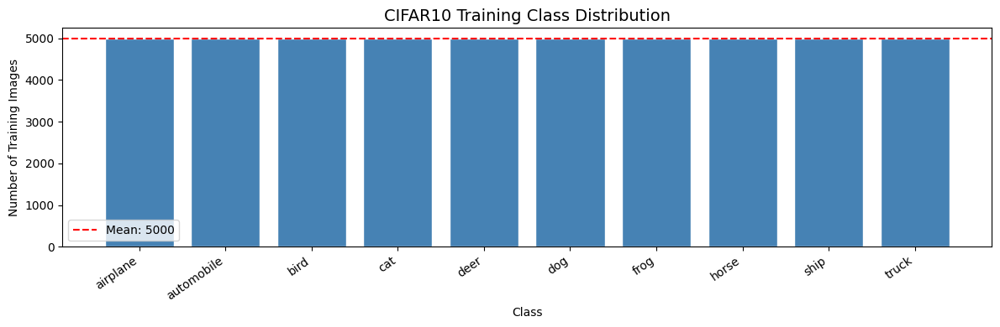

Min class count: 5000
Max class count: 5000
Mean class count: 5000.0


In [4]:
# Step 2.3: Check class distribution
class_counts = pd.DataFrame({
    "Class ID": range(NUM_CLASSES),
    "Class Name": CLASS_NAMES,
    "Train Count": np.bincount(y_train, minlength=NUM_CLASSES),
    "Test Count": np.bincount(y_test, minlength=NUM_CLASSES),
})

display(class_counts)

plt.figure(figsize=(12, 4))
plt.bar(class_counts["Class Name"], class_counts["Train Count"], color="steelblue", edgecolor="white")
plt.axhline(
    class_counts["Train Count"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {class_counts['Train Count'].mean():.0f}"
)
plt.title("CIFAR10 Training Class Distribution", fontsize=14)
plt.xlabel("Class")
plt.ylabel("Number of Training Images")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

print("Min class count:", class_counts["Train Count"].min())
print("Max class count:", class_counts["Train Count"].max())
print("Mean class count:", class_counts["Train Count"].mean())


### 2.2 Class Distribution Interpretation

The class distribution check matters because the final model should generate all 10 CIFAR10 classes, not only the easiest or most common class.

The output shows:

| Check | Result |
|-------|--------|
| minimum training class count | 5,000 |
| maximum training class count | 5,000 |
| mean training class count | 5,000.0 |
| test images per class | 1,000 |

This means the CIFAR10 training set is perfectly balanced, with **5,000 training images per class**. This is useful for a conditional final model because every class has the same amount of training evidence.

Decision: no class rebalancing is needed before training. The next step can focus on image preprocessing, baseline VAE/DCGAN comparison and later class-specific generation.

### 2.3 Pixel Range and Sample Image Visualisation

This visualisation checks real CIFAR10 images before modelling.

The generator will later be judged against these visual patterns. At 32x32 resolution, the images are small, so the expected output should contain rough object shapes, colour cues and backgrounds rather than high-detail photographs.

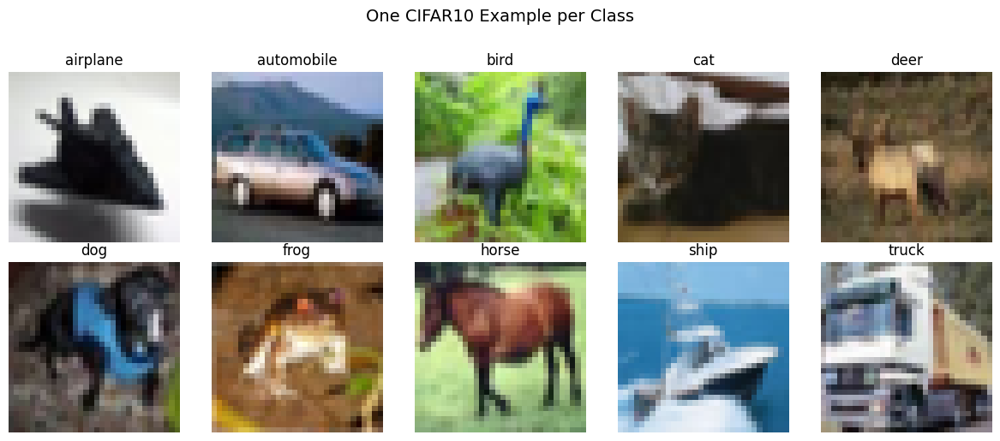

In [5]:
# Step 2.4: Visualise one image per class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for class_id, ax in enumerate(axes):
    first_index = np.where(y_train == class_id)[0][0]
    ax.imshow(X_train_raw[first_index])
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")

plt.suptitle("One CIFAR10 Example per Class", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### 2.3.1 Sample Image Interpretation

The sample grid shows one real CIFAR10 training image from each of the 10 classes.

This confirms that the final generator needs to create small **32x32 coloured images**, not high-resolution images. At this size, the object is often recognised through a mix of colour, rough shape and background pattern.

Some classes have clearer global cues. For example, ship and airplane images often include sky or water-like backgrounds, while automobile and truck images have stronger block-like shapes. Classes such as cat, dog, deer and bird are likely to be harder because they depend more on small organic details.

Decision: inspect more than one example per class before modelling, because one image is not enough to understand the variation inside each CIFAR10 class.

### 2.4 Class Variation Visualisation

This visualisation checks several examples from each CIFAR10 class.

This matters because the generator is not trying to copy one fixed image per class. It must learn a distribution of possible appearances, where the same class can appear with different backgrounds, poses, colours and object positions.

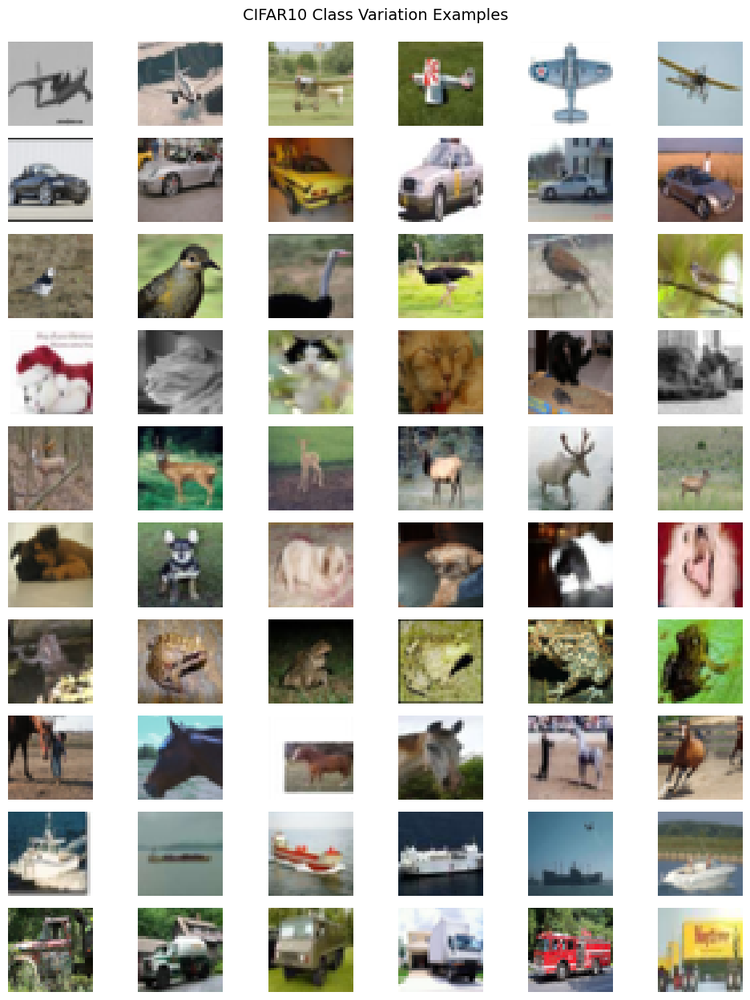

In [6]:
# Step 2.5: Visualise class variation
examples_per_class = 6
fig, axes = plt.subplots(NUM_CLASSES, examples_per_class, figsize=(examples_per_class * 1.7, NUM_CLASSES * 1.25))

for class_id, class_name in enumerate(CLASS_NAMES):
    class_indices = np.where(y_train == class_id)[0]
    chosen_indices = np.random.default_rng(SEED + class_id).choice(
        class_indices,
        size=examples_per_class,
        replace=False
    )

    for col, image_index in enumerate(chosen_indices):
        ax = axes[class_id, col]
        ax.imshow(X_train_raw[image_index])
        ax.axis("off")

        if col == 0:
            ax.set_ylabel(class_name, rotation=0, ha="right", va="center", labelpad=35)

plt.suptitle("CIFAR10 Class Variation Examples", fontsize=14, y=0.995)
plt.tight_layout()
plt.show()


### 2.4.1 Class Variation Interpretation

The class-variation grid shows that each CIFAR10 class has more than one visual pattern.

This is important for generation because the model should not memorise one example per class. It needs to learn a range of possible colours, shapes, backgrounds and object positions. For example, vehicles may appear from different angles, animals may have different poses, and backgrounds can change even within the same class.

The grid also gives my first expectation about class difficulty. Classes with stronger global shapes or background cues, such as automobile, ship and truck, may be easier to recognise. Airplane may sit in a more mixed position because sky/background cues can help, but the aircraft body is often small at 32x32 resolution. Classes such as cat, dog, deer and bird may be harder because their details are smaller and more organic.

However, this is still mainly visual judgement. Before moving on, I want to support the observation with simple engineered features from the real CIFAR10 images. This lets me check whether the classes that look harder also show weaker edge or texture signals numerically.

Decision: engineer a small set of real-image features before the data audit, then use them as early evidence when I later explain class-wise generation quality.


### 2.4.2 Real CIFAR10 Feature Engineering Check

This step turns the raw CIFAR10 pixels into simple numeric features.

The aim is not to feed these features into the VAE or GAN. These models learn image representations directly from pixels, so manually supplying edge strength or colour variation as model inputs is not necessary for this workflow. Instead, I use the engineered features as **EDA and diagnostic evidence**: they help me form a more defensible expectation about which CIFAR10 classes may be harder to generate.

| Engineered feature | Why it may matter for generation |
|--------------------|----------------------------------|
| edge strength | gives a rough signal of how strong the image boundaries and texture changes are |
| contrast | checks whether the image has enough light-dark separation |
| colour variation | checks how much RGB variation exists inside the image |
| brightness penalty | identifies images that are very dark or very bright compared with a mid-range image |

I sample **500 images per class** because it gives a balanced compromise between reliability and speed. A very small sample such as 100 images may be too affected by unusual examples, while using all 5000 images per class would slow down an EDA check that is only meant to guide the hypothesis. Since CIFAR10 has **5000 training images per class**, 500 images is also a clear **10% class-balanced sample**.

Expected output: one row per CIFAR10 class. I sort the table by average edge strength because edge strength is the closest simple proxy for boundary/detail information. This does not prove the final class difficulty, but it gives a more evidence-based starting point than relying only on the visual grid.


In [7]:
# Step 2.4.2: Engineer simple image-quality features from real CIFAR10 images
REAL_FEATURE_IMAGES_PER_CLASS = 500


def image_quality_features_from_array(image):
    image = np.asarray(image).astype("float32")
    gray = image.mean(axis=2)

    contrast = gray.std()
    colour_variation = image.std(axis=(0, 1)).mean()

    grad_x = np.abs(np.diff(gray, axis=1)).mean()
    grad_y = np.abs(np.diff(gray, axis=0)).mean()
    edge_strength = grad_x + grad_y

    brightness = gray.mean()
    brightness_penalty = abs(brightness - 127.5) / 127.5

    return {
        "contrast": contrast,
        "colour_variation": colour_variation,
        "edge_strength": edge_strength,
        "brightness_penalty": brightness_penalty,
    }


real_feature_records = []
feature_rng = np.random.default_rng(SEED + 240)

for class_id, class_name in enumerate(CLASS_NAMES):
    class_indices = np.where(y_train == class_id)[0]
    selected_indices = feature_rng.choice(
        class_indices,
        size=REAL_FEATURE_IMAGES_PER_CLASS,
        replace=False
    )

    for image_index in selected_indices:
        features = image_quality_features_from_array(X_train_raw[image_index])
        real_feature_records.append({
            "class_id": class_id,
            "class_name": class_name,
            **features,
        })

real_cifar10_features = pd.DataFrame(real_feature_records)

real_cifar10_feature_summary = (
    real_cifar10_features
    .groupby(["class_id", "class_name"])
    .agg(
        sampled_images=("class_name", "count"),
        avg_edge_strength=("edge_strength", "mean"),
        avg_contrast=("contrast", "mean"),
        avg_colour_variation=("colour_variation", "mean"),
        avg_brightness_penalty=("brightness_penalty", "mean"),
    )
    .reset_index()
    .sort_values("avg_edge_strength", ascending=True)
    .reset_index(drop=True)
)

real_cifar10_feature_summary["edge_strength_rank_low_to_high"] = (
    np.arange(1, len(real_cifar10_feature_summary) + 1)
)

real_cifar10_feature_summary_path = TABLE_DIR / "real_cifar10_engineered_features_by_class.csv"
real_cifar10_feature_summary.to_csv(real_cifar10_feature_summary_path, index=False)

display(real_cifar10_feature_summary)

print("Real CIFAR10 images sampled per class:", REAL_FEATURE_IMAGES_PER_CLASS)
print("Engineered feature summary saved as:", real_cifar10_feature_summary_path)


,class_id,class_name,sampled_images,avg_edge_strength,avg_contrast,avg_colour_variation,avg_brightness_penalty,edge_strength_rank_low_to_high
0,0,airplane,500,23.657764,47.374470,49.029808,0.240209,1
1,2,bird,500,24.031132,40.780399,42.507481,0.212859,2
2,8,ship,500,24.938089,51.344795,52.926834,0.189715,3
3,4,deer,500,25.960154,40.155907,41.399120,0.199107,4
4,3,cat,500,28.093462,50.989460,52.343678,0.212046,5
5,5,dog,500,28.698753,51.437569,52.694588,0.181964,6
6,6,frog,500,31.113859,42.225296,43.527428,0.249626,7
7,7,horse,500,31.754429,53.465809,54.802338,0.170909,8
8,9,truck,500,34.037033,60.329254,62.406891,0.161285,9
9,1,automobile,500,34.763508,57.770466,59.700504,0.211193,10


Real CIFAR10 images sampled per class: 500
Engineered feature summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\real_cifar10_engineered_features_by_class.csv


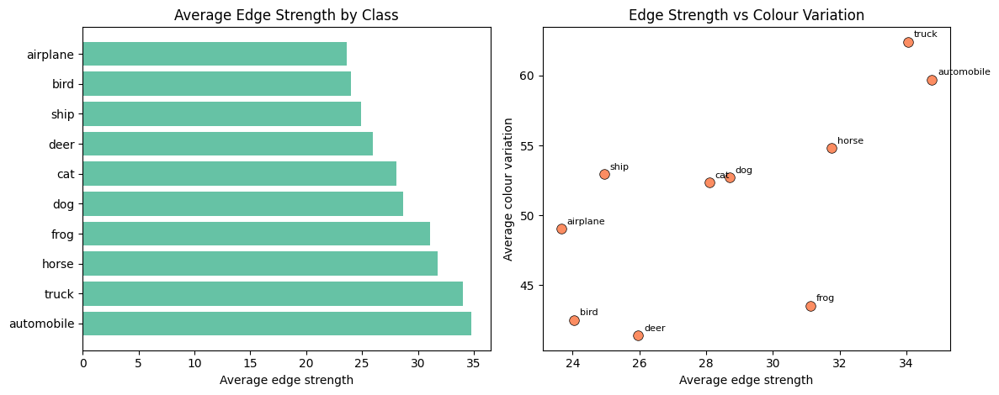

Engineered feature plot saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\real_cifar10_engineered_feature_summary.png


In [8]:
# Step 2.4.3: Visualise engineered feature ranking
feature_plot_df = real_cifar10_feature_summary.sort_values(
    "avg_edge_strength",
    ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].barh(
    feature_plot_df["class_name"],
    feature_plot_df["avg_edge_strength"],
    color="#66c2a5"
)
axes[0].set_title("Average Edge Strength by Class")
axes[0].set_xlabel("Average edge strength")
axes[0].invert_yaxis()

axes[1].scatter(
    feature_plot_df["avg_edge_strength"],
    feature_plot_df["avg_colour_variation"],
    s=70,
    color="#fc8d62",
    edgecolor="black",
    linewidth=0.5
)

for _, row in feature_plot_df.iterrows():
    axes[1].annotate(
        row["class_name"],
        (row["avg_edge_strength"], row["avg_colour_variation"]),
        textcoords="offset points",
        xytext=(5, 4),
        fontsize=8
    )

axes[1].set_title("Edge Strength vs Colour Variation")
axes[1].set_xlabel("Average edge strength")
axes[1].set_ylabel("Average colour variation")

plt.tight_layout()

real_feature_plot_path = GRID_DIR / "real_cifar10_engineered_feature_summary.png"
fig.savefig(real_feature_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Engineered feature plot saved as:", real_feature_plot_path)


### 2.4.4 Feature Engineering Checkpoint

The engineered-feature table gives a more evidence-based view of the real CIFAR10 classes before any model is trained.

I sampled **500 real training images per class** and calculated edge strength, contrast, colour variation and brightness penalty. I chose 500 because it is large enough to smooth out one-off image variation, but still small enough to keep the notebook responsive. Since these values are derived from raw pixels, this is a feature-engineering step for EDA rather than another visual inspection.

| Feature evidence | What I learned |
|------------------|----------------|
| lowest average edge strength | airplane (23.66), bird (24.03), ship (24.94), deer (25.96) |
| highest average edge strength | horse (31.75), truck (34.04), automobile (34.76) |
| bird edge strength | 24.03, supporting the concern that bird may be visually softer and harder to generate clearly |
| automobile and truck edge strength | 34.76 and 34.04, supporting the idea that these classes have stronger visual boundaries |
| deer edge and colour variation | edge 25.96, colour variation 41.40, suggesting deer may be smoother and less visually noisy than I first assumed |

The table improves my earlier interpretation, but it also makes it more careful. Low edge strength does not automatically mean a class will be hard. For example, airplane and ship have low edge strength because many real images include smooth sky or water backgrounds, but those backgrounds can still be useful class cues. This shows why the feature table should support the visual grid, not replace it.

The scatter plot also shows that vehicle-like classes such as automobile and truck sit toward the stronger edge/colour side, while bird sits near the softer edge side. This gives a reasonable early explanation for why the generator may later produce clearer vehicles than small organic classes.

Decision: keep the engineered features as an early class-difficulty signal, then compare them against the manual quality scores after the final cDCGAN output is generated.


### 2.5 Data Audit Card

Before preprocessing, the dataset checks are summarised into one audit card.

This makes the modelling decisions explicit. The audit card connects what was observed in the dataset to the next step in the modelling pipeline.

In [9]:
# Step 2.6: Pixel and data audit card
audit_card = pd.DataFrame({
    "Check": [
        "Dataset source",
        "Training images",
        "Test images",
        "Image shape",
        "Channels",
        "Pixel range",
        "Number of classes",
        "Class balance",
        "Engineered image features",
        "Manual split needed now"
    ],
    "Finding": [
        "tf.keras.datasets.cifar10.load_data()",
        f"{X_train_raw.shape[0]:,}",
        f"{X_test_raw.shape[0]:,}",
        str(X_train_raw.shape[1:]),
        "RGB",
        f"{X_train_raw.min()} to {X_train_raw.max()}",
        NUM_CLASSES,
        "Balanced: 5,000 training images per class",
        "edge strength, contrast, colour variation, brightness penalty",
        "No"
    ],
    "Decision": [
        "Allowed dataset source",
        "Use for VAE/GAN training",
        "Keep as reference, not generator training",
        "Generate 32x32 images",
        "Generate coloured images",
        "Normalise before modelling",
        "Generate class-specific outputs",
        "No class rebalancing needed",
        "Use as early class-difficulty evidence",
        "Use official training data for model learning"
    ]
})

display(audit_card)


,Check,Finding,Decision
0,Dataset source,tf.keras.datasets.cifar10.load_data(),Allowed dataset source
1,Training images,"50,000",Use for VAE/GAN training
2,Test images,"10,000","Keep as reference, not generator training"
3,Image shape,"(32, 32, 3)",Generate 32x32 images
4,Channels,RGB,Generate coloured images
5,Pixel range,0 to 255,Normalise before modelling
6,Number of classes,10,Generate class-specific outputs
7,Class balance,"Balanced: 5,000 training images per class",No class rebalancing needed
8,Engineered image features,"edge strength, contrast, colour variation, bri...",Use as early class-difficulty evidence
9,Manual split needed now,No,Use official training data for model learning


### 2.5.1 Data Audit Decision

The audit card confirms that the dataset is ready for preprocessing.

The key findings are:

| Dataset check | Result | Modelling decision |
|---------------|--------|--------------------|
| dataset source | `tf.keras.datasets.cifar10.load_data()` | allowed source, no external data |
| training images | 50,000 | use for VAE/GAN training |
| test images | 10,000 | keep as reference only |
| image shape | `(32, 32, 3)` | generate 32x32 RGB images |
| pixel range | 0 to 255 | normalise before modelling |
| class balance | 5,000 training images per class | no class rebalancing needed |
| engineered image features | edge strength, contrast, colour variation and brightness penalty | use as early evidence for class difficulty |

The engineered features improve the EDA because they create new variables from the raw pixels instead of only displaying the original images. The result suggests that classes such as automobile and truck have stronger edge structure, while bird and deer are visually softer by the edge-strength measure.

This does not fully decide which classes will be easy or hard. Airplane and ship also have low edge strength, but their background cues may still make them recognisable. Therefore, my early hypothesis becomes more balanced: class difficulty depends on shape, texture, background cues and feature strength together.

Decision: continue to preprocessing. Two normalised image versions are needed because VAE and GAN use different output activations.


## 3. Preprocessing

The same CIFAR10 images are prepared in two different ways.

This is necessary because the VAE and GAN output layers use different ranges:

| Model | Output layer | Real image range needed |
|-------|--------------|-------------------------|
| VAE | `sigmoid` | 0 to 1 |
| GAN | `tanh` | -1 to 1 |

If the real images use the wrong range, the model learns against a target that does not match its output layer.

In [10]:
# Step 3.1: Normalise images for VAE and GAN
X_train_vae = X_train_raw.astype("float32") / 255.0
X_test_vae = X_test_raw.astype("float32") / 255.0

X_train_gan = (X_train_raw.astype("float32") - 127.5) / 127.5
X_test_gan = (X_test_raw.astype("float32") - 127.5) / 127.5

print("VAE train dtype:", X_train_vae.dtype)
print("VAE train range:", X_train_vae.min(), "to", X_train_vae.max())
print("GAN train dtype:", X_train_gan.dtype)
print("GAN train range:", X_train_gan.min(), "to", X_train_gan.max())


VAE train dtype: float32
VAE train range: 0.0 to 1.0
GAN train dtype: float32


GAN train range: -1.0 to 1.0


### 3.1 Normalisation Interpretation

The preprocessing output confirms that both model inputs are in the correct numeric format.

| Model input | Data type | Range after preprocessing | Why this range is used |
|-------------|-----------|---------------------------|------------------------|
| VAE images | `float32` | 0.0 to 1.0 | the VAE decoder uses `sigmoid` |
| GAN images | `float32` | -1.0 to 1.0 | the GAN generator uses `tanh` |

This matters because generated images and real training images must be compared in the same range during training. If the ranges do not match the output layers, the model may learn unstable or incorrect pixel values.

Decision: keep both preprocessed arrays. `X_train_vae` is used for VAE/CVAE training, while `X_train_gan` is used for DCGAN/cDCGAN training.

### 3.2 TensorFlow Dataset Pipelines

Next I convert the NumPy arrays into `tf.data.Dataset` pipelines.

This makes training cleaner and more efficient because TensorFlow can batch, shuffle and prefetch the data. I create separate datasets for the baseline models and the final conditional GAN workflow:

| Dataset | Used for |
|---------|----------|
| `vae_train_ds` | baseline VAE |
| `gan_train_ds` | baseline DCGAN |
| `cdcgan_train_ds` | final Conditional DCGAN |
| `cvae_train_ds` | labelled VAE-format reference pipeline, not the selected final model |

In [11]:
# Step 3.2: Build TensorFlow dataset pipelines
vae_train_ds = (
    tf.data.Dataset.from_tensor_slices(X_train_vae)
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

gan_train_ds = (
    tf.data.Dataset.from_tensor_slices(X_train_gan)
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

cvae_train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_vae, y_train.astype("int32")))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

cdcgan_train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_gan, y_train.astype("int32")))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

vae_batch = next(iter(vae_train_ds))
gan_batch = next(iter(gan_train_ds))
cvae_image_batch, cvae_label_batch = next(iter(cvae_train_ds))
cdcgan_image_batch, cdcgan_label_batch = next(iter(cdcgan_train_ds))

print("VAE batch shape:", vae_batch.shape)
print("GAN batch shape:", gan_batch.shape)
print("CVAE image batch shape:", cvae_image_batch.shape)
print("CVAE label batch shape:", cvae_label_batch.shape)
print("cDCGAN image batch shape:", cdcgan_image_batch.shape)
print("cDCGAN label batch shape:", cdcgan_label_batch.shape)


VAE batch shape: (128, 32, 32, 3)
GAN batch shape: (128, 32, 32, 3)
CVAE image batch shape: (128, 32, 32, 3)
CVAE label batch shape: (128,)
cDCGAN image batch shape: (128, 32, 32, 3)
cDCGAN label batch shape: (128,)


### 3.2.1 Dataset Pipeline Interpretation

The dataset pipeline output confirms that the TensorFlow batches are ready for training.

| Pipeline | Output shape | Meaning |
|----------|--------------|---------|
| `vae_train_ds` | `(128, 32, 32, 3)` | baseline VAE receives only images |
| `gan_train_ds` | `(128, 32, 32, 3)` | baseline DCGAN receives only images |
| `cdcgan_train_ds` images | `(128, 32, 32, 3)` | final Conditional DCGAN receives images |
| `cdcgan_train_ds` labels | `(128,)` | final Conditional DCGAN also receives class labels |
| `cvae_train_ds` images/labels | `(128, 32, 32, 3)` and `(128,)` | kept as a labelled reference pipeline, but not used as the final model |

This confirms the baseline and final conditional workflows are separated properly. The baseline models learn general CIFAR10-like image generation, while the final cDCGAN learns class-specific generation.

Decision: continue by creating helper functions for converting and saving generated images consistently.

### 3.3 Image Display and Saving Helpers

Before building the models, I define helper functions for generated images.

This avoids repeating image conversion code later. It also prevents an unfair comparison because VAE and GAN outputs use different numeric ranges before they are converted back into normal image pixels.

In [12]:
# Step 3.3: Image conversion and saving helpers
def gan_output_to_uint8(images):
    images = (images + 1.0) * 127.5
    return np.clip(images, 0, 255).astype("uint8")


def vae_output_to_uint8(images):
    images = images * 255.0
    return np.clip(images, 0, 255).astype("uint8")


def show_image_grid(images, title, class_labels=None, columns=10, figsize=(12, 12)):
    image_count = len(images)
    rows = math.ceil(image_count / columns)
    fig, axes = plt.subplots(rows, columns, figsize=figsize)
    axes = np.array(axes).reshape(rows, columns)

    for index, ax in enumerate(axes.flatten()):
        ax.axis("off")
        if index < image_count:
            ax.imshow(images[index])
            if class_labels is not None:
                ax.set_title(class_labels[index], fontsize=8)

    plt.suptitle(title, fontsize=14, y=0.995)
    plt.tight_layout()
    plt.show()


def save_image_grid(images, output_path, columns=10):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    pil_images = [Image.fromarray(img) for img in images]
    image_width, image_height = pil_images[0].size
    rows = math.ceil(len(pil_images) / columns)
    grid = Image.new("RGB", (columns * image_width, rows * image_height), color=(255, 255, 255))

    for index, image in enumerate(pil_images):
        row = index // columns
        col = index % columns
        grid.paste(image, (col * image_width, row * image_height))

    grid.save(output_path)
    return output_path


def save_individual_images(images, output_dir, prefix, class_name=None):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    saved_paths = []
    for index, image in enumerate(images, start=1):
        if class_name is None:
            filename = f"{prefix}_{index:04d}.png"
        else:
            filename = f"{prefix}_{class_name}_{index:04d}.png"

        path = output_dir / filename
        Image.fromarray(image).save(path)
        saved_paths.append(path)

    return saved_paths


print("Helper functions are ready.")


Helper functions are ready.


### 3.3.1 Helper Function Checkpoint

The helper function cell ran successfully, so the notebook can now display and save generated images consistently.

This matters because the VAE and GAN produce image values in different ranges before conversion:

| Model output | Helper used | Converted image format |
|--------------|-------------|------------------------|
| VAE / CVAE output in 0 to 1 | `vae_output_to_uint8()` | normal 0 to 255 image pixels |
| GAN / cDCGAN output in -1 to 1 | `gan_output_to_uint8()` | normal 0 to 255 image pixels |

Decision: use these helper functions for every generated sample grid and every saved submission image so the image quality comparison stays fair.

## 4. Baseline VAE Model

I first test a VAE because it is usually more stable to train than a GAN.

The VAE compresses an image into a latent distribution, samples a latent vector, and reconstructs the image through a decoder. My expectation is that the VAE may produce smoother but blurrier images because reconstruction loss encourages averaged-looking outputs.

This baseline gives me a stable reference before I compare against an adversarial DCGAN model.

In [13]:
# Step 4.1: Baseline VAE architecture
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def build_vae_encoder(latent_dim=LATENT_DIM):
    encoder_inputs = keras.Input(shape=IMG_SHAPE, name="encoder_image_input")

    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(encoder_inputs)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)

    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling(name="z")([z_mean, z_log_var])

    return keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="baseline_vae_encoder")


def build_vae_decoder(latent_dim=LATENT_DIM):
    latent_inputs = keras.Input(shape=(latent_dim,), name="decoder_latent_input")

    x = layers.Dense(4 * 4 * 128, activation="relu")(latent_inputs)
    x = layers.Reshape((4, 4, 128))(x)
    x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
    decoder_outputs = layers.Conv2D(IMG_CHANNELS, 3, padding="same", activation="sigmoid")(x)

    return keras.Model(latent_inputs, decoder_outputs, name="baseline_vae_decoder")


class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=0.0005, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        return self.decoder(z, training=training)

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(data - reconstruction), axis=(1, 2, 3))
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = reconstruction_loss + self.beta * kl_loss

        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }


vae_encoder = build_vae_encoder()
vae_decoder = build_vae_decoder()
baseline_vae = VAE(vae_encoder, vae_decoder, name="baseline_vae")
baseline_vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4))

print("Baseline VAE encoder:")
vae_encoder.summary()
print("\nBaseline VAE decoder:")
vae_decoder.summary()


Baseline VAE encoder:
Model: "baseline_vae_encoder"


__________________________________________________________________________________________________


 Layer (type)                   Output Shape         Param #     Connected to                     


 encoder_image_input (InputLaye  [(None, 32, 32, 3)]  0          []                               


 r)                                                                                               


 conv2d (Conv2D)                (None, 16, 16, 32)   896         ['encoder_image_input[0][0]']    


... (26 outputs left out)

Total params: 504,899


Trainable params: 504,899


Non-trainable params: 0


_________________________________________________________________


### 4.1 VAE Architecture Interpretation

The baseline VAE architecture has now been built successfully.

A normal autoencoder usually works like this:

> image -> encoder -> one compressed vector -> decoder -> reconstructed image

A VAE is different because it does not compress each image into only one fixed vector. Instead, it compresses the image into a small **latent distribution**. This is why the encoder outputs:

- `z_mean`: the centre point of the latent distribution;
- `z_log_var`: how much spread or variation is allowed around that point;
- `z`: the actual sampled latent vector used by the decoder.

This is useful for image generation. The VAE learns a smooth image-space where nearby latent vectors should produce related-looking images. Later, a new latent vector can be sampled and passed through the decoder to generate a new CIFAR10-like image.

The decoder then takes a **128-dimensional latent vector** and upsamples it back into a **32x32x3** image using transposed convolution layers.

The architecture summary shows:

| Component | Total parameters | Purpose |
|-----------|------------------|---------|
| baseline VAE encoder | 683,584 | compress image into a latent distribution |
| baseline VAE decoder | 504,899 | turn a latent vector back into an image |

The main VAE choices are:

| Choice | Reason |
|--------|--------|
| latent dimension = 128 | keeps the compressed space compact while still giving enough capacity for CIFAR10 colour and shape patterns |
| filter counts 32 -> 64 -> 128 | increases feature capacity as the spatial size becomes smaller, instead of using one flat filter size throughout |
| three convolution downsampling blocks | reduces 32x32 images step by step into a 4x4 feature representation |
| three transposed-convolution upsampling blocks | mirrors the encoder and rebuilds the image back to 32x32 |
| `z_mean` and `z_log_var` outputs | allow the VAE to sample from a distribution instead of memorising one fixed code |
| beta = 0.0005 | keeps the KL term present while preventing it from overpowering reconstruction on small CIFAR10 images |
| sigmoid decoder output | matches the VAE preprocessing range of 0 to 1 |
| 30 training epochs | gives the stable baseline enough time to learn reconstruction patterns before comparing against GAN outputs |

I chose these values as a moderate baseline rather than pushing the VAE very small or very large.

| Design choice | Why this was chosen over alternatives |
|---------------|---------------------------------------|
| 128 latent dimensions | smaller values such as 32 or 64 may compress CIFAR10 too aggressively, while much larger values would make the baseline heavier without guaranteeing clearer samples |
| 32, 64, 128 filters | fewer filters may underfit colour and texture patterns; much larger filters would make the VAE less useful as a simple baseline |
| three down/up-sampling stages | two stages may leave the latent representation too close to the image grid, while four stages would shrink 32x32 images too far and risk losing small object details |
| small beta value | a stronger KL penalty could make samples smoother or blurrier, so I keep it small for this first reconstruction-based baseline |

Decision: this is a suitable stable baseline before testing the sharper but less stable DCGAN direction.


### 4.2 Training the Baseline VAE

This step prepares the first VAE baseline and keeps both the model weights and the training history.

The purpose of this baseline is not to produce the final 1000 images yet. It gives a stable first generative model that can be compared against the DCGAN later.

The saved weights and training history were produced during the corrected clean retraining run. In this final notebook execution, the verified saved VAE weights are loaded to avoid unnecessary retraining while keeping the results linked to the corrected workflow.


Loading existing baseline VAE weights: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\models\baseline_vae.weights.h5


Baseline VAE encoder weights: loaded with Keras 3 HDF5 compatibility loader (6 weighted layers)
Baseline VAE decoder weights: loaded with Keras 3 HDF5 compatibility loader (5 weighted layers)
Baseline VAE weights loaded.


,epoch,kl_loss,loss,reconstruction_loss
25,26,627.870056,26.195190,25.881260
26,27,625.442749,25.865881,25.553167
27,28,624.384644,25.538296,25.226097
28,29,623.770386,25.251226,24.939356
29,30,621.530457,24.976887,24.666107


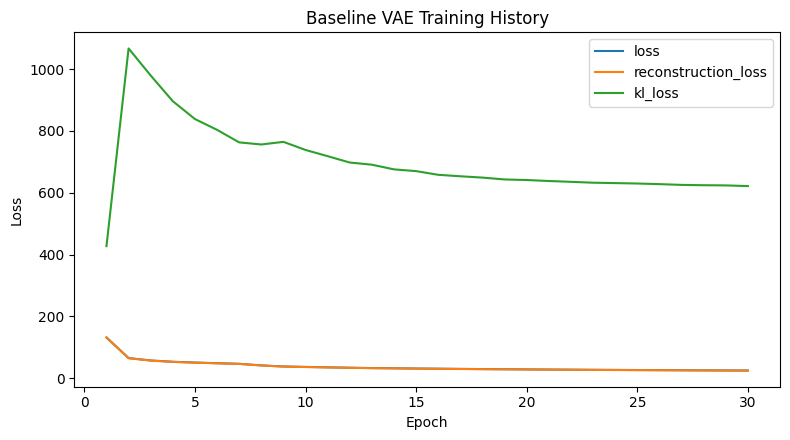

Baseline VAE training plot saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\baseline_vae_training_history.png


In [14]:
# Step 4.2: Train or load baseline VAE
vae_weights_path = MODEL_DIR / "baseline_vae.weights.h5"
vae_history_path = TABLE_DIR / "baseline_vae_training_history.csv"
vae_history_plot_path = GRID_DIR / "baseline_vae_training_history.png"

vae_history_df = load_training_history(vae_history_path)

if vae_weights_path.exists():
    print("Loading existing baseline VAE weights:", vae_weights_path)

    # Build the subclassed VAE model once before loading HDF5 weights.
    _ = baseline_vae(tf.zeros((1, *IMG_SHAPE)), training=False)

    encoder_load_status = load_weights_compat(vae_encoder, vae_weights_path, root_group="encoder")
    decoder_load_status = load_weights_compat(vae_decoder, vae_weights_path, root_group="decoder")
    vae_history = None
    print("Baseline VAE encoder weights:", encoder_load_status)
    print("Baseline VAE decoder weights:", decoder_load_status)
    print("Baseline VAE weights loaded.")

    if vae_history_df is None:
        print("No saved VAE training-history CSV was found for these existing weights.")
        print("If I retrain later, the notebook will save the history automatically.")
else:
    print("Training baseline VAE...")
    vae_history = baseline_vae.fit(
        vae_train_ds,
        epochs=VAE_EPOCHS,
        verbose=0
    )
    # Build the subclassed wrapper before saving HDF5 weights in newer Keras versions.
    _ = baseline_vae(tf.zeros((1, *IMG_SHAPE)), training=False)
    baseline_vae.save_weights(vae_weights_path)
    vae_history_df = history_to_dataframe(vae_history)
    vae_history_df.to_csv(vae_history_path, index=False)
    print("Saved baseline VAE weights:", vae_weights_path)
    print("Saved baseline VAE training history:", vae_history_path)

if vae_history_df is not None:
    display(vae_history_df.tail(5))
    saved_plot = save_training_history_plot(
        vae_history_df,
        ["loss", "reconstruction_loss", "kl_loss"],
        vae_history_plot_path,
        "Baseline VAE Training History"
    )
    if saved_plot is not None:
        print("Baseline VAE training plot saved as:", saved_plot)
else:
    display(pd.DataFrame([{
        "model": "baseline VAE",
        "weights_file_found": vae_weights_path.exists(),
        "history_csv_found": False,
        "note": "loss history is not hard-coded; retraining will create the CSV and plot",
    }]))


### 4.2.1 Baseline VAE Training Outcome

The baseline VAE weights and history are now treated as verified saved evidence from the corrected training run. In the current notebook execution, the saved `baseline_vae.weights.h5` file is loaded instead of training the model again.

The saved history CSV gives the training evidence directly. At epoch **30**, the final logged loss was **24.9769**, with reconstruction loss **24.6661** and KL loss **621.5305**. I do not use this loss by itself to decide whether the generated images are good, because the VAE objective mainly measures reconstruction and latent-space regularisation. However, it is useful evidence that the planned baseline training completed properly.

Decision: keep the VAE as the stable reconstruction-based baseline, then compare it against the adversarial DCGAN and cDCGAN using generated samples, manual scoring and FID.


### 4.3 Baseline VAE Generated Samples

This step generates **100 new images** from the baseline VAE decoder.

These images are generated from random latent vectors, not copied directly from the training set. This gives an early visual check of whether the VAE has learned CIFAR10-like colour and structure.

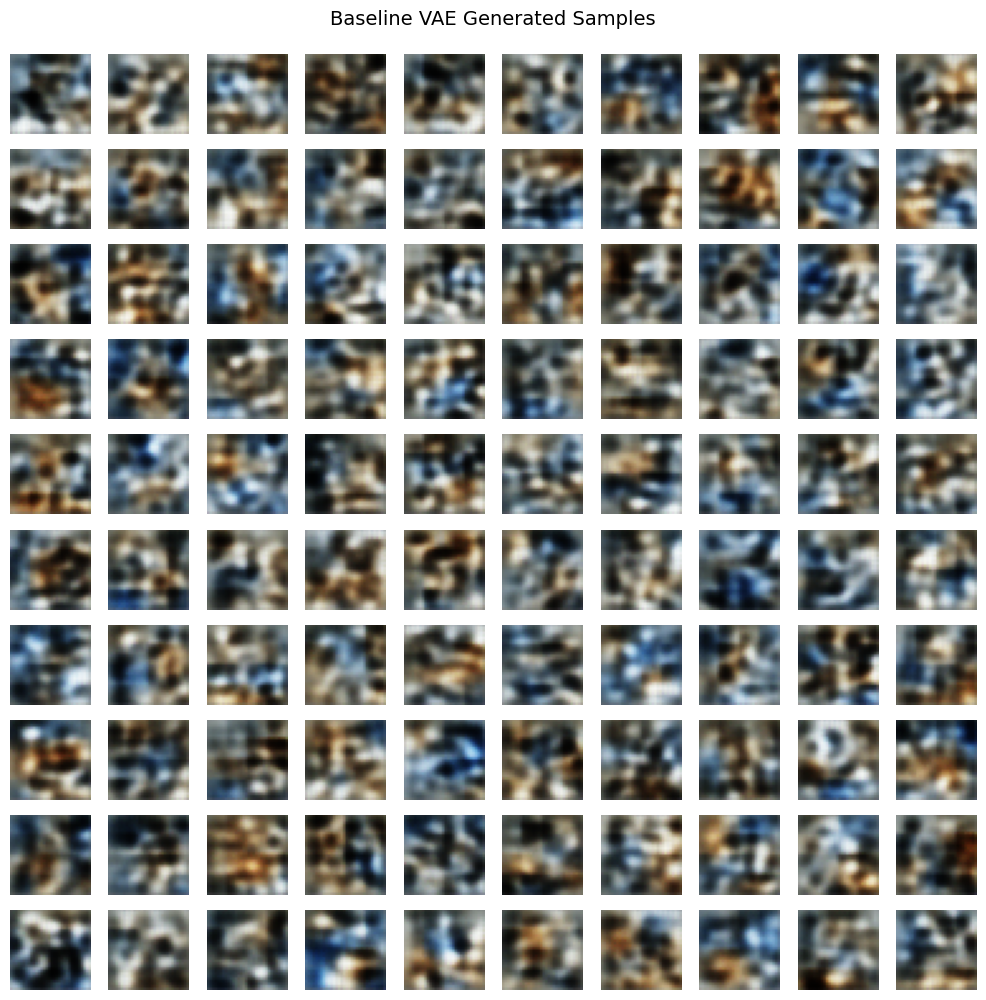

Baseline VAE grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\baseline_vae_100_samples.png
Baseline VAE individual samples saved: 100
Manual evaluation folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\manual_evaluation_images\baseline_vae_100


In [15]:
# Step 4.3: Generate 100 baseline VAE samples
vae_noise = tf.random.normal(shape=(100, LATENT_DIM), seed=SEED)
vae_generated = baseline_vae.decoder.predict(vae_noise, verbose=0)
vae_generated_uint8 = vae_output_to_uint8(vae_generated)

show_image_grid(
    vae_generated_uint8,
    title="Baseline VAE Generated Samples",
    columns=10,
    figsize=(10, 10)
)

vae_grid_path = save_image_grid(
    vae_generated_uint8,
    GRID_DIR / "baseline_vae_100_samples.png",
    columns=10
)

saved_vae_sample_paths = save_individual_images(
    vae_generated_uint8,
    MANUAL_EVAL_DIR / "baseline_vae_100",
    prefix="vae"
)

print("Baseline VAE grid saved as:", vae_grid_path)
print("Baseline VAE individual samples saved:", len(saved_vae_sample_paths))
print("Manual evaluation folder:", MANUAL_EVAL_DIR / "baseline_vae_100")


### 4.3.1 Baseline VAE Sample Interpretation

The baseline VAE generated and saved **100 sample images**, so the full VAE baseline workflow is working.

When I inspect the generated grid, the images show some CIFAR10-like colour behaviour. There are blue, brown, grey and dark patches that look closer to natural image textures than pure random noise. However, the samples do not yet show clear object shapes such as a car body, animal outline, ship, or airplane.

This result is useful because it shows both the strength and weakness of the VAE baseline:

| Observation | What it means |
|-------------|---------------|
| colours and textures are not completely random | the VAE has learned part of the CIFAR10 image distribution |
| object shapes are still unclear | reconstruction-based VAE training has not produced recognisable class structure yet |
| images look noisy or blurry | this is a common weakness of simple VAEs on natural images |

The VAE is still a valid baseline because it gives useful evidence, not because it is already suitable for the final 1000 images. It needs to be compared against the DCGAN before choosing the final direction.

Decision: keep the VAE as the stable first baseline, then test a baseline DCGAN to check whether adversarial training gives sharper or more recognisable CIFAR10-like samples.

## 5. Baseline DCGAN Model

After the VAE baseline, I test a DCGAN because GANs are designed to generate sharper images through adversarial training.

The generator tries to create fake CIFAR10-like images. The discriminator tries to tell real images from fake images. Through this competition, the generator may learn sharper colour and texture than the VAE, but training can also be less stable.

In [16]:
# Step 5.1: Baseline DCGAN architecture
def build_dcgan_generator(latent_dim=LATENT_DIM):
    generator_inputs = keras.Input(shape=(latent_dim,), name="dcgan_noise_input")

    x = layers.Dense(4 * 4 * 256, use_bias=False)(generator_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Reshape((4, 4, 256))(x)

    x = layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2DTranspose(32, 4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    generator_outputs = layers.Conv2D(IMG_CHANNELS, 3, padding="same", activation="tanh")(x)
    return keras.Model(generator_inputs, generator_outputs, name="baseline_dcgan_generator")


def build_dcgan_discriminator():
    discriminator_inputs = keras.Input(shape=IMG_SHAPE, name="dcgan_image_input")

    x = layers.Conv2D(64, 4, strides=2, padding="same")(discriminator_inputs)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(256, 4, strides=2, padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    discriminator_outputs = layers.Dense(1)(x)

    return keras.Model(discriminator_inputs, discriminator_outputs, name="baseline_dcgan_discriminator")


class DCGAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim=LATENT_DIM, **kwargs):
        super().__init__(**kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = latent_dim
        self.d_loss_tracker = keras.metrics.Mean(name="d_loss")
        self.g_loss_tracker = keras.metrics.Mean(name="g_loss")

    @property
    def metrics(self):
        return [self.d_loss_tracker, self.g_loss_tracker]

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer
        self.loss_fn = loss_fn

    def train_step(self, real_images):
        batch_size = tf.shape(real_images)[0]

        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        generated_images = self.generator(random_latent_vectors, training=True)
        combined_images = tf.concat([generated_images, real_images], axis=0)

        fake_targets = tf.random.uniform(
            shape=(batch_size, 1),
            minval=0.0,
            maxval=0.05
        )
        real_targets = tf.random.uniform(
            shape=(batch_size, 1),
            minval=0.95,
            maxval=1.0
        )
        labels = tf.concat([fake_targets, real_targets], axis=0)

        with tf.GradientTape() as tape:
            predictions = self.discriminator(combined_images, training=True)
            d_loss = self.loss_fn(labels, predictions)

        gradients = tape.gradient(d_loss, self.discriminator.trainable_weights)
        self.d_optimizer.apply_gradients(zip(gradients, self.discriminator.trainable_weights))

        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        misleading_labels = tf.random.uniform(
            shape=(batch_size, 1),
            minval=0.95,
            maxval=1.0
        )

        with tf.GradientTape() as tape:
            fake_predictions = self.discriminator(
                self.generator(random_latent_vectors, training=True),
                training=True
            )
            g_loss = self.loss_fn(misleading_labels, fake_predictions)

        gradients = tape.gradient(g_loss, self.generator.trainable_weights)
        self.g_optimizer.apply_gradients(zip(gradients, self.generator.trainable_weights))

        self.d_loss_tracker.update_state(d_loss)
        self.g_loss_tracker.update_state(g_loss)

        return {
            "d_loss": self.d_loss_tracker.result(),
            "g_loss": self.g_loss_tracker.result(),
        }


dcgan_generator = build_dcgan_generator()
dcgan_discriminator = build_dcgan_discriminator()
baseline_dcgan = DCGAN(dcgan_generator, dcgan_discriminator, name="baseline_dcgan")

baseline_dcgan.compile(
    d_optimizer=keras.optimizers.Adam(learning_rate=GAN_LEARNING_RATE, beta_1=0.5),
    g_optimizer=keras.optimizers.Adam(learning_rate=GAN_LEARNING_RATE, beta_1=0.5),
    loss_fn=keras.losses.BinaryCrossentropy(from_logits=True)
)

print("Baseline DCGAN generator:")
dcgan_generator.summary()
print("\nBaseline DCGAN discriminator:")
dcgan_discriminator.summary()


Baseline DCGAN generator:
Model: "baseline_dcgan_generator"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dcgan_noise_input (InputLay  [(None, 128)]            0         


 er)                                                             


 dense_2 (Dense)             (None, 4096)              524288    


... (40 outputs left out)

Total params: 662,977


Trainable params: 662,977


Non-trainable params: 0


_________________________________________________________________


### 5.1 DCGAN Architecture Interpretation

The baseline DCGAN architecture was built successfully.

This is used as the second baseline because it gives a different comparison point from the VAE. The generator creates **32x32x3 CIFAR10-like images** from a **128-dimensional noise vector**, while the discriminator checks whether images look real or generated.

The architecture summary is:

| Component | Total parameters |
|-----------|------------------|
| baseline DCGAN generator | 1,230,563 |
| baseline DCGAN discriminator | 662,977 |

The main DCGAN choices are:

| Choice | Reason |
|--------|--------|
| latent dimension = 128 | matches the VAE latent size so the baselines use the same compact starting dimension |
| 4x4x256 starting feature map | gives the generator a small spatial base that can be upsampled cleanly to 32x32 |
| generator filters 256 -> 128 -> 64 -> 32 | starts with many abstract features, then reduces channels as spatial resolution increases |
| discriminator filters 64 -> 128 -> 256 | starts with local image patterns, then increases capacity as the image is compressed |
| transposed convolution upsampling | progressively increases resolution from 4x4 to 8x8, 16x16 and 32x32 |
| BatchNorm in the generator | stabilises feature scaling during upsampling |
| LeakyReLU in generator and discriminator | avoids inactive ReLU behaviour during adversarial training |
| Dropout in the discriminator | reduces discriminator overconfidence, which can destabilise GAN training |
| tanh generator output | matches the GAN preprocessing range of -1 to 1 |
| 50 training epochs | gives adversarial training more time than the VAE because generator/discriminator losses are less direct and can fluctuate |

I chose this as a medium-sized CIFAR10 DCGAN rather than a very shallow or very deep model.

| Design choice | Why this was chosen over alternatives |
|---------------|---------------------------------------|
| 128 noise dimensions | keeps the comparison aligned with the VAE latent size; a much smaller vector may limit image variety, while a much larger vector increases training cost |
| 4x4 starting map | fits the 32x32 target neatly through three 2x upsampling steps; starting at 2x2 may lose spatial structure, while 8x8 would reduce the amount of learned upsampling |
| 256/128/64/32 generator filters | gives high capacity at the small spatial stage where global structure is formed, then reduces channels as the image becomes larger |
| 64/128/256 discriminator filters | gives the discriminator more capacity after it has compressed the image, where it can judge higher-level real/fake patterns |
| three up/downsampling stages | directly matches the 4x4 -> 8x8 -> 16x16 -> 32x32 path; adding more depth would increase instability for a baseline GAN |

Decision: train this DCGAN baseline and compare its generated samples against the VAE using the same visual evaluation method.


### 5.2 DCGAN Training Sample Monitor

Before training, I prepare a monitor that saves generated image grids at selected epochs.

This helps me judge the DCGAN visually, since GAN losses alone do not always show whether the generated images are improving.


In [17]:
# Step 5.2: Sample monitor for GAN training
class GANMonitor(Callback):
    def __init__(self, generator, latent_dim, output_dir, prefix, num_images=25, save_every=10):
        super().__init__()
        self.generator = generator
        self.latent_dim = latent_dim
        self.output_dir = Path(output_dir)
        self.prefix = prefix
        self.num_images = num_images
        self.save_every = save_every
        self.fixed_noise = tf.random.normal(shape=(num_images, latent_dim), seed=SEED)

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = epoch + 1
        if epoch_number == 1 or epoch_number % self.save_every == 0:
            generated = self.generator.predict(self.fixed_noise, verbose=0)
            generated_uint8 = gan_output_to_uint8(generated)
            output_path = self.output_dir / f"{self.prefix}_epoch_{epoch_number:03d}.png"
            save_image_grid(generated_uint8, output_path, columns=5)
            print("Saved sample grid:", output_path)


print("GAN sample monitor is ready.")


GAN sample monitor is ready.


### 5.2.1 DCGAN Monitor Checkpoint

The sample monitor is ready and will save DCGAN image grids during training.

Decision: use this monitor while training so the final judgement is based on both loss behaviour and image quality.


### 5.3 Training the Baseline DCGAN

This step prepares the baseline DCGAN and keeps both the generator/discriminator weights and the training history.

The saved weights and training history were produced from the corrected bounded label-smoothing code during the clean retraining run. In this final notebook execution, the verified saved DCGAN weights are loaded to avoid unnecessary retraining while keeping the outputs reproducible.


Loading existing baseline DCGAN weights.
Baseline DCGAN generator weights: loaded with Keras 3 HDF5 compatibility loader (9 weighted layers)
Baseline DCGAN discriminator weights: loaded with Keras 3 HDF5 compatibility loader (4 weighted layers)
Baseline DCGAN weights loaded.


,epoch,d_loss,g_loss
45,46,0.632919,0.892322
46,47,0.630639,0.897087
47,48,0.641745,0.899131
48,49,0.631078,0.888493
49,50,0.630029,0.898511


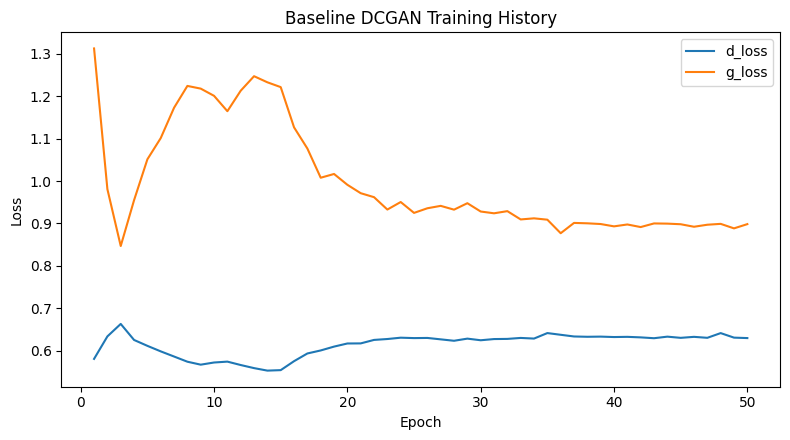

Baseline DCGAN training plot saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\baseline_dcgan_training_history.png


In [18]:
# Step 5.3: Train or load baseline DCGAN
dcgan_generator_weights_path = MODEL_DIR / "baseline_dcgan_generator.weights.h5"
dcgan_discriminator_weights_path = MODEL_DIR / "baseline_dcgan_discriminator.weights.h5"
dcgan_history_path = TABLE_DIR / "baseline_dcgan_training_history.csv"
dcgan_history_plot_path = GRID_DIR / "baseline_dcgan_training_history.png"

dcgan_history_df = load_training_history(dcgan_history_path)

if dcgan_generator_weights_path.exists() and dcgan_discriminator_weights_path.exists():
    print("Loading existing baseline DCGAN weights.")
    generator_load_status = load_weights_compat(dcgan_generator, dcgan_generator_weights_path)
    discriminator_load_status = load_weights_compat(dcgan_discriminator, dcgan_discriminator_weights_path)
    print("Baseline DCGAN generator weights:", generator_load_status)
    print("Baseline DCGAN discriminator weights:", discriminator_load_status)
    dcgan_history = None
    print("Baseline DCGAN weights loaded.")

    if dcgan_history_df is None:
        print("No saved baseline DCGAN training-history CSV was found for these existing weights.")
        print("If I retrain later, the notebook will save the history automatically.")
else:
    print("Training baseline DCGAN...")
    dcgan_history = baseline_dcgan.fit(
        gan_train_ds,
        epochs=DCGAN_EPOCHS,
        callbacks=[
            GANMonitor(
                generator=dcgan_generator,
                latent_dim=LATENT_DIM,
                output_dir=SAMPLE_DIR,
                prefix="baseline_dcgan",
                num_images=25,
                save_every=10,
            )
        ],
        verbose=0,
    )

    dcgan_generator.save_weights(dcgan_generator_weights_path)
    dcgan_discriminator.save_weights(dcgan_discriminator_weights_path)
    dcgan_history_df = history_to_dataframe(dcgan_history)
    dcgan_history_df.to_csv(dcgan_history_path, index=False)
    print("Saved baseline DCGAN generator weights:", dcgan_generator_weights_path)
    print("Saved baseline DCGAN discriminator weights:", dcgan_discriminator_weights_path)
    print("Saved baseline DCGAN training history:", dcgan_history_path)

if dcgan_history_df is not None:
    display(dcgan_history_df.tail(5))
    saved_plot = save_training_history_plot(
        dcgan_history_df,
        ["d_loss", "g_loss"],
        dcgan_history_plot_path,
        "Baseline DCGAN Training History"
    )
    if saved_plot is not None:
        print("Baseline DCGAN training plot saved as:", saved_plot)
else:
    display(pd.DataFrame([{
        "model": "baseline DCGAN",
        "generator_weights_found": dcgan_generator_weights_path.exists(),
        "discriminator_weights_found": dcgan_discriminator_weights_path.exists(),
        "history_csv_found": False,
        "note": "loss history is not hard-coded; retraining will create the CSV and plot",
    }]))


### 5.3.1 Baseline DCGAN Training Outcome

The baseline DCGAN weights and history come from the corrected bounded label-smoothing implementation. Fake labels were kept between **0.00 and 0.05**, while real labels were kept between **0.95 and 1.00**. This fixes the earlier issue where adding only positive noise could push real labels above 1.

In the current notebook execution, the verified saved generator and discriminator weights are loaded instead of retraining from zero.

The saved history CSV records the final baseline DCGAN values at epoch **50**: discriminator loss **0.6300** and generator loss **0.8985**. I treat these losses as training evidence rather than final image-quality proof, because GAN losses can move unevenly when the generator and discriminator improve against each other.

Decision: keep the verified DCGAN as the sharper adversarial baseline, then use visual samples, manual scoring and FID to decide whether it is stronger than the VAE.


### 5.4 Baseline DCGAN Generated Samples

This step generates **100 images** from the trained baseline DCGAN.

These samples are saved in the same format as the VAE samples, so both baseline models can be compared fairly during manual visual evaluation.

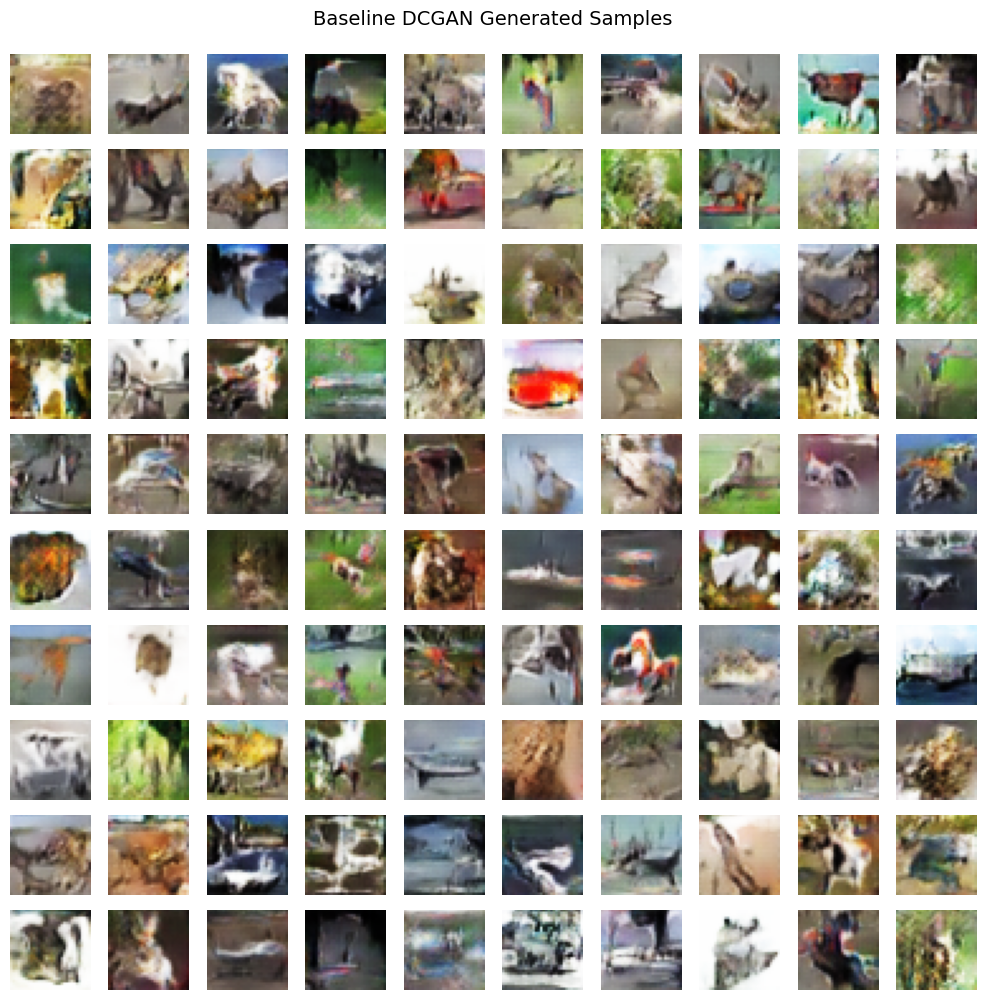

Baseline DCGAN grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\baseline_dcgan_100_samples.png
Baseline DCGAN individual samples saved: 100
Manual evaluation folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\manual_evaluation_images\baseline_dcgan_100


In [19]:
# Step 5.4: Generate 100 baseline DCGAN samples
dcgan_noise = tf.random.normal(shape=(100, LATENT_DIM), seed=SEED)
dcgan_generated = dcgan_generator.predict(dcgan_noise, verbose=0)
dcgan_generated_uint8 = gan_output_to_uint8(dcgan_generated)

show_image_grid(
    dcgan_generated_uint8,
    title="Baseline DCGAN Generated Samples",
    columns=10,
    figsize=(10, 10)
)

dcgan_grid_path = save_image_grid(
    dcgan_generated_uint8,
    GRID_DIR / "baseline_dcgan_100_samples.png",
    columns=10
)

saved_dcgan_sample_paths = save_individual_images(
    dcgan_generated_uint8,
    MANUAL_EVAL_DIR / "baseline_dcgan_100",
    prefix="dcgan"
)

print("Baseline DCGAN grid saved as:", dcgan_grid_path)
print("Baseline DCGAN individual samples saved:", len(saved_dcgan_sample_paths))
print("Manual evaluation folder:", MANUAL_EVAL_DIR / "baseline_dcgan_100")


### 5.4.1 Baseline DCGAN Sample Interpretation

The baseline DCGAN generated and saved **100 sample images**, so the full DCGAN baseline workflow is working.

The generated samples look more image-like than the VAE output. The grid shows stronger colour regions, sharper texture patches and some object-like shapes. However, many samples are still distorted, and the class identity is not always clear.

The DCGAN result can be summarised as:

| Observation | What it means |
|-------------|---------------|
| sharper colour and texture regions | the DCGAN has learned stronger visual patterns than the VAE baseline |
| some object-like shapes are visible | adversarial training is helping the samples look more natural |
| many images are still unclear | the baseline DCGAN is not yet reliable enough to accept without comparison |

Decision: keep the DCGAN as the stronger baseline candidate, then compare it directly against the VAE before deciding the next model direction.


## 6. Baseline Model Comparison

The VAE and DCGAN baselines have both generated **100 images**.

Next, I compare their saved image grids side by side so the model choice is based on the same sample count and the same visual evaluation style.


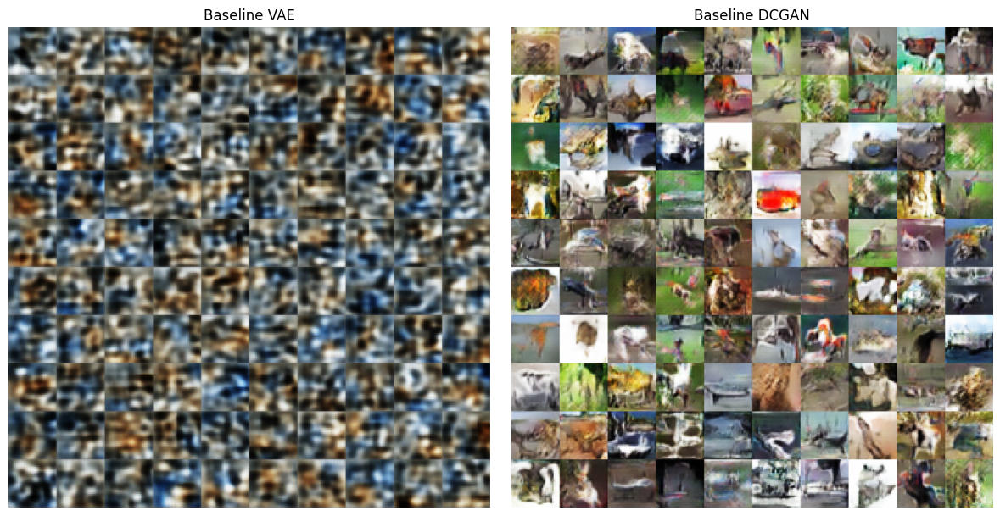

Baseline comparison grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\baseline_vae_vs_dcgan_comparison.png


In [20]:
# Step 6.1: Compare baseline VAE and DCGAN sample grids
vae_grid_image = plt.imread(GRID_DIR / "baseline_vae_100_samples.png")
dcgan_grid_image = plt.imread(GRID_DIR / "baseline_dcgan_100_samples.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(vae_grid_image)
axes[0].set_title("Baseline VAE")
axes[0].axis("off")

axes[1].imshow(dcgan_grid_image)
axes[1].set_title("Baseline DCGAN")
axes[1].axis("off")

plt.tight_layout()

baseline_comparison_path = GRID_DIR / "baseline_vae_vs_dcgan_comparison.png"
fig.savefig(baseline_comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("Baseline comparison grid saved as:", baseline_comparison_path)


### 6.1.1 Manual Score Table for Baseline Models

As stated in the evaluation plan at the start of the notebook, I use the same **Clear / Marginal / Nonsense** scoring method to compare the generated images.

| Category | What it means in this notebook |
|----------|--------------------------------|
| Clear | recognisable CIFAR10-like object or strong class feature |
| Marginal | useful colour, texture or rough shape, but class identity is uncertain |
| Nonsense | mostly distorted or noisy output with no meaningful object structure |

For the early VAE-vs-DCGAN baseline, the score table is used only to choose the modelling direction. It is aggregate evidence from the 100-sample baseline comparison, not the final proof for the submitted generator. The later cDCGAN sections contain the stronger audit trail because they evaluate the actual final 1000-image workflow with both aggregate scoring and filename-level review samples.

This keeps the baseline decision honest: the VAE and DCGAN are compared using the same categories, but I do not pretend the early baseline table has the same traceability as the final cDCGAN audit.


In [21]:
# Step 6.1.1: Save baseline manual score comparison
baseline_manual_scores = pd.DataFrame([
    {
        "model": "Baseline VAE",
        "images_checked": 100,
        "clear": 0,
        "marginal": 28,
        "nonsense": 72,
        "decision": "stable but blurry/noisy",
    },
    {
        "model": "Baseline DCGAN",
        "images_checked": 100,
        "clear": 20,
        "marginal": 48,
        "nonsense": 32,
        "decision": "sharper, chosen for cDCGAN",
    },
])

baseline_manual_scores["usable"] = (
    baseline_manual_scores["clear"] + baseline_manual_scores["marginal"]
)
baseline_manual_scores["usable_rate"] = (
    baseline_manual_scores["usable"] / baseline_manual_scores["images_checked"]
)

baseline_manual_score_path = TABLE_DIR / "baseline_manual_score_comparison.csv"
baseline_manual_scores.to_csv(baseline_manual_score_path, index=False)

display(baseline_manual_scores)

print("Baseline manual score comparison saved as:", baseline_manual_score_path)


,model,images_checked,clear,marginal,nonsense,decision,usable,usable_rate
0,Baseline VAE,100,0,28,72,stable but blurry/noisy,28,0.28
1,Baseline DCGAN,100,20,48,32,"sharper, chosen for cDCGAN",68,0.68


Baseline manual score comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\baseline_manual_score_comparison.csv


### 6.1.2 Baseline Manual Score Interpretation

The baseline manual score comparison supports the model direction decision.

| Model | Main result | Decision |
|-------|-------------|----------|
| Baseline VAE | almost no clear object structure | keep only as a stable baseline |
| Baseline DCGAN | sharper and more CIFAR10-like than the VAE | use as the direction to improve |

This comparison uses the same scoring method for both baseline model types, so the DCGAN direction is based on evidence instead of only visual preference.

Decision: choose the GAN direction, because it gives the stronger baseline for class-specific image generation.

### 6.1.3 Baseline Comparison Interpretation

The side-by-side comparison shows that the DCGAN is the stronger baseline for this project.

| Comparison point | Baseline VAE | Baseline DCGAN |
|------------------|--------------|----------------|
| visual sharpness | mostly blurry | sharper texture patches |
| object structure | unclear | more object-like shapes |
| sample variety | similar smooth patterns | wider colour and shape variation |
| main weakness | too blurry for final output | distorted and not class-controlled |

The VAE is useful as a stable baseline, but its output mainly captures average colour and texture patterns. For this assignment, the final output must look like CIFAR10 images, so recognisable visual structure matters more than stability alone.

The DCGAN is more applicable because its adversarial training encourages generated images to look closer to real images. In the comparison grid, the DCGAN produces stronger colour regions, sharper textures and more object-like shapes than the VAE.

| Reason | Why DCGAN is more suitable |
|--------|----------------------------|
| final task is image generation | DCGAN samples look closer to CIFAR10-like images |
| visual quality is important | DCGAN produces sharper textures than the VAE |
| class-specific output is required later | DCGAN can be extended into a Conditional DCGAN |

Decision: select the GAN direction for the final model, but still treat the image quality limitations as part of the final evaluation.


### 6.1.4 DCGAN Limitations and Improvement Focus

The baseline DCGAN is better than the VAE, but it still has several visible weaknesses.

| Issue seen in generated images | Why it matters | Improvement or follow-up |
|--------------------------------|----------------|--------------------------|
| no class control | cannot guarantee 100 images per class | use Conditional DCGAN |
| distorted object shapes | some samples are not clearly recognisable | evaluate class quality manually |
| texture stronger than structure | model may learn colour patches more than object form | compare final samples by class |
| class ambiguity | some images may look between multiple CIFAR10 classes | use class labels during generation |

The improvement is chosen because the DCGAN gives the better visual starting point, while conditioning fixes the most important assignment issue: generating a selected CIFAR10 class.

Decision: use **Conditional DCGAN** as the main improvement, then evaluate the remaining image-quality problems after generating the final images.

## 7. Improvement 1: Final Conditional DCGAN Model

The first improvement is changing the selected baseline DCGAN into a **Conditional DCGAN**.

This is the actual model improvement. The baseline DCGAN gave the stronger visual starting point, but it still generated mixed CIFAR10-like images without class control. By adding labels, the final model can generate images for a selected class.

| Question | Explanation |
|----------|-------------|
| What problem did I see? | the baseline DCGAN could not control which CIFAR10 class was generated |
| Why did this happen? | the generator only received random noise, so it had no class information |
| How did I plan to fix it? | add class labels to both the generator and discriminator |
| What did I do? | built and trained a Conditional DCGAN |
| How will I check it? | generate 100 images per class and review class-wise outputs |

Section 8 will evaluate whether this improvement worked and what limitations still remain.


### 7.1 Conditional DCGAN Architecture

This step builds the Conditional DCGAN architecture.

The generator receives both random noise and a class label. The discriminator also receives the image and its class label, so it learns whether an image looks realistic for that specific class.

In [22]:
# Step 7.1: Conditional DCGAN architecture
FINAL_MODEL_TYPE = "cdcgan"


def build_cdcgan_generator(latent_dim=LATENT_DIM, num_classes=NUM_CLASSES):
    noise_inputs = keras.Input(shape=(latent_dim,), name="cdcgan_noise_input")
    label_inputs = keras.Input(shape=(), dtype="int32", name="cdcgan_label_input")

    label_embedding = layers.Embedding(num_classes, latent_dim)(label_inputs)
    x = layers.Concatenate(name="noise_label_concat")([noise_inputs, label_embedding])

    x = layers.Dense(4 * 4 * 256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Reshape((4, 4, 256))(x)

    x = layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2DTranspose(32, 4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    generator_outputs = layers.Conv2D(IMG_CHANNELS, 3, padding="same", activation="tanh")(x)

    return keras.Model(
        [noise_inputs, label_inputs],
        generator_outputs,
        name="final_cdcgan_generator"
    )


def build_cdcgan_discriminator(num_classes=NUM_CLASSES):
    image_inputs = keras.Input(shape=IMG_SHAPE, name="cdcgan_image_input")
    label_inputs = keras.Input(shape=(), dtype="int32", name="cdcgan_label_input")

    label_embedding = layers.Embedding(num_classes, IMG_HEIGHT * IMG_WIDTH)(label_inputs)
    label_map = layers.Reshape((IMG_HEIGHT, IMG_WIDTH, 1))(label_embedding)
    x = layers.Concatenate(axis=-1, name="image_label_concat")([image_inputs, label_map])

    x = layers.Conv2D(64, 4, strides=2, padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(256, 4, strides=2, padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    discriminator_outputs = layers.Dense(1)(x)

    return keras.Model(
        [image_inputs, label_inputs],
        discriminator_outputs,
        name="final_cdcgan_discriminator"
    )


class ConditionalDCGAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim=LATENT_DIM, num_classes=NUM_CLASSES, **kwargs):
        super().__init__(**kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.d_loss_tracker = keras.metrics.Mean(name="d_loss")
        self.g_loss_tracker = keras.metrics.Mean(name="g_loss")

    @property
    def metrics(self):
        return [self.d_loss_tracker, self.g_loss_tracker]

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer
        self.loss_fn = loss_fn

    def train_step(self, data):
        real_images, real_labels = data
        real_labels = tf.cast(tf.reshape(real_labels, (-1,)), tf.int32)
        batch_size = tf.shape(real_images)[0]

        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        fake_labels = tf.random.uniform(
            shape=(batch_size,),
            minval=0,
            maxval=self.num_classes,
            dtype=tf.int32
        )
        generated_images = self.generator([random_latent_vectors, fake_labels], training=True)

        combined_images = tf.concat([generated_images, real_images], axis=0)
        combined_labels = tf.concat([fake_labels, real_labels], axis=0)
        fake_targets = tf.random.uniform(
            shape=(batch_size, 1),
            minval=0.0,
            maxval=0.05
        )
        real_targets = tf.random.uniform(
            shape=(batch_size, 1),
            minval=0.95,
            maxval=1.0
        )
        real_fake_targets = tf.concat([fake_targets, real_targets], axis=0)

        with tf.GradientTape() as tape:
            predictions = self.discriminator([combined_images, combined_labels], training=True)
            d_loss = self.loss_fn(real_fake_targets, predictions)

        gradients = tape.gradient(d_loss, self.discriminator.trainable_weights)
        self.d_optimizer.apply_gradients(zip(gradients, self.discriminator.trainable_weights))

        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        sampled_labels = tf.random.uniform(
            shape=(batch_size,),
            minval=0,
            maxval=self.num_classes,
            dtype=tf.int32
        )
        misleading_targets = tf.random.uniform(
            shape=(batch_size, 1),
            minval=0.95,
            maxval=1.0
        )

        with tf.GradientTape() as tape:
            fake_predictions = self.discriminator(
                [self.generator([random_latent_vectors, sampled_labels], training=True), sampled_labels],
                training=True
            )
            g_loss = self.loss_fn(misleading_targets, fake_predictions)

        gradients = tape.gradient(g_loss, self.generator.trainable_weights)
        self.g_optimizer.apply_gradients(zip(gradients, self.generator.trainable_weights))

        self.d_loss_tracker.update_state(d_loss)
        self.g_loss_tracker.update_state(g_loss)

        return {
            "d_loss": self.d_loss_tracker.result(),
            "g_loss": self.g_loss_tracker.result(),
        }


final_cdcgan_generator = build_cdcgan_generator()
final_cdcgan_discriminator = build_cdcgan_discriminator()
final_cdcgan = ConditionalDCGAN(
    final_cdcgan_generator,
    final_cdcgan_discriminator,
    name="final_cdcgan"
)

final_cdcgan.compile(
    d_optimizer=keras.optimizers.Adam(learning_rate=GAN_LEARNING_RATE, beta_1=0.5),
    g_optimizer=keras.optimizers.Adam(learning_rate=GAN_LEARNING_RATE, beta_1=0.5),
    loss_fn=keras.losses.BinaryCrossentropy(from_logits=True)
)

print("Selected final model type:", FINAL_MODEL_TYPE)
print("Conditional DCGAN generator:")
final_cdcgan_generator.summary()
print("\nConditional DCGAN discriminator:")
final_cdcgan_discriminator.summary()


Selected final model type: cdcgan
Conditional DCGAN generator:
Model: "final_cdcgan_generator"


__________________________________________________________________________________________________


 Layer (type)                   Output Shape         Param #     Connected to                     


 cdcgan_label_input (InputLayer  [(None,)]           0           []                               


 )                                                                                                


 cdcgan_noise_input (InputLayer  [(None, 128)]       0           []                               


... (51 outputs left out)

Total params: 674,241


Trainable params: 674,241


Non-trainable params: 0


__________________________________________________________________________________________________


### 7.1.1 Conditional DCGAN Architecture Interpretation

The Conditional DCGAN architecture was built successfully.

The architecture summary is:

| Component | Total parameters | Input used |
|-----------|------------------|------------|
| final cDCGAN generator | 1,756,131 | noise vector + class label |
| final cDCGAN discriminator | 674,241 | image + class label |

The main architecture choices are:

| Choice | Reason |
|--------|--------|
| latent dimension = 128 | gives the generator enough compact noise information while keeping training cost manageable |
| 32x32x3 output | matches the CIFAR10 RGB image size, so the generated images do not need a separate resizing target |
| generator filters 256 -> 128 -> 64 -> 32 | keeps the same tested DCGAN upsampling structure while adding class conditioning |
| three up/downsampling stages | keeps the 4x4 -> 8x8 -> 16x16 -> 32x32 image path, so the final improvement changes class control without also changing depth |
| discriminator filters 64 -> 128 -> 256 | keeps enough capacity to judge real/fake images after the class label is added |
| BatchNorm in the generator | helps stabilise feature scaling while the generator upsamples from 4x4 to 32x32 |
| LeakyReLU in the discriminator | reduces the risk of inactive ReLU units during adversarial training |
| class label embedding | gives both networks class information in a learnable form instead of treating labels as plain numbers |
| cDCGAN final model | supports class-specific generation, which the baseline VAE and normal DCGAN cannot directly control |

The cDCGAN keeps the successful parts of the baseline DCGAN instead of changing everything at once. I did not increase the depth or filter counts for the final model because the main problem identified was **class control**, not simply lack of capacity. A much larger model may produce better images with more training time, but it would also make it harder to tell whether the improvement came from conditioning or from extra model size.

| Design choice | Why this was chosen over alternatives |
|---------------|---------------------------------------|
| reuse the three-stage DCGAN depth | isolates the effect of adding labels instead of mixing the improvement with a shallower or deeper architecture |
| reuse the 128-dimensional noise vector | keeps the final model comparable to the earlier VAE and DCGAN baselines |
| add embeddings instead of one-hot concatenation only | lets the model learn a compact class representation before combining it with noise or image features |
| keep parameter count moderate | avoids turning the final improvement into a much larger model that would need a separate capacity comparison |

This improves the baseline DCGAN because the model is no longer generating random CIFAR10-like images only. The class label guides the generator toward a selected category, while the discriminator checks whether the image looks realistic for that same category.

Decision: train this Conditional DCGAN using the labelled CIFAR10 training pipeline.


### 7.2 Conditional DCGAN Training Sample Monitor

Before training, I create a class-aware monitor for the Conditional DCGAN.

The monitor saves generated images for all 10 CIFAR10 classes at selected epochs. This helps me check whether the model is learning class-specific differences, not just general CIFAR10 texture.


In [23]:
# Step 7.2: Class-aware sample monitor for Conditional DCGAN training
class ConditionalGANMonitor(Callback):
    def __init__(
        self,
        generator,
        latent_dim,
        class_names,
        output_dir,
        prefix,
        examples_per_class=5,
        save_every=10,
    ):
        super().__init__()
        self.generator = generator
        self.latent_dim = latent_dim
        self.class_names = class_names
        self.output_dir = Path(output_dir)
        self.prefix = prefix
        self.examples_per_class = examples_per_class
        self.save_every = save_every

        fixed_labels = np.repeat(np.arange(len(class_names)), examples_per_class).astype("int32")
        self.fixed_labels = tf.constant(fixed_labels, dtype=tf.int32)
        self.fixed_noise = tf.random.normal(shape=(len(fixed_labels), latent_dim), seed=SEED)

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = epoch + 1
        if epoch_number == 1 or epoch_number % self.save_every == 0:
            generated = self.generator.predict(
                [self.fixed_noise, self.fixed_labels],
                verbose=0
            )
            generated_uint8 = gan_output_to_uint8(generated)
            output_path = self.output_dir / f"{self.prefix}_epoch_{epoch_number:03d}.png"
            save_image_grid(generated_uint8, output_path, columns=self.examples_per_class)
            print("Saved class sample grid:", output_path)


print("Conditional GAN sample monitor is ready.")
print("Each saved row represents one CIFAR10 class in this order:")
print(CLASS_NAMES)


Conditional GAN sample monitor is ready.
Each saved row represents one CIFAR10 class in this order:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### 7.2.1 Conditional DCGAN Monitor Checkpoint

The class-aware monitor is ready.

It will save one row per CIFAR10 class during training, using this order: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck.

Decision: use this monitor during final cDCGAN training to check whether the model learns class-specific image differences.


### 7.3 Training the Final Conditional DCGAN

This step prepares the final Conditional DCGAN and keeps both the generator/discriminator weights and the training history.

This model uses the labelled CIFAR10 pipeline because both the image and class label are needed during training. The saved weights and training history were produced from the corrected cDCGAN training code during the clean retraining run. In this final notebook execution, the verified saved cDCGAN weights are loaded to avoid unnecessary retraining while keeping the generated 1000 images and evaluation outputs linked to the corrected workflow.


Loading existing final Conditional DCGAN weights.


Final cDCGAN generator weights: loaded with Keras 3 HDF5 compatibility loader (10 weighted layers)
Final cDCGAN discriminator weights: loaded with Keras 3 HDF5 compatibility loader (5 weighted layers)
Final Conditional DCGAN weights loaded.


,epoch,d_loss,g_loss
75,76,0.607006,0.988213
76,77,0.605820,0.986685
77,78,0.610385,0.980662
78,79,0.604694,0.999888
79,80,0.605933,0.991896


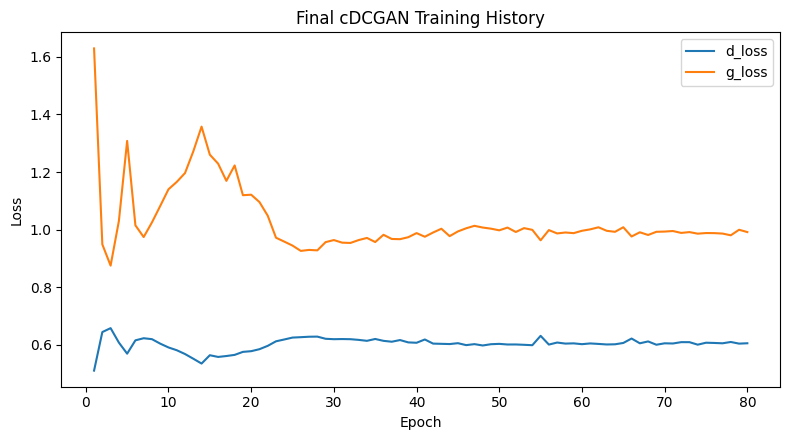

Final cDCGAN training plot saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\final_cdcgan_training_history.png


In [24]:
# Step 7.3: Train or load final Conditional DCGAN
final_cdcgan_generator_weights_path = MODEL_DIR / "final_cdcgan_generator.weights.h5"
final_cdcgan_discriminator_weights_path = MODEL_DIR / "final_cdcgan_discriminator.weights.h5"
final_cdcgan_history_path = TABLE_DIR / "final_cdcgan_training_history.csv"
final_cdcgan_history_plot_path = GRID_DIR / "final_cdcgan_training_history.png"

final_cdcgan_history_df = load_training_history(final_cdcgan_history_path)

if final_cdcgan_generator_weights_path.exists() and final_cdcgan_discriminator_weights_path.exists():
    print("Loading existing final Conditional DCGAN weights.")
    generator_load_status = load_weights_compat(final_cdcgan_generator, final_cdcgan_generator_weights_path)
    discriminator_load_status = load_weights_compat(final_cdcgan_discriminator, final_cdcgan_discriminator_weights_path)
    print("Final cDCGAN generator weights:", generator_load_status)
    print("Final cDCGAN discriminator weights:", discriminator_load_status)
    final_cdcgan_history = None
    print("Final Conditional DCGAN weights loaded.")

    if final_cdcgan_history_df is None:
        print("No saved final cDCGAN training-history CSV was found for these existing weights.")
        print("If I retrain later, the notebook will save the history automatically.")
else:
    print("Training final Conditional DCGAN...")
    final_cdcgan_history = final_cdcgan.fit(
        cdcgan_train_ds,
        epochs=FINAL_CDCGAN_EPOCHS,
        callbacks=[
            ConditionalGANMonitor(
                generator=final_cdcgan_generator,
                latent_dim=LATENT_DIM,
                class_names=CLASS_NAMES,
                output_dir=SAMPLE_DIR,
                prefix="final_cdcgan",
                examples_per_class=5,
                save_every=10,
            )
        ],
        verbose=0,
    )

    final_cdcgan_generator.save_weights(final_cdcgan_generator_weights_path)
    final_cdcgan_discriminator.save_weights(final_cdcgan_discriminator_weights_path)
    final_cdcgan_history_df = history_to_dataframe(final_cdcgan_history)
    final_cdcgan_history_df.to_csv(final_cdcgan_history_path, index=False)
    print("Saved final cDCGAN generator weights:", final_cdcgan_generator_weights_path)
    print("Saved final cDCGAN discriminator weights:", final_cdcgan_discriminator_weights_path)
    print("Saved final cDCGAN training history:", final_cdcgan_history_path)

if final_cdcgan_history_df is not None:
    display(final_cdcgan_history_df.tail(5))
    saved_plot = save_training_history_plot(
        final_cdcgan_history_df,
        ["d_loss", "g_loss"],
        final_cdcgan_history_plot_path,
        "Final cDCGAN Training History"
    )
    if saved_plot is not None:
        print("Final cDCGAN training plot saved as:", saved_plot)
else:
    display(pd.DataFrame([{
        "model": "final cDCGAN",
        "generator_weights_found": final_cdcgan_generator_weights_path.exists(),
        "discriminator_weights_found": final_cdcgan_discriminator_weights_path.exists(),
        "history_csv_found": False,
        "note": "loss history is not hard-coded; retraining will create the CSV and plot",
    }]))


### 7.3.1 Final Conditional DCGAN Training Outcome

The final Conditional DCGAN weights and history come from the corrected bounded label-smoothing implementation. The verified generator and discriminator weights are saved as `final_cdcgan_generator.weights.h5` and `final_cdcgan_discriminator.weights.h5`.

In the current notebook execution, those saved weights are loaded instead of retraining from scratch. This matches the visible code output and keeps the notebook reproducible without wasting training time.

The saved history CSV records the final cDCGAN values at epoch **80**: discriminator loss **0.6059** and generator loss **0.9919**. These values show that the corrected training process completed, but I still rely on generated-image evidence for the main judgement because GAN losses do not always correspond neatly to image realism.

Decision: use this verified cDCGAN as the valid final model. The regenerated 1000 images, candidate selection, manual scoring and FID come from weights produced by the corrected training code, so the workflow is consistent from training to evaluation.


### 7.4 Generating the Final 1000 Images

This step generates the final submission image set.

The model generates **100 images for each CIFAR10 class**, then saves them into class-specific folders. This directly answers the assignment requirement of producing **1000 generated images** across all 10 classes.

,class_id,class_name,images_saved,folder
0,0,airplane,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,1,automobile,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,2,bird,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,3,cat,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
4,4,deer,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
5,5,dog,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
6,6,frog,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
7,7,horse,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
8,8,ship,100,C:\Users\USER\OneDrive - Singapore Polytechnic...
9,9,truck,100,C:\Users\USER\OneDrive - Singapore Polytechnic...


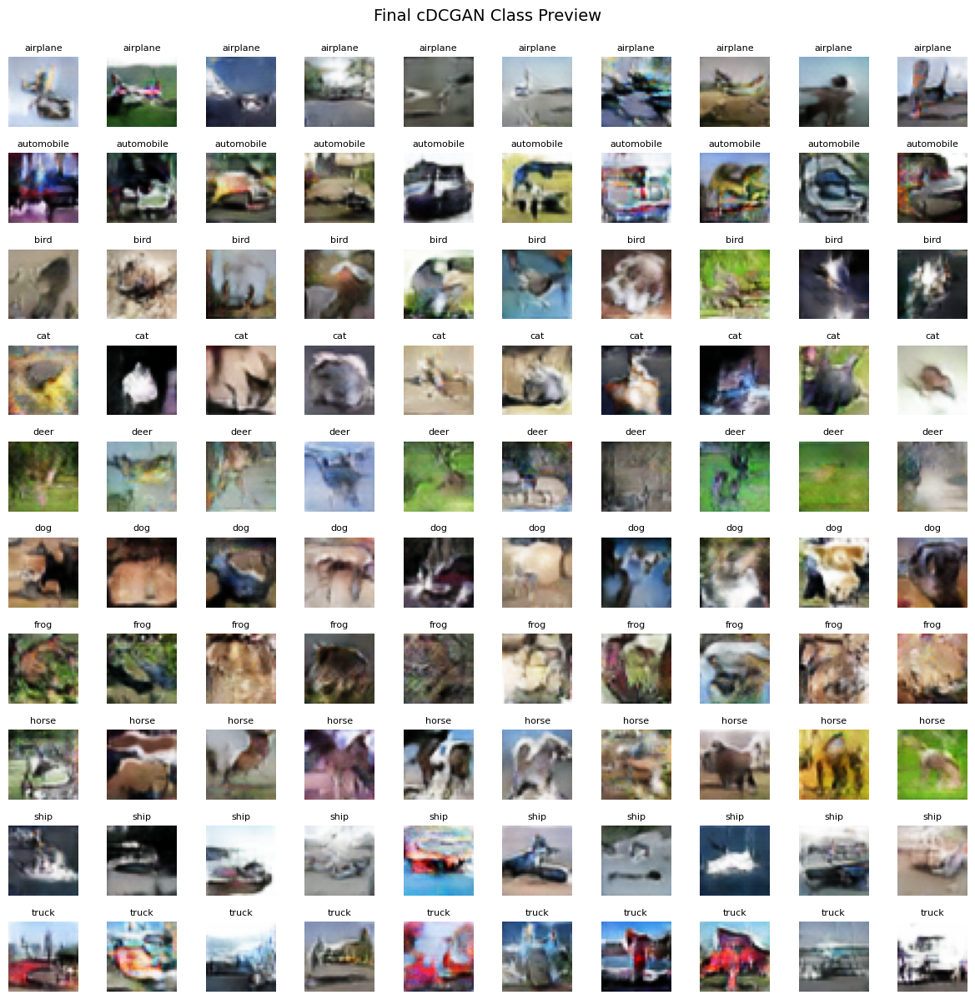

Final generated images saved: 1000
Final image folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\generated_1000_images
Final preview grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\final_cdcgan_class_preview_100.png
Final generation summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\final_1000_generation_summary.csv


In [25]:
# Step 7.4: Generate 1000 class-specific final images
saved_final_image_paths = []
final_generation_records = []
final_preview_images = []
final_preview_labels = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_output_dir = FINAL_IMAGE_DIR / f"{class_id:02d}_{class_name}"

    class_noise = tf.random.normal(
        shape=(FINAL_IMAGES_PER_CLASS, LATENT_DIM),
        seed=SEED + class_id
    )
    class_labels = tf.fill([FINAL_IMAGES_PER_CLASS], class_id)

    generated_images = final_cdcgan_generator.predict(
        [class_noise, class_labels],
        verbose=0
    )
    generated_uint8 = gan_output_to_uint8(generated_images)

    saved_paths = save_individual_images(
        generated_uint8,
        class_output_dir,
        prefix="final_cdcgan",
        class_name=class_name
    )

    saved_final_image_paths.extend(saved_paths)
    final_preview_images.extend(generated_uint8[:10])
    final_preview_labels.extend([class_name] * 10)

    final_generation_records.append({
        "class_id": class_id,
        "class_name": class_name,
        "images_saved": len(saved_paths),
        "folder": str(class_output_dir),
    })

final_generation_summary = pd.DataFrame(final_generation_records)
display(final_generation_summary)

final_preview_images = np.array(final_preview_images)
show_image_grid(
    final_preview_images,
    title="Final cDCGAN Class Preview",
    class_labels=final_preview_labels,
    columns=10,
    figsize=(12, 12)
)

final_preview_grid_path = save_image_grid(
    final_preview_images,
    GRID_DIR / "final_cdcgan_class_preview_100.png",
    columns=10
)

final_generation_summary_path = TABLE_DIR / "final_1000_generation_summary.csv"
final_generation_summary.to_csv(final_generation_summary_path, index=False)

print("Final generated images saved:", len(saved_final_image_paths))
print("Final image folder:", FINAL_IMAGE_DIR)
print("Final preview grid saved as:", final_preview_grid_path)
print("Final generation summary saved as:", final_generation_summary_path)


### 7.4.1 Final 1000 Image Generation Outcome

The final cDCGAN generated and saved the required **1000 images** successfully.

The output is organised as:

| Requirement | Result |
|-------------|--------|
| CIFAR10 classes | 10 classes |
| images per class | 100 images |
| total generated images | 1000 images |
| saved format | class-specific folders |
| preview grid | `final_cdcgan_class_preview_100.png` |

This confirms that the class-count problem has been fixed. The notebook can now generate a controlled number of images for each CIFAR10 class instead of producing one mixed set of random images.

However, this does not mean every image is visually perfect. The preview grid still shows some distorted shapes and unclear class identity, especially for classes with more organic shapes.

Decision: continue with improvement-by-improvement evaluation instead of claiming the final model is fully solved.


### 7.5 Generate a Requested CIFAR10 Class

The final model should not only generate a balanced 1000-image folder. It should also be able to generate a class requested by the user.

To make this requirement explicit, I test the trained cDCGAN with one requested class: **ship**. This is a small demonstration cell, separate from the final 1000-image submission folder, so the marker can clearly see how class-specific generation is performed.


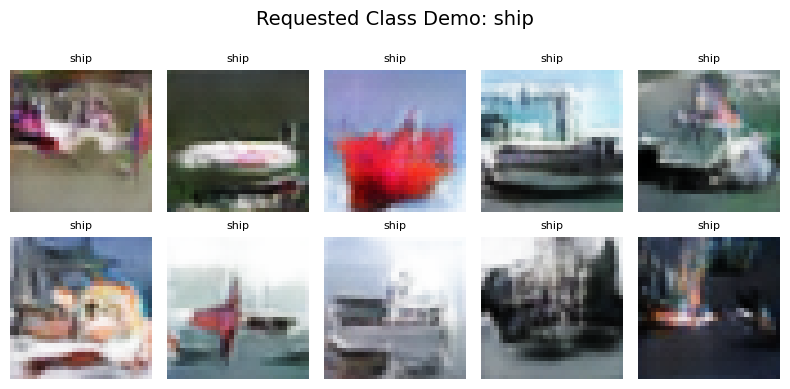

,requested_class,class_id,image_number,image_file,image_path
0,ship,8,1,requested_ship_0001.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,ship,8,2,requested_ship_0002.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,ship,8,3,requested_ship_0003.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,ship,8,4,requested_ship_0004.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
4,ship,8,5,requested_ship_0005.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
5,ship,8,6,requested_ship_0006.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
6,ship,8,7,requested_ship_0007.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
7,ship,8,8,requested_ship_0008.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
8,ship,8,9,requested_ship_0009.png,C:\Users\USER\OneDrive - Singapore Polytechnic...
9,ship,8,10,requested_ship_0010.png,C:\Users\USER\OneDrive - Singapore Polytechnic...


Requested class: ship
Requested-class grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\requested_class_ship_10.png


In [26]:
# Step 7.5: Generate a requested CIFAR10 class
REQUESTED_CLASS_NAME = "ship"
REQUESTED_CLASS_COUNT = 10


def generate_requested_class(class_name, n=10, seed=SEED + 7500):
    if class_name not in CLASS_NAMES:
        raise ValueError(f"{class_name!r} is not a valid CIFAR10 class. Choose from: {CLASS_NAMES}")

    class_id = CLASS_NAMES.index(class_name)
    labels = tf.fill([n], tf.constant(class_id, dtype=tf.int32))
    noise = tf.random.stateless_normal(
        shape=(n, LATENT_DIM),
        seed=[SEED, int(seed)]
    )

    generated = final_cdcgan_generator.predict([noise, labels], verbose=0)
    generated_images = gan_output_to_uint8(generated)

    requested_dir = OUTPUT_DIR / "requested_class_demo" / f"{class_id:02d}_{class_name}"
    requested_dir.mkdir(parents=True, exist_ok=True)

    for old_png in requested_dir.glob("*.png"):
        old_png.unlink()

    records = []
    for image_number, image in enumerate(generated_images, start=1):
        image_path = requested_dir / f"requested_{class_name}_{image_number:04d}.png"
        Image.fromarray(image).save(image_path)
        records.append({
            "requested_class": class_name,
            "class_id": class_id,
            "image_number": image_number,
            "image_file": image_path.name,
            "image_path": str(image_path),
        })

    grid_path = GRID_DIR / f"requested_class_{class_name}_10.png"
    save_image_grid(generated_images, grid_path, columns=5)

    return pd.DataFrame(records), generated_images, grid_path


requested_class_demo_df, requested_class_images, requested_class_grid_path = generate_requested_class(
    REQUESTED_CLASS_NAME,
    n=REQUESTED_CLASS_COUNT,
    seed=SEED + 7500
)

show_image_grid(
    requested_class_images,
    title=f"Requested Class Demo: {REQUESTED_CLASS_NAME}",
    class_labels=[REQUESTED_CLASS_NAME] * REQUESTED_CLASS_COUNT,
    columns=5,
    figsize=(8, 4)
)

display(requested_class_demo_df)

print("Requested class:", REQUESTED_CLASS_NAME)
print("Requested-class grid saved as:", requested_class_grid_path)


### 7.5.1 Requested-Class Demo Interpretation

This cell shows the direct workflow for class-specific generation.

I choose the class label **ship**, convert it into the CIFAR10 class index, pair that label with random latent noise, and pass both inputs into the trained cDCGAN generator. The important point is that the class is not selected after generation; it is given to the model before generation.

This requested-class demonstration matters because it proves what the unconditional DCGAN could not do: generate a specific CIFAR10 category on request instead of only producing arbitrary CIFAR10-like images. The cDCGAN is therefore not just another sharper GAN; it adds explicit class control.

Decision: keep this small requested-class demo in the notebook because it makes the class-control requirement explicit without changing the final 1000-image submission folder.


## 8. Final Evaluation of Improvement 1

The model improvement has already been completed in Section 7.

From this point, I evaluate whether the Conditional DCGAN actually fixed the problem and what image-quality issues still remain.


### 8.1 Evidence for Improvement 1: Class-Controlled Generation

The improvement was successful for the class-control requirement.

| Step | Evidence |
|------|----------|
| problem seen | the baseline DCGAN generated mixed CIFAR10-like images without class control |
| model change made | the final cDCGAN receives class labels during generation |
| output check | the notebook saved 100 images for each CIFAR10 class |
| requirement met | 100 images per class x 10 classes = 1000 images |
| remaining limitation | class labels guide the output, but they do not guarantee every image is clearly recognisable |

This improvement specifically changed the baseline GAN into a label-controlled model and checked whether that solved the assignment requirement.

### 8.2 Class-Wise Quality Review Setup

The next step is evaluation, not another training run.

Even after class conditioning, some images still show distorted shapes, unclear objects and class ambiguity. This happens because CIFAR10 images are very small, and the generator can learn colour and texture patterns more easily than exact object structure.

Before deciding whether another improvement is needed, I create class-wise review grids and a manual evaluation template. This helps me identify which classes are acceptable and which classes still need improvement.


In [27]:
# Step 8.2: Create class-wise review grids and manual evaluation template
REVIEW_DIR = OUTPUT_DIR / "manual_quality_review"
REVIEW_DIR.mkdir(parents=True, exist_ok=True)


def save_annotated_review_grid(image_paths, output_path, title, columns=10):
    rows = math.ceil(len(image_paths) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 1.2, rows * 1.35))
    axes = np.array(axes).reshape(rows, columns)

    for index, ax in enumerate(axes.flatten()):
        ax.axis("off")
        if index < len(image_paths):
            image = Image.open(image_paths[index])
            ax.imshow(image)
            ax.set_title(f"{index + 1:03d}", fontsize=7)

    plt.suptitle(title, fontsize=14, y=0.995)
    plt.tight_layout()
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return output_path


review_records = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_folder = FINAL_IMAGE_DIR / f"{class_id:02d}_{class_name}"
    image_paths = sorted(class_folder.glob("*.png"))
    review_grid_path = REVIEW_DIR / f"{class_id:02d}_{class_name}_review_grid.png"

    save_annotated_review_grid(
        image_paths,
        review_grid_path,
        title=f"Final cDCGAN Review Grid - {class_name}",
        columns=10
    )

    review_records.append({
        "class_id": class_id,
        "class_name": class_name,
        "images_to_review": len(image_paths),
        "clear_count": "",
        "marginal_count": "",
        "nonsense_count": "",
        "main_issue_seen": "",
        "possible_workaround": "",
        "review_grid": str(review_grid_path),
    })

manual_quality_template = pd.DataFrame(review_records)
manual_quality_template_path = TABLE_DIR / "manual_quality_evaluation_template.csv"
manual_quality_template.to_csv(manual_quality_template_path, index=False)

display(manual_quality_template)

print("Manual review grids saved in:", REVIEW_DIR)
print("Manual quality template saved as:", manual_quality_template_path)


,class_id,class_name,images_to_review,clear_count,marginal_count,nonsense_count,main_issue_seen,possible_workaround,review_grid
0,0,airplane,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,1,automobile,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,2,bird,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,3,cat,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
4,4,deer,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
5,5,dog,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
6,6,frog,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
7,7,horse,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
8,8,ship,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...
9,9,truck,100,,,,,,C:\Users\USER\OneDrive - Singapore Polytechnic...


Manual review grids saved in: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\manual_quality_review
Manual quality template saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_evaluation_template.csv


### 8.2.1 Quality Review Checkpoint

The review grids and manual evaluation template help me judge the final output more carefully.

| Evaluation category | Meaning |
|---------------------|---------|
| Clear | recognisable CIFAR10-like object or class feature |
| Marginal | some useful colour, texture or shape, but class is unclear |
| Nonsense | mostly distorted, noisy or not meaningful |

This step does not train the model again. It gives evidence for the next decision. If many images are clear or marginal, the cDCGAN is acceptable with limitations. If many images are nonsense, the result needs a limitation discussion and a workaround such as generating extra candidates, selecting the best samples, or training a stronger model with more time.


### 8.2.2 Class-Wise Review Outcome

The class-wise review grids were created successfully.

The review shows that Improvement 1 worked for **class control**, but image quality is still uneven across classes.

| Class group | Classes | What I observed | Why this happens |
|-------------|---------|-----------------|------------------|
| stronger classes | automobile, truck, ship | clearer colour/background cues and more recognisable shapes | these classes have stronger global shapes and common backgrounds |
| moderate / mixed classes | airplane, horse, deer | some recognisable class cues, but not as consistently clear as the strongest classes | these classes have useful shape/background cues, but object boundaries and details are still inconsistent |
| weaker classes | cat, dog, bird, frog | more class ambiguity and unclear object boundaries | organic classes have more pose variation and smaller details at 32x32 resolution |

This means the cDCGAN achieved the class-control objective, but image quality is uneven. The strongest evidence is for **automobile**, **truck** and **ship**. **Airplane** performs better than the weakest classes, but its manual clear-count places it in the moderate/mixed group rather than the strongest group.

This partially confirms the hypothesis made in Section 2.4. I predicted that organic classes would generally be harder to generate because they have more variation in pose, texture and fine details.

The results support this prediction for **cat**, **dog** and **bird**, which remained among the weaker generated classes. However, **deer** performed better than expected and was classified as moderate rather than weak. This may be because deer images often contain larger and more contiguous body shapes compared with smaller or more detailed animal features such as cat faces, dog textures or bird shapes.

Therefore, the hypothesis was mostly supported, but not fully confirmed for every organic class. This is important because the evaluation shows that class difficulty is affected not only by whether the class is organic or man-made, but also by how visually consistent and shape-based the class appears at 32x32 resolution.

Decision: keep the cDCGAN result, then evaluate image quality by class instead of treating all 1000 images as equally clear.


### 8.3 First-Pass Class Difficulty Summary

Before deciding on another improvement, I summarise the main issue for each class.

This is useful because the next improvement should target the actual weakness. If the issue is class control, conditioning is the fix. If the issue is recognisability, then the options are longer training, a stronger architecture, or a selection workaround.


In [28]:
# Step 8.3: Save first-pass class difficulty notes
class_difficulty_notes = pd.DataFrame([
    {
        "class_name": "airplane",
        "first_pass_quality": "moderate",
        "main_issue_seen": "some aircraft-like silhouettes, but many samples are blurred or mixed with background",
        "likely_reason": "wings and sky cues are learned, but exact object edges are weak",
        "possible_workaround": "review and select clearer aircraft-like samples if needed",
    },
    {
        "class_name": "automobile",
        "first_pass_quality": "stronger",
        "main_issue_seen": "many samples show car-like fronts or side profiles, but details are still blurry",
        "likely_reason": "cars have compact shapes and strong colour/road cues",
        "possible_workaround": "keep as one of the stronger generated classes",
    },
    {
        "class_name": "bird",
        "first_pass_quality": "weaker",
        "main_issue_seen": "some bird-like shapes appear, but many are confused with other animals or background textures",
        "likely_reason": "birds have small bodies, wings and pose variation at low resolution",
        "possible_workaround": "manual review is needed before claiming strong class quality",
    },
    {
        "class_name": "cat",
        "first_pass_quality": "weaker",
        "main_issue_seen": "some face-like patches appear, but full cat structure is often unclear",
        "likely_reason": "cat features are small and vary heavily in pose and colour",
        "possible_workaround": "treat as a limitation and avoid overclaiming",
    },
    {
        "class_name": "deer",
        "first_pass_quality": "moderate",
        "main_issue_seen": "some animal body shapes appear, but legs and heads are often distorted",
        "likely_reason": "deer require thin body parts that are hard to form at 32x32",
        "possible_workaround": "evaluate manually and report shape distortion honestly",
    },
    {
        "class_name": "dog",
        "first_pass_quality": "weaker",
        "main_issue_seen": "dog-like colours and faces appear, but class identity is inconsistent",
        "likely_reason": "dogs have many breeds, poses and textures in CIFAR10",
        "possible_workaround": "group as one of the harder organic classes",
    },
    {
        "class_name": "frog",
        "first_pass_quality": "weaker",
        "main_issue_seen": "green/brown texture appears, but frog shape is often unclear",
        "likely_reason": "the model learns colour cues more easily than frog body structure",
        "possible_workaround": "use as evidence that texture alone is not enough",
    },
    {
        "class_name": "horse",
        "first_pass_quality": "moderate",
        "main_issue_seen": "some horse-like bodies are visible, but legs and posture are distorted",
        "likely_reason": "horse shape is recognisable but needs consistent body and leg structure",
        "possible_workaround": "manual scoring should separate clear horse-like samples from marginal ones",
    },
    {
        "class_name": "ship",
        "first_pass_quality": "stronger",
        "main_issue_seen": "many samples show ship-like shapes and sea/sky colours",
        "likely_reason": "ships have strong horizontal structure and common water backgrounds",
        "possible_workaround": "keep as one of the stronger generated classes",
    },
    {
        "class_name": "truck",
        "first_pass_quality": "stronger",
        "main_issue_seen": "many samples show vehicle-like blocks, but fine details remain blurry",
        "likely_reason": "truck shapes are box-like and easier to capture than organic classes",
        "possible_workaround": "keep as one of the stronger generated classes",
    },
])

class_difficulty_notes_path = TABLE_DIR / "class_difficulty_notes.csv"
class_difficulty_notes.to_csv(class_difficulty_notes_path, index=False)

display(class_difficulty_notes)

print("Class difficulty notes saved as:", class_difficulty_notes_path)


,class_name,first_pass_quality,main_issue_seen,likely_reason,possible_workaround
0,airplane,moderate,"some aircraft-like silhouettes, but many sampl...","wings and sky cues are learned, but exact obje...",review and select clearer aircraft-like sample...
1,automobile,stronger,many samples show car-like fronts or side prof...,cars have compact shapes and strong colour/roa...,keep as one of the stronger generated classes
2,bird,weaker,"some bird-like shapes appear, but many are con...","birds have small bodies, wings and pose variat...",manual review is needed before claiming strong...
3,cat,weaker,"some face-like patches appear, but full cat st...",cat features are small and vary heavily in pos...,treat as a limitation and avoid overclaiming
4,deer,moderate,"some animal body shapes appear, but legs and h...",deer require thin body parts that are hard to ...,evaluate manually and report shape distortion ...
5,dog,weaker,"dog-like colours and faces appear, but class i...","dogs have many breeds, poses and textures in C...",group as one of the harder organic classes
6,frog,weaker,"green/brown texture appears, but frog shape is...",the model learns colour cues more easily than ...,use as evidence that texture alone is not enough
7,horse,moderate,"some horse-like bodies are visible, but legs a...",horse shape is recognisable but needs consiste...,manual scoring should separate clear horse-lik...
8,ship,stronger,many samples show ship-like shapes and sea/sky...,ships have strong horizontal structure and com...,keep as one of the stronger generated classes
9,truck,stronger,"many samples show vehicle-like blocks, but fin...",truck shapes are box-like and easier to captur...,keep as one of the stronger generated classes


Class difficulty notes saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\class_difficulty_notes.csv


### 8.3.1 Class Difficulty Checkpoint

The first-pass review suggests that the final cDCGAN is better at classes with strong global shapes than classes with small organic details.

| Easier to generate | Moderate / mixed | Harder to generate |
|--------------------|------------------|--------------------|
| automobile, truck, ship | airplane, horse, deer | cat, dog, bird, frog |

This pattern connects back to the engineered-feature check in Section 2.4.2, but the manual scoring refines the earlier visual prediction.

Automobile and truck had strong real-image edge scores (**34.76** and **34.04**), which supports the idea that their block-like structure gives the generator clearer visual cues. Ship also performed strongly, likely because water/sky/background cues help the model form a recognisable class impression.

Airplane is more nuanced. Although it has useful sky/background cues, its manual clear-count was **28**, below ship, automobile and truck. Therefore, I classify airplane as **moderate/mixed** rather than one of the strongest classes.

Deer and horse are also moderate because they show some body-like structure, but their finer animal features remain distorted. Cat, dog, bird and frog remain the hardest classes because they have weaker object boundaries, more pose variation and smaller details at 32x32 resolution.

Decision: use manual scoring before changing the model again, so the next improvement is based on how many samples are clear, marginal or nonsense.


### 8.4 Manual Quality Scoring

This step scores the generated images using the class-wise review grids.

This step is needed because GAN loss values alone do not explain whether the generated images are visually useful. A GAN can have reasonable loss values but still produce unclear or distorted samples. Since the assignment is about generating CIFAR10-like images, the evaluation needs to look directly at the generated outputs.

The scoring uses three manual categories:

| Category | How I decide |
|----------|--------------|
| Clear | the image has a recognisable CIFAR10-like object, class feature or strong object shape |
| Marginal | the image has useful colour, texture or partial shape, but the class is still uncertain |
| Nonsense | the image is mostly distorted, noisy or does not show meaningful structure |

For the percentage summaries, I define **usable** as **Clear + Marginal**. This means a usable image is either clearly recognisable or still visually useful enough to show some CIFAR10-like class cue. This is a project-defined manual measure, so I interpret it alongside FID rather than treating it as an official image-generation benchmark.

The scoring is kept conservative so the result is useful for decision-making without pretending that every marginal image is fully correct.


### 8.4.0 Manual Scoring Examples

Before entering the full score table, I make the scoring rules visible.

| Example case | Score | Reason |
|--------------|-------|--------|
| recognisable object-like sample with a strong class cue | Clear | the object shape or class pattern can be identified without relying only on colour |
| sample with useful colour/texture but unclear boundary | Marginal | it looks CIFAR10-like, but the exact class is still uncertain |
| distorted colour patches with no object structure | Nonsense | there is no meaningful object shape or class cue to evaluate |

These examples explain how I separate usable outputs from weak outputs before recording the full class-wise score table.


#### Manual Scoring Evidence Examples

To make the scoring process more transparent, I selected three generated images as examples of how I applied the **Clear / Marginal / Nonsense** categories.

| Example | Image used | Score | Reason |
|---------|------------|-------|--------|
| Example A | `final_cdcgan_ship_0050.png` | Clear | the image has a recognisable ship-like structure with a clear object body and water/sky colour cue |
| Example B | `final_cdcgan_frog_0072.png` | Marginal | the image has animal-like colour and rough shape, but the frog structure is not clear enough to identify confidently |
| Example C | `final_cdcgan_frog_0033.png` | Nonsense | the image is mostly distorted green texture and does not show a meaningful CIFAR10-like object |

The code cell below loads these exact saved PNG files and displays them as a 1x3 evidence grid. This keeps the scoring evidence reproducible inside the notebook instead of relying only on an external markdown image link.


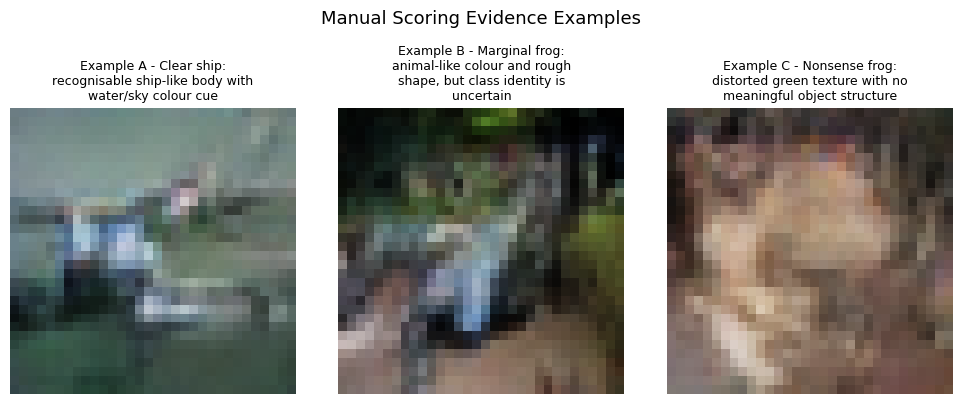

Manual scoring evidence grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\manual_quality_review\manual_scoring_evidence_examples.png


In [29]:
# Step 8.4.0: Display manual scoring evidence examples
from textwrap import wrap

REVIEW_DIR = OUTPUT_DIR / "manual_quality_review"
REVIEW_DIR.mkdir(parents=True, exist_ok=True)

manual_scoring_examples = [
    {
        "example": "Example A",
        "score": "Clear",
        "class_name": "ship",
        "image_path": FINAL_IMAGE_DIR / "08_ship" / "final_cdcgan_ship_0050.png",
        "reason": "recognisable ship-like body with water/sky colour cue",
    },
    {
        "example": "Example B",
        "score": "Marginal",
        "class_name": "frog",
        "image_path": FINAL_IMAGE_DIR / "06_frog" / "final_cdcgan_frog_0072.png",
        "reason": "animal-like colour and rough shape, but class identity is uncertain",
    },
    {
        "example": "Example C",
        "score": "Nonsense",
        "class_name": "frog",
        "image_path": FINAL_IMAGE_DIR / "06_frog" / "final_cdcgan_frog_0033.png",
        "reason": "distorted green texture with no meaningful object structure",
    },
]

manual_scoring_evidence_path = REVIEW_DIR / "manual_scoring_evidence_examples.png"

fig, axes = plt.subplots(1, len(manual_scoring_examples), figsize=(10, 3.8))

for ax, example in zip(axes, manual_scoring_examples):
    if not example["image_path"].exists():
        raise FileNotFoundError(example["image_path"])

    image = Image.open(example["image_path"]).convert("RGB")
    ax.imshow(image, interpolation="nearest")
    ax.axis("off")

    title = (
        f"{example['example']} - {example['score']}\n"
        f"{example['class_name']}: {example['reason']}"
    )
    ax.set_title("\n".join(wrap(title, width=32)), fontsize=9)

plt.suptitle("Manual Scoring Evidence Examples", fontsize=13, y=1.05)
plt.tight_layout()
fig.savefig(manual_scoring_evidence_path, dpi=150, bbox_inches="tight")
plt.show()

print("Manual scoring evidence grid saved as:", manual_scoring_evidence_path)


In [30]:
# Step 8.4.1: Save aggregate manual quality counts and create a per-file review template
manual_quality_count_entries = pd.DataFrame([
    {"class_name": "airplane", "clear_count": 28, "marginal_count": 47, "nonsense_count": 25},
    {"class_name": "automobile", "clear_count": 34, "marginal_count": 46, "nonsense_count": 20},
    {"class_name": "bird", "clear_count": 12, "marginal_count": 45, "nonsense_count": 43},
    {"class_name": "cat", "clear_count": 13, "marginal_count": 42, "nonsense_count": 45},
    {"class_name": "deer", "clear_count": 18, "marginal_count": 49, "nonsense_count": 33},
    {"class_name": "dog", "clear_count": 15, "marginal_count": 43, "nonsense_count": 42},
    {"class_name": "frog", "clear_count": 10, "marginal_count": 45, "nonsense_count": 45},
    {"class_name": "horse", "clear_count": 24, "marginal_count": 50, "nonsense_count": 26},
    {"class_name": "ship", "clear_count": 35, "marginal_count": 45, "nonsense_count": 20},
    {"class_name": "truck", "clear_count": 32, "marginal_count": 48, "nonsense_count": 20},
])


def summarise_manual_count_entries(score_count_table):
    score_table = score_count_table.copy()
    score_table["total_checked"] = (
        score_table["clear_count"]
        + score_table["marginal_count"]
        + score_table["nonsense_count"]
    )
    score_table["usable_count"] = (
        score_table["clear_count"]
        + score_table["marginal_count"]
    )
    score_table["clear_rate"] = score_table["clear_count"] / score_table["total_checked"]
    score_table["usable_rate"] = score_table["usable_count"] / score_table["total_checked"]

    return (
        score_table[
            [
                "class_name",
                "clear_count",
                "marginal_count",
                "nonsense_count",
                "total_checked",
                "usable_count",
                "clear_rate",
                "usable_rate",
            ]
        ]
        .sort_values("class_name")
        .reset_index(drop=True)
    )


def create_balanced_review_template(
    image_root_dir,
    output_path,
    image_set_name,
    images_per_class=20,
    seed=SEED,
):
    image_root_dir = Path(image_root_dir)
    rng = np.random.default_rng(seed)
    records = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        class_dir = image_root_dir / f"{class_id:02d}_{class_name}"
        image_paths = sorted(class_dir.glob("*.png"))

        if len(image_paths) < images_per_class:
            raise ValueError(
                f"{class_name} has only {len(image_paths)} images; "
                f"{images_per_class} are needed for the review template."
            )

        selected_indices = sorted(
            rng.choice(len(image_paths), size=images_per_class, replace=False).tolist()
        )

        for review_number, image_index in enumerate(selected_indices, start=1):
            image_path = image_paths[image_index]
            records.append({
                "image_set": image_set_name,
                "class_id": class_id,
                "class_name": class_name,
                "review_number": review_number,
                "image_file": image_path.name,
                "image_path": str(image_path),
                "rating": "",
                "rating_instruction": "Enter Clear, Marginal or Nonsense after visual review",
            })

    review_template = pd.DataFrame(records)
    output_path = Path(output_path)

    if output_path.exists():
        existing_template = pd.read_csv(output_path)
        merge_keys = ["image_set", "class_id", "class_name", "review_number", "image_file"]
        preserve_columns = [
            col
            for col in ["rating", "rating_source", "rating_criteria"]
            if col in existing_template.columns
        ]
        if preserve_columns and all(key in existing_template.columns for key in merge_keys):
            existing_keep = existing_template[merge_keys + preserve_columns].copy()
            review_template = review_template.drop(
                columns=[col for col in preserve_columns if col in review_template.columns],
                errors="ignore",
            ).merge(existing_keep, on=merge_keys, how="left")
            for col in preserve_columns:
                review_template[col] = review_template[col].fillna("")

    review_template.to_csv(output_path, index=False)
    return review_template


manual_quality_count_summary_path = TABLE_DIR / "manual_quality_count_summary.csv"
manual_quality_count_entries.to_csv(manual_quality_count_summary_path, index=False)

manual_quality_per_file_template_path = TABLE_DIR / "manual_quality_per_file_review_template.csv"
manual_quality_per_file_template = create_balanced_review_template(
    FINAL_IMAGE_DIR,
    manual_quality_per_file_template_path,
    "original_final_cdcgan_set",
    images_per_class=20,
    seed=SEED + 8400,
)

display(manual_quality_count_entries)
display(manual_quality_per_file_template.head(12))

print("Manual aggregate count summary saved as:", manual_quality_count_summary_path)
print("Manual per-file review template saved as:", manual_quality_per_file_template_path)


,class_name,clear_count,marginal_count,nonsense_count
0,airplane,28,47,25
1,automobile,34,46,20
2,bird,12,45,43
3,cat,13,42,45
4,deer,18,49,33
5,dog,15,43,42
6,frog,10,45,45
7,horse,24,50,26
8,ship,35,45,20
9,truck,32,48,20


,image_set,class_id,class_name,review_number,image_file,image_path,rating_instruction,rating,rating_source,rating_criteria
0,original_final_cdcgan_set,0,airplane,1,final_cdcgan_airplane_0002.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
1,original_final_cdcgan_set,0,airplane,2,final_cdcgan_airplane_0003.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
2,original_final_cdcgan_set,0,airplane,3,final_cdcgan_airplane_0005.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Nonsense,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
3,original_final_cdcgan_set,0,airplane,4,final_cdcgan_airplane_0007.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
4,original_final_cdcgan_set,0,airplane,5,final_cdcgan_airplane_0008.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
5,original_final_cdcgan_set,0,airplane,6,final_cdcgan_airplane_0009.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
6,original_final_cdcgan_set,0,airplane,7,final_cdcgan_airplane_0010.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
7,original_final_cdcgan_set,0,airplane,8,final_cdcgan_airplane_0011.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
8,original_final_cdcgan_set,0,airplane,9,final_cdcgan_airplane_0016.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
9,original_final_cdcgan_set,0,airplane,10,final_cdcgan_airplane_0021.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Nonsense,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...


Manual aggregate count summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_count_summary.csv
Manual per-file review template saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_per_file_review_template.csv


In [31]:
# Step 8.4.1a: Summarise filled per-file manual review sample
def summarise_filled_per_file_review(review_csv_path, summary_path, overall_path):
    review_csv_path = Path(review_csv_path)
    review_df = pd.read_csv(review_csv_path)

    if "rating" not in review_df.columns:
        display(pd.DataFrame([{
            "review_file": str(review_csv_path),
            "status": "rating column missing",
        }]))
        return None, None

    review_df["rating"] = review_df["rating"].fillna("").astype(str).str.strip()
    filled_review_df = review_df[review_df["rating"] != ""].copy()

    if filled_review_df.empty:
        display(pd.DataFrame([{
            "review_file": str(review_csv_path),
            "status": "ratings not filled yet",
        }]))
        return None, None

    allowed_ratings = {"Clear", "Marginal", "Nonsense"}
    invalid_ratings = sorted(set(filled_review_df["rating"]) - allowed_ratings)
    if invalid_ratings:
        raise ValueError(f"Invalid manual ratings found in {review_csv_path}: {invalid_ratings}")

    summary = (
        filled_review_df
        .pivot_table(
            index=["image_set", "class_id", "class_name"],
            columns="rating",
            values="image_file",
            aggfunc="count",
            fill_value=0,
        )
        .reset_index()
    )

    for rating_name in ["Clear", "Marginal", "Nonsense"]:
        if rating_name not in summary.columns:
            summary[rating_name] = 0

    summary = summary.rename(columns={
        "Clear": "clear_count",
        "Marginal": "marginal_count",
        "Nonsense": "nonsense_count",
    })
    summary["total_checked"] = (
        summary["clear_count"]
        + summary["marginal_count"]
        + summary["nonsense_count"]
    )
    summary["usable_count"] = summary["clear_count"] + summary["marginal_count"]
    summary["clear_rate"] = summary["clear_count"] / summary["total_checked"]
    summary["usable_rate"] = summary["usable_count"] / summary["total_checked"]
    summary = summary[
        [
            "image_set",
            "class_id",
            "class_name",
            "clear_count",
            "marginal_count",
            "nonsense_count",
            "total_checked",
            "usable_count",
            "clear_rate",
            "usable_rate",
        ]
    ].sort_values(["image_set", "class_id"])

    overall = pd.DataFrame([{
        "image_set": filled_review_df["image_set"].iloc[0],
        "images_reviewed": int(summary["total_checked"].sum()),
        "clear_count": int(summary["clear_count"].sum()),
        "marginal_count": int(summary["marginal_count"].sum()),
        "nonsense_count": int(summary["nonsense_count"].sum()),
        "usable_count": int(summary["usable_count"].sum()),
        "clear_rate": summary["clear_count"].sum() / summary["total_checked"].sum(),
        "usable_rate": summary["usable_count"].sum() / summary["total_checked"].sum(),
        "review_method": "fixed balanced 20 images per class with filename-level ratings",
    }])

    summary.to_csv(summary_path, index=False)
    overall.to_csv(overall_path, index=False)

    return summary, overall


manual_per_file_review_summary, manual_per_file_review_overall = summarise_filled_per_file_review(
    manual_quality_per_file_template_path,
    TABLE_DIR / "manual_quality_per_file_review_summary.csv",
    TABLE_DIR / "manual_quality_per_file_review_overall.csv",
)

if manual_per_file_review_summary is not None:
    display(manual_per_file_review_summary)
    display(manual_per_file_review_overall)
    print("Original per-file manual review summary saved as:", TABLE_DIR / "manual_quality_per_file_review_summary.csv")
    print("Original per-file manual review overall saved as:", TABLE_DIR / "manual_quality_per_file_review_overall.csv")


rating,image_set,class_id,class_name,clear_count,marginal_count,nonsense_count,total_checked,usable_count,clear_rate,usable_rate
0,original_final_cdcgan_set,0,airplane,6,9,5,20,15,0.30,0.75
1,original_final_cdcgan_set,1,automobile,7,9,4,20,16,0.35,0.80
2,original_final_cdcgan_set,2,bird,3,8,9,20,11,0.15,0.55
3,original_final_cdcgan_set,3,cat,3,8,9,20,11,0.15,0.55
4,original_final_cdcgan_set,4,deer,3,11,6,20,14,0.15,0.70
5,original_final_cdcgan_set,5,dog,4,8,8,20,12,0.20,0.60
6,original_final_cdcgan_set,6,frog,2,9,9,20,11,0.10,0.55
7,original_final_cdcgan_set,7,horse,6,9,5,20,15,0.30,0.75
8,original_final_cdcgan_set,8,ship,8,9,3,20,17,0.40,0.85
9,original_final_cdcgan_set,9,truck,6,10,4,20,16,0.30,0.80


,image_set,images_reviewed,clear_count,marginal_count,nonsense_count,usable_count,clear_rate,usable_rate,review_method
0,original_final_cdcgan_set,200,48,90,62,138,0.24,0.69,fixed balanced 20 images per class with filena...


Original per-file manual review summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_per_file_review_summary.csv
Original per-file manual review overall saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_per_file_review_overall.csv


### 8.4.1a Per-File Manual Audit Checkpoint

The filled per-file audit reviews a fixed balanced sample of **200 images** from the original final cDCGAN set, with **20 filenames per class**.

This is different from the full aggregate score table. The aggregate table summarises all 1000 images, while the per-file audit gives a smaller but genuinely auditable filename-level check.

The fixed sample has **48 clear**, **90 marginal** and **62 nonsense** images, giving a usable rate of **69.0%**. This closely supports the full aggregate usable rate of **68.1%**, so the manual scoring story is now more defensible.


### 8.4.1 Manual Score Table Interpretation

The manual scoring section now separates two different things clearly.

First, `manual_quality_count_summary.csv` stores the aggregate manual counts for each CIFAR10 class. These are the class-level totals used to calculate clear rate and usable rate for the full **1000-image** final cDCGAN set.

Second, `manual_quality_per_file_review_template.csv` now contains a filled fixed review sample with **20 images per class**. This gives a real filename-level audit trail without pretending that aggregate class totals identify the exact rating of every filename.

This is important because the aggregate counts give breadth, while the per-file audit gives traceability. The two forms of evidence are now used for different purposes instead of being mixed together.

Decision: use the aggregate manual counts as the full-set score, and use the filled per-file sample as supporting audit evidence.


In [32]:
# Step 8.4.2: Calculate quality rates from aggregate manual counts
manual_quality_scores = summarise_manual_count_entries(manual_quality_count_entries)

score_order = [
    "class_name",
    "clear_count",
    "marginal_count",
    "nonsense_count",
    "usable_count",
    "clear_rate",
    "usable_rate",
]

display(manual_quality_scores[score_order])


,class_name,clear_count,marginal_count,nonsense_count,usable_count,clear_rate,usable_rate
0,airplane,28,47,25,75,0.28,0.75
1,automobile,34,46,20,80,0.34,0.80
2,bird,12,45,43,57,0.12,0.57
3,cat,13,42,45,55,0.13,0.55
4,deer,18,49,33,67,0.18,0.67
5,dog,15,43,42,58,0.15,0.58
6,frog,10,45,45,55,0.10,0.55
7,horse,24,50,26,74,0.24,0.74
8,ship,35,45,20,80,0.35,0.80
9,truck,32,48,20,80,0.32,0.80


### 8.4.2 Quality Rate Interpretation

The aggregate manual counts are converted into class-level rates.

The original final cDCGAN set has **221 clear**, **460 marginal** and **319 nonsense** images. This gives an overall usable rate of **68.1%**.

The filled 200-image per-file audit gives a very similar picture: **48 clear**, **90 marginal** and **62 nonsense**, with a usable rate of **69.0%**. This does not replace the full aggregate score, but it makes the scoring process more auditable because the reviewed filenames are explicitly recorded.

The stronger classes are **automobile**, **ship** and **truck**, each with a usable rate of **80.0%** in the aggregate table. The weaker classes are **cat** and **frog** at **55.0%**, **bird** at **57.0%**, and **dog** at **58.0%**.

This supports the earlier interpretation that the model handles classes with stronger global shapes better than classes that depend on small organic details.

Decision: keep the cDCGAN because it achieves class-controlled generation, but clearly show that image quality is uneven across classes.


In [33]:
# Step 8.4.3: Save manual quality score files
manual_quality_scores_path = TABLE_DIR / "manual_quality_scores.csv"
manual_quality_scores.to_csv(manual_quality_scores_path, index=False)

summary_scores = pd.DataFrame({
    "metric": [
        "total generated images reviewed",
        "total clear images",
        "total marginal images",
        "total nonsense images",
        "overall usable images",
        "overall clear rate",
        "overall usable rate",
    ],
    "value": [
        int(manual_quality_scores["total_checked"].sum()),
        int(manual_quality_scores["clear_count"].sum()),
        int(manual_quality_scores["marginal_count"].sum()),
        int(manual_quality_scores["nonsense_count"].sum()),
        int(manual_quality_scores["usable_count"].sum()),
        manual_quality_scores["clear_count"].sum() / manual_quality_scores["total_checked"].sum(),
        manual_quality_scores["usable_count"].sum() / manual_quality_scores["total_checked"].sum(),
    ],
})

summary_scores_path = TABLE_DIR / "manual_quality_summary.csv"
summary_scores.to_csv(summary_scores_path, index=False)

display(summary_scores)

print("Manual aggregate count summary saved as:", manual_quality_count_summary_path)
print("Manual per-file review template saved as:", manual_quality_per_file_template_path)
print("Manual quality scores saved as:", manual_quality_scores_path)
print("Manual quality summary saved as:", summary_scores_path)


,metric,value
0,total generated images reviewed,1000.000
1,total clear images,221.000
2,total marginal images,460.000
3,total nonsense images,319.000
4,overall usable images,681.000
5,overall clear rate,0.221
6,overall usable rate,0.681


Manual aggregate count summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_count_summary.csv
Manual per-file review template saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_per_file_review_template.csv
Manual quality scores saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_scores.csv
Manual quality summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\manual_quality_summary.csv


### 8.4.3 Saved Score Files Interpretation

The score files now describe the evidence more honestly.

The important aggregate files are `manual_quality_count_summary.csv`, `manual_quality_scores.csv` and `manual_quality_summary.csv`.

The per-file audit files are `manual_quality_per_file_review_template.csv`, `manual_quality_per_file_review_ratings.csv`, `manual_quality_per_file_review_summary.csv` and `manual_quality_per_file_review_overall.csv`.

The aggregate summary confirms **1000 reviewed images**, with **221 clear**, **460 marginal**, **319 nonsense** and **681 usable** images. The filled per-file audit gives a smaller but traceable **200-image** filename-level check.

Decision: use the aggregate score files as the main manual-evaluation evidence for the full final cDCGAN set, and use the per-file audit as supporting evidence that the scoring rule was applied to real generated filenames.


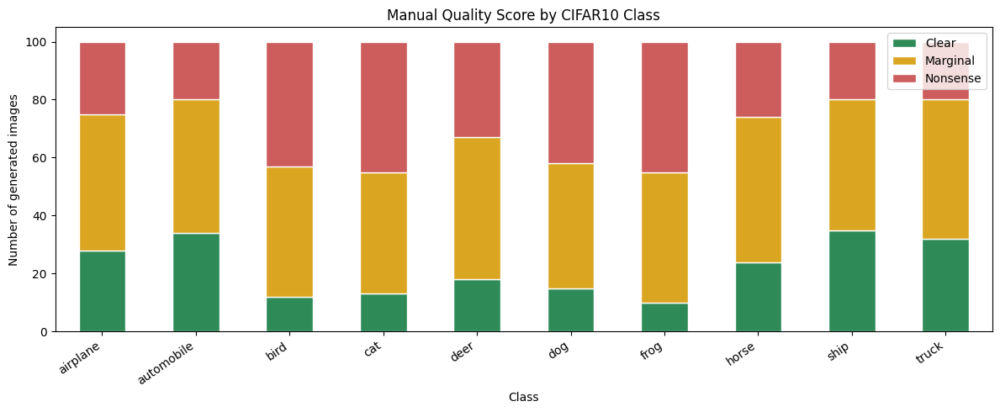

Manual quality plot saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\manual_quality_scores_by_class.png


In [34]:
# Step 8.4.4: Plot manual quality scores
score_plot_path = GRID_DIR / "manual_quality_scores_by_class.png"

plot_df = manual_quality_scores.set_index("class_name")[
    ["clear_count", "marginal_count", "nonsense_count"]
]

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 5),
    color=["seagreen", "goldenrod", "indianred"],
    edgecolor="white"
)
ax.set_title("Manual Quality Score by CIFAR10 Class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of generated images")
ax.legend(["Clear", "Marginal", "Nonsense"], loc="upper right")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(score_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Manual quality plot saved as:", score_plot_path)


### 8.4.4 Manual Scoring Outcome

The final scoring block creates a stacked bar chart of the manual scores.

The chart makes the class-level differences easier to see. It shows that the cDCGAN performs better on classes with stronger global shapes, such as **automobile**, **truck** and **ship**. These classes have clearer visual patterns, such as box-like bodies, wheels, horizontal ship shapes, sea/sky backgrounds or road-like colour cues.

The weaker results appear in classes such as **cat**, **dog**, **bird** and **frog**. These classes are harder because they depend more on small organic details, body posture and fine edges. At **32x32** resolution, the generator often learns the colour or texture cue before it learns the full object structure.

So the improvement is only partially successful:

| Question | Answer |
|----------|--------|
| Did conditioning fix class control? | Yes, the model generated 100 images per class |
| Did it fully fix image quality? | No, many samples are still marginal or nonsense |
| How do I know? | the manual scores show only 221 clear images out of 1000 |
| What is the workaround? | report the limitation honestly and use class-wise evaluation evidence |

Decision: keep the final cDCGAN because it satisfies the class-controlled generation requirement, but clearly state that image recognisability remains limited, especially for organic classes.


### 8.5 Decision After Manual Scoring

The manual scoring shows that Improvement 1 was successful for **class control**, but only partially successful for image recognisability.

The evidence is:

| Evaluation point | Result |
|------------------|--------|
| total generated images reviewed | 1000 |
| clear images | 221 |
| marginal images | 460 |
| nonsense images | 319 |
| overall clear rate | 22.1% |
| overall usable rate | 68.1% |

The final cDCGAN still produced many usable CIFAR10-like samples, but the clear rate is low. This means it would be inaccurate to say that all generated images are recognisable.

The problem now is **sample quality variation**. Some random latent vectors produce stronger images, while others produce distorted or unclear outputs. Since this is partly a training issue and partly a sample-selection issue, the next steps separate the two responses clearly.

Decision: first test a real training improvement using lower-learning-rate fine-tuning, then treat candidate-pool selection only as post-generation quality control.

### 8.6 Overall Manual Score Comparison

After scoring the final cDCGAN, the baseline and final models can be compared using the same manual categories.

This comparison is placed here because the final cDCGAN scores are only available after the generated 1000 images have been reviewed.

In [35]:
# Step 8.6: Save overall manual score comparison
overall_manual_score_comparison = pd.DataFrame([
    {
        "model": "Baseline VAE",
        "images_checked": 100,
        "clear": 0,
        "marginal": 28,
        "nonsense": 72,
        "decision": "stable but blurry",
    },
    {
        "model": "Baseline DCGAN",
        "images_checked": 100,
        "clear": 20,
        "marginal": 48,
        "nonsense": 32,
        "decision": "sharper, chosen for cDCGAN",
    },
    {
        "model": "Final cDCGAN",
        "images_checked": 1000,
        "clear": 221,
        "marginal": 460,
        "nonsense": 319,
        "decision": "class-controlled final model",
    },
])

overall_manual_score_comparison["usable"] = (
    overall_manual_score_comparison["clear"]
    + overall_manual_score_comparison["marginal"]
)
overall_manual_score_comparison["usable_rate"] = (
    overall_manual_score_comparison["usable"]
    / overall_manual_score_comparison["images_checked"]
)

overall_manual_score_path = TABLE_DIR / "overall_manual_score_comparison.csv"
overall_manual_score_comparison.to_csv(overall_manual_score_path, index=False)

display(overall_manual_score_comparison)

print("Overall manual score comparison saved as:", overall_manual_score_path)


,model,images_checked,clear,marginal,nonsense,decision,usable,usable_rate
0,Baseline VAE,100,0,28,72,stable but blurry,28,0.280
1,Baseline DCGAN,100,20,48,32,"sharper, chosen for cDCGAN",68,0.680
2,Final cDCGAN,1000,221,460,319,class-controlled final model,681,0.681


Overall manual score comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\overall_manual_score_comparison.csv


### 8.6.1 Overall Manual Score Interpretation

The full manual score table makes the model choice clearer.

| Model | Evidence-based judgement |
|-------|--------------------------|
| Baseline VAE | useful as a stable baseline, but too noisy and blurry for the final image set |
| Baseline DCGAN | visually stronger than the VAE, so it is the better direction to improve |
| Final cDCGAN | keeps the GAN direction and adds class control for the 1000-image requirement |

The final cDCGAN is not perfect, but it solves the class-specific generation requirement while keeping a reasonable usable rate.

Decision: continue with improvement experiments and post-generation quality control.

## 9. Improvement 2: Controlled Learning Rate Fine-Tuning Experiment

The second improvement is an actual **training improvement**, not a post-generation filtering step.

The manual review showed that many samples are only marginal or distorted. One possible reason is GAN training instability: if the generator and discriminator update too aggressively, the generated images can change sharply without settling into clearer object structure.

| Question | Explanation |
|----------|-------------|
| What problem did I see? | the cDCGAN produced class-controlled images, but many were still distorted |
| Why might this happen? | adversarial training can be unstable when updates are too aggressive |
| How do I plan to test it? | branch from the same epoch-80 cDCGAN checkpoint and train both branches for 20 more epochs |
| What factor changes? | continuation learning rate: `0.0002` versus `0.0001` |
| What stays the same? | starting weights, architecture, dataset, latent dimension and class labels |
| How will I check it? | compare both continued branches using the same latent noise, labels and proxy metrics |

Decision: test learning rate as a controlled branch experiment before using any post-generation selection workaround.


### 9.1 Train or Load Controlled LR Branches

This step creates two continuation branches from the same final cDCGAN checkpoint.

Branch A continues training for **20 epochs** with the original GAN learning rate, `0.0002`. Branch B continues training for the same **20 epochs** with the lower learning rate, `0.0001`.

This is more controlled than comparing the epoch-80 model directly against an epoch-100 lower-LR model, because both branches now receive the same amount of extra training.


Loading existing standard-LR continuation cDCGAN weights.
standard-LR continuation cDCGAN generator weights: loaded with standard Keras loader
standard-LR continuation cDCGAN discriminator weights: loaded with standard Keras loader


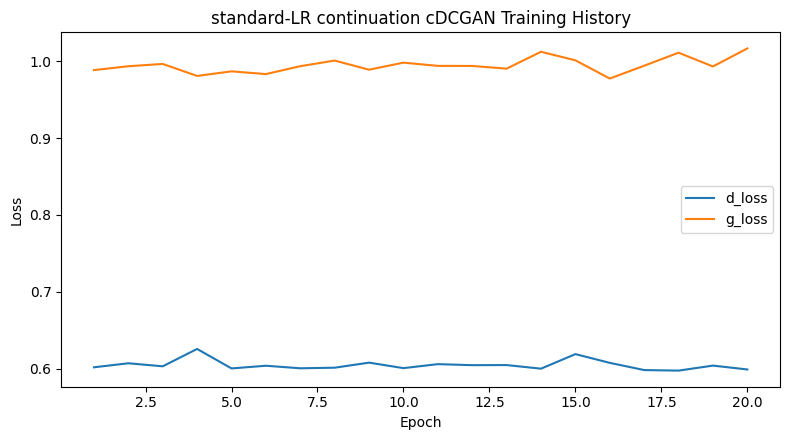

Loading existing lower-LR continuation cDCGAN weights.
lower-LR continuation cDCGAN generator weights: loaded with standard Keras loader
lower-LR continuation cDCGAN discriminator weights: loaded with standard Keras loader


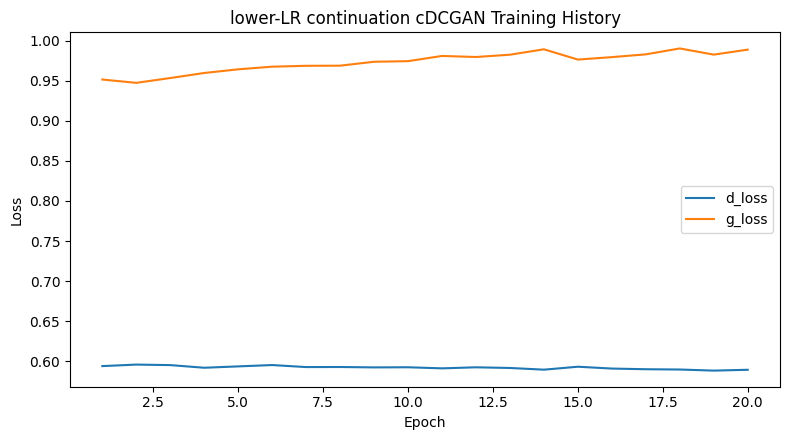

,branch,learning_rate,extra_epochs,rng_seed_before_fit,data_order_seed,reshuffle_each_iteration,weights_found,history_csv_found,control_csv_found
0,standard-LR continuation cDCGAN,0.0002,20,9188,9189,False,True,True,True
1,lower-LR continuation cDCGAN,0.0001,20,9188,9189,False,True,True,True


,branch_key,display_name,starting_checkpoint,changed_factor,learning_rate,extra_epochs,rng_seed_before_fit,data_order_seed,shuffle_buffer,reshuffle_each_iteration,deterministic_dataset_order,same_starting_weights,same_batch_size,training_status
0,controlled_standard_lr_cdcgan,standard-LR continuation cDCGAN,final cDCGAN after 80 epochs,learning_rate,0.0002,20,9188,9189,50000,False,True,True,128,trained_with_matched_rng_and_data_order
1,controlled_low_lr_cdcgan,lower-LR continuation cDCGAN,final cDCGAN after 80 epochs,learning_rate,0.0001,20,9188,9189,50000,False,True,True,128,trained_with_matched_rng_and_data_order


,epoch,d_loss,g_loss
17,18,0.597364,1.011322
18,19,0.603899,0.993375
19,20,0.598849,1.016849


,epoch,d_loss,g_loss
17,18,0.589611,0.990319
18,19,0.588249,0.982605
19,20,0.589281,0.988833


In [36]:
# Step 9.1: Train or load controlled learning-rate continuation branches
STANDARD_LR = GAN_LEARNING_RATE
CONTROLLED_LOW_LR = LOW_LR
LR_BRANCH_RNG_SEED = SEED + 9100
LR_BRANCH_DATA_ORDER_SEED = SEED + 9101


def make_controlled_lr_branch_dataset():
    options = tf.data.Options()
    options.experimental_deterministic = True

    lr_branch_ds = (
        tf.data.Dataset.from_tensor_slices((X_train_gan, y_train.astype("int32")))
        .shuffle(
            buffer_size=len(X_train_gan),
            seed=LR_BRANCH_DATA_ORDER_SEED,
            reshuffle_each_iteration=False
        )
        .batch(BATCH_SIZE, drop_remainder=True)
        .prefetch(tf.data.AUTOTUNE)
    )

    return lr_branch_ds.with_options(options)


def train_or_load_lr_branch(branch_key, display_name, learning_rate, monitor_prefix):
    generator_weights_path = MODEL_DIR / f"{branch_key}_generator.weights.h5"
    discriminator_weights_path = MODEL_DIR / f"{branch_key}_discriminator.weights.h5"
    history_path = TABLE_DIR / f"{branch_key}_training_history.csv"
    control_path = TABLE_DIR / f"{branch_key}_training_controls.csv"
    history_plot_path = GRID_DIR / f"{branch_key}_training_history.png"

    generator = build_cdcgan_generator()
    discriminator = build_cdcgan_discriminator()
    model = ConditionalDCGAN(generator, discriminator, name=branch_key)
    model.compile(
        d_optimizer=keras.optimizers.Adam(learning_rate=learning_rate, beta_1=0.5),
        g_optimizer=keras.optimizers.Adam(learning_rate=learning_rate, beta_1=0.5),
        loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
    )

    history_df = load_training_history(history_path)
    branch_control_record = {
        "branch_key": branch_key,
        "display_name": display_name,
        "starting_checkpoint": f"final cDCGAN after {FINAL_CDCGAN_EPOCHS} epochs",
        "changed_factor": "learning_rate",
        "learning_rate": learning_rate,
        "extra_epochs": LR_BRANCH_EPOCHS,
        "rng_seed_before_fit": LR_BRANCH_RNG_SEED,
        "data_order_seed": LR_BRANCH_DATA_ORDER_SEED,
        "shuffle_buffer": len(X_train_gan),
        "reshuffle_each_iteration": False,
        "deterministic_dataset_order": True,
        "same_starting_weights": True,
        "same_batch_size": BATCH_SIZE,
    }

    if generator_weights_path.exists() and discriminator_weights_path.exists():
        print(f"Loading existing {display_name} weights.")
        generator_load_status = load_weights_compat(generator, generator_weights_path)
        discriminator_load_status = load_weights_compat(discriminator, discriminator_weights_path)
        print(f"{display_name} generator weights:", generator_load_status)
        print(f"{display_name} discriminator weights:", discriminator_load_status)

        if control_path.exists():
            branch_control_df = pd.read_csv(control_path)
        else:
            branch_control_record["training_status"] = "loaded_existing_weights_control_metadata_missing"
            branch_control_df = pd.DataFrame([branch_control_record])
            branch_control_df.to_csv(control_path, index=False)
    else:
        print(f"Starting {display_name} from the same final cDCGAN checkpoint.")
        generator_load_status = load_weights_compat(generator, final_cdcgan_generator_weights_path)
        discriminator_load_status = load_weights_compat(discriminator, final_cdcgan_discriminator_weights_path)
        print(f"Starting generator weights:", generator_load_status)
        print(f"Starting discriminator weights:", discriminator_load_status)

        keras.utils.set_random_seed(LR_BRANCH_RNG_SEED)
        controlled_lr_train_ds = make_controlled_lr_branch_dataset()
        history = model.fit(
            controlled_lr_train_ds,
            epochs=LR_BRANCH_EPOCHS,
            callbacks=[
                ConditionalGANMonitor(
                    generator=generator,
                    latent_dim=LATENT_DIM,
                    class_names=CLASS_NAMES,
                    output_dir=SAMPLE_DIR,
                    prefix=monitor_prefix,
                    examples_per_class=5,
                    save_every=5,
                )
            ],
            verbose=0,
        )

        generator.save_weights(generator_weights_path)
        discriminator.save_weights(discriminator_weights_path)
        history_df = history_to_dataframe(history)
        history_df.to_csv(history_path, index=False)
        branch_control_record["training_status"] = "trained_with_matched_rng_and_data_order"
        branch_control_df = pd.DataFrame([branch_control_record])
        branch_control_df.to_csv(control_path, index=False)

        print(f"Saved {display_name} generator weights:", generator_weights_path)
        print(f"Saved {display_name} discriminator weights:", discriminator_weights_path)
        print(f"Saved {display_name} training history:", history_path)
        print(f"Saved {display_name} control metadata:", control_path)

    saved_plot = save_training_history_plot(
        history_df,
        ["d_loss", "g_loss"],
        history_plot_path,
        f"{display_name} Training History"
    )

    return {
        "branch_key": branch_key,
        "display_name": display_name,
        "learning_rate": learning_rate,
        "generator": generator,
        "discriminator": discriminator,
        "history_df": history_df,
        "control_df": branch_control_df,
        "generator_weights_path": generator_weights_path,
        "discriminator_weights_path": discriminator_weights_path,
        "history_path": history_path,
        "control_path": control_path,
        "history_plot_path": saved_plot,
    }


standard_lr_branch = train_or_load_lr_branch(
    branch_key="controlled_standard_lr_cdcgan",
    display_name="standard-LR continuation cDCGAN",
    learning_rate=STANDARD_LR,
    monitor_prefix="controlled_standard_lr_cdcgan",
)

low_lr_branch = train_or_load_lr_branch(
    branch_key="controlled_low_lr_cdcgan",
    display_name="lower-LR continuation cDCGAN",
    learning_rate=CONTROLLED_LOW_LR,
    monitor_prefix="controlled_low_lr_cdcgan",
)

standard_lr_cdcgan_generator = standard_lr_branch["generator"]
low_lr_cdcgan_generator = low_lr_branch["generator"]

lr_branch_training_summary = pd.DataFrame([
    {
        "branch": standard_lr_branch["display_name"],
        "learning_rate": standard_lr_branch["learning_rate"],
        "extra_epochs": LR_BRANCH_EPOCHS,
        "rng_seed_before_fit": LR_BRANCH_RNG_SEED,
        "data_order_seed": LR_BRANCH_DATA_ORDER_SEED,
        "reshuffle_each_iteration": False,
        "weights_found": standard_lr_branch["generator_weights_path"].exists()
        and standard_lr_branch["discriminator_weights_path"].exists(),
        "history_csv_found": standard_lr_branch["history_path"].exists(),
        "control_csv_found": standard_lr_branch["control_path"].exists(),
    },
    {
        "branch": low_lr_branch["display_name"],
        "learning_rate": low_lr_branch["learning_rate"],
        "extra_epochs": LR_BRANCH_EPOCHS,
        "rng_seed_before_fit": LR_BRANCH_RNG_SEED,
        "data_order_seed": LR_BRANCH_DATA_ORDER_SEED,
        "reshuffle_each_iteration": False,
        "weights_found": low_lr_branch["generator_weights_path"].exists()
        and low_lr_branch["discriminator_weights_path"].exists(),
        "history_csv_found": low_lr_branch["history_path"].exists(),
        "control_csv_found": low_lr_branch["control_path"].exists(),
    },
])

display(lr_branch_training_summary)
display(pd.concat(
    [standard_lr_branch["control_df"], low_lr_branch["control_df"]],
    ignore_index=True
))

if standard_lr_branch["history_df"] is not None:
    display(standard_lr_branch["history_df"].tail(3))

if low_lr_branch["history_df"] is not None:
    display(low_lr_branch["history_df"].tail(3))


### 9.1.1 Controlled LR Training Checkpoint

This experiment now controls the learning-rate comparison more tightly.

Both continuation branches start from the same epoch-80 cDCGAN checkpoint and train for **20 additional epochs**. The changed factor is the learning rate, so I also fix the branch-level random seed and rebuild the training dataset with the same fixed shuffle order for both branches.

This matters because GAN training is sensitive to randomness. If the two branches used different data orders or different random-noise sequences during training, a better result could be caused by training noise instead of the learning-rate change. By saving the RNG seed and data-order seed in the branch control table, the comparison becomes easier to audit.


### 9.2 Controlled LR Preview Comparison

This step compares the epoch-80 cDCGAN reference, the standard-LR continuation and the lower-LR continuation using the same preview noise and ordered class labels.

The important comparison is between the two continuation branches. The epoch-80 model is kept as a reference point, but the decision should not be based on it alone because both continuation branches receive extra training time.


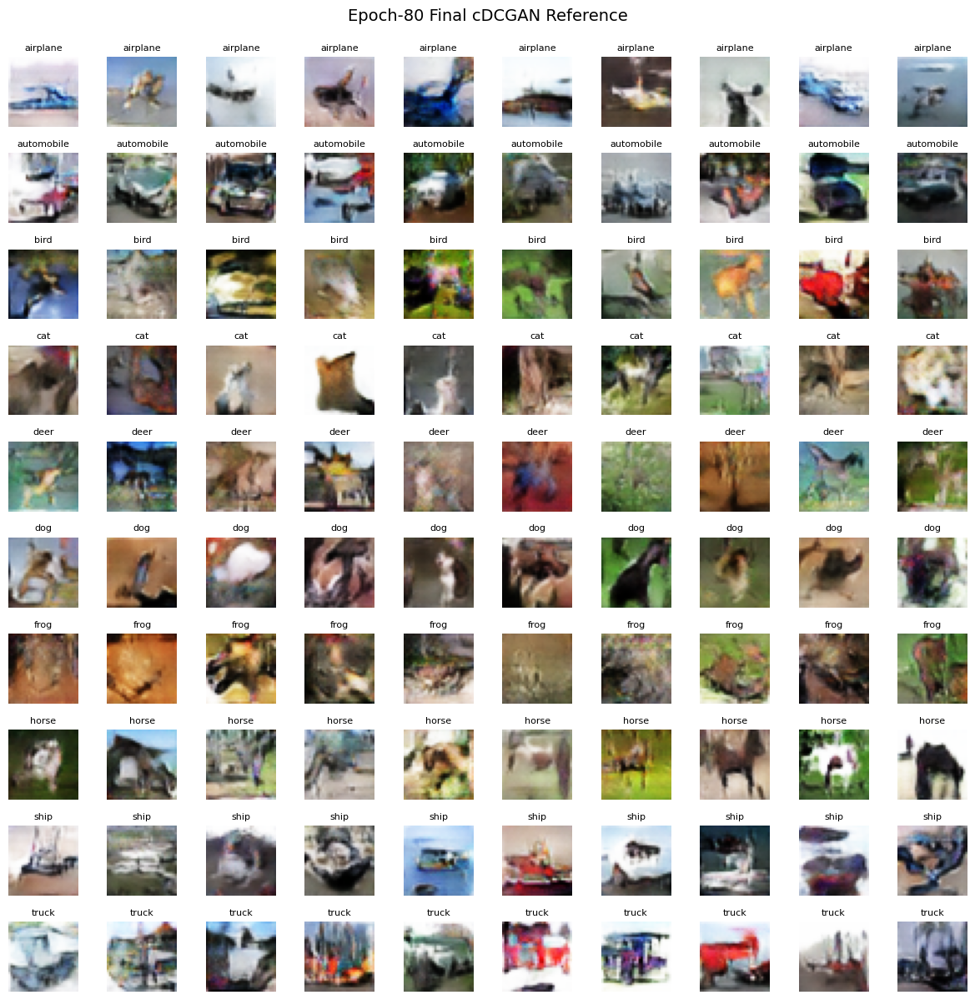

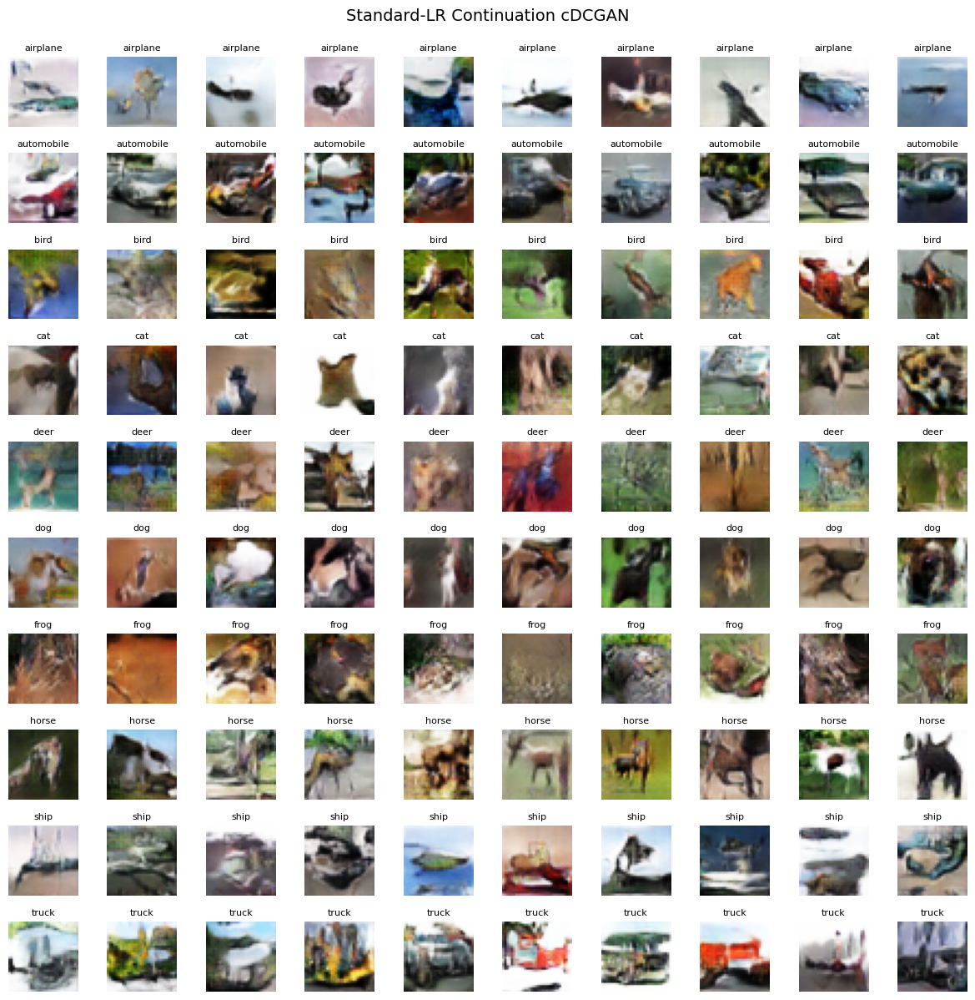

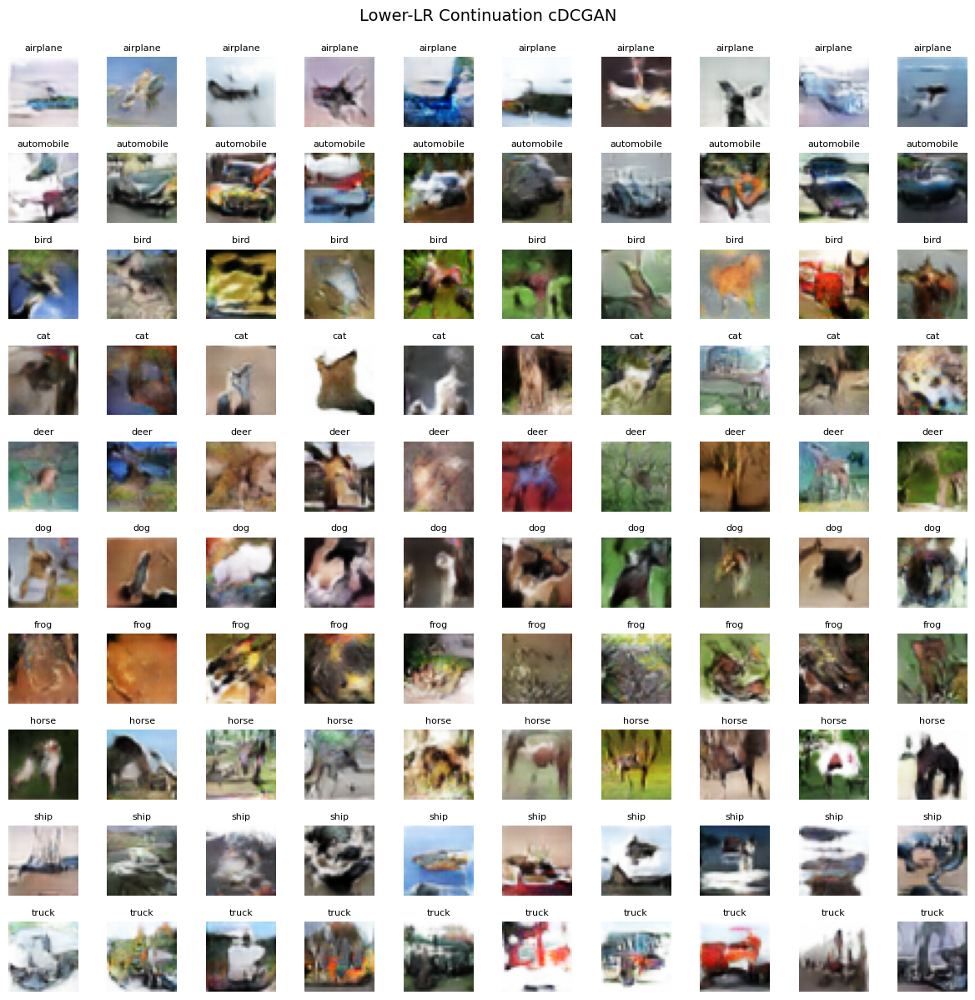

,image_set,image_count,mean_contrast,mean_color_variation,mean_edge_strength,mean_brightness_penalty,proxy_score
2,standard_lr_continued_cdcgan,100,50.798012,52.199547,29.542011,0.228121,37.473308
0,epoch80_final_cdcgan_reference,100,50.122482,51.577396,28.610035,0.212674,36.774971
1,low_lr_continued_cdcgan,100,50.174427,51.668514,28.342070,0.221867,36.700672


,experiment,changed_factor,starting_checkpoint,extra_epochs_per_branch,standard_lr,low_lr,controlled_noise,controlled_labels,controlled_training_rng,controlled_training_data_order,epoch80_reference_proxy_score,standard_lr_proxy_score,low_lr_proxy_score,proxy_score_change_low_vs_standard,proxy_decision,final_note
0,Controlled learning-rate continuation,learning rate during 20-epoch continuation fro...,final cDCGAN after 80 epochs,20,0.0002,0.0001,same latent noise tensor used for all previews,same ordered CIFAR10 labels used for all previews,same RNG seed before each branch fit: 9188,same fixed shuffle seed and no epoch reshuffle...,36.774971,37.473308,36.700672,-0.772637,standard LR continuation remains stronger by p...,visual inspection is still needed because prox...


epoch80_final_cdcgan_reference preview grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\epoch80_final_cdcgan_reference_controlled_preview_100.png
standard_lr_continued_cdcgan preview grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\standard_lr_continued_cdcgan_controlled_preview_100.png
low_lr_continued_cdcgan preview grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\low_lr_continued_cdcgan_controlled_preview_100.png
Controlled LR proxy comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\low_lr_training_improvement_proxy_comparison.csv
Controlled LR decision saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\low_lr_training_improvement_decision.csv


In [37]:
# Step 9.2: Generate and compare controlled LR branch preview samples
LR_PREVIEW_IMAGES_PER_CLASS = 10
LR_PREVIEW_TOTAL = LR_PREVIEW_IMAGES_PER_CLASS * NUM_CLASSES


def image_quality_features_from_array(image):
    image = np.asarray(image).astype("float32")
    gray = image.mean(axis=2)

    contrast = gray.std()
    color_variation = image.std(axis=(0, 1)).mean()

    grad_x = np.abs(np.diff(gray, axis=1)).mean()
    grad_y = np.abs(np.diff(gray, axis=0)).mean()
    edge_strength = grad_x + grad_y

    brightness = gray.mean()
    brightness_penalty = abs(brightness - 127.5) / 127.5

    return {
        "contrast": contrast,
        "color_variation": color_variation,
        "edge_strength": edge_strength,
        "brightness_penalty": brightness_penalty,
    }


comparison_labels_np = np.repeat(
    np.arange(NUM_CLASSES),
    LR_PREVIEW_IMAGES_PER_CLASS
).astype("int32")
comparison_labels = tf.constant(comparison_labels_np, dtype=tf.int32)
comparison_noise = tf.random.stateless_normal(
    shape=(LR_PREVIEW_TOTAL, LATENT_DIM),
    seed=[SEED, 9200]
)
comparison_class_labels = [CLASS_NAMES[class_id] for class_id in comparison_labels_np]

lr_preview_generators = [
    ("epoch80_final_cdcgan_reference", "Epoch-80 Final cDCGAN Reference", final_cdcgan_generator),
    ("standard_lr_continued_cdcgan", "Standard-LR Continuation cDCGAN", standard_lr_cdcgan_generator),
    ("low_lr_continued_cdcgan", "Lower-LR Continuation cDCGAN", low_lr_cdcgan_generator),
]

lr_preview_images = {}
lr_preview_grid_paths = {}

for image_set, title, generator in lr_preview_generators:
    generated = generator.predict([comparison_noise, comparison_labels], verbose=0)
    generated_images = gan_output_to_uint8(generated)
    lr_preview_images[image_set] = generated_images

    grid_path = GRID_DIR / f"{image_set}_controlled_preview_100.png"
    save_image_grid(generated_images, grid_path, columns=10)
    lr_preview_grid_paths[image_set] = grid_path

    show_image_grid(
        generated_images,
        title=title,
        class_labels=comparison_class_labels,
        columns=10,
        figsize=(12, 12)
    )

preview_quality_records = []

for image_set, image_array in lr_preview_images.items():
    for image in image_array:
        preview_quality_records.append({
            "image_set": image_set,
            **image_quality_features_from_array(image),
        })

preview_quality_features = pd.DataFrame(preview_quality_records)
low_lr_proxy_comparison = (
    preview_quality_features
    .groupby("image_set")
    .agg(
        image_count=("contrast", "count"),
        mean_contrast=("contrast", "mean"),
        mean_color_variation=("color_variation", "mean"),
        mean_edge_strength=("edge_strength", "mean"),
        mean_brightness_penalty=("brightness_penalty", "mean"),
    )
    .reset_index()
)

low_lr_proxy_comparison["proxy_score"] = (
    0.40 * low_lr_proxy_comparison["mean_edge_strength"]
    + 0.30 * low_lr_proxy_comparison["mean_contrast"]
    + 0.20 * low_lr_proxy_comparison["mean_color_variation"]
    - 0.10 * low_lr_proxy_comparison["mean_brightness_penalty"]
)

score_lookup = dict(zip(
    low_lr_proxy_comparison["image_set"],
    low_lr_proxy_comparison["proxy_score"],
))

epoch80_reference_score = float(score_lookup["epoch80_final_cdcgan_reference"])
standard_lr_score = float(score_lookup["standard_lr_continued_cdcgan"])
low_lr_score = float(score_lookup["low_lr_continued_cdcgan"])

LOW_LR_ACCEPTED_BY_PROXY = low_lr_score > standard_lr_score

low_lr_decision = pd.DataFrame([
    {
        "experiment": "Controlled learning-rate continuation",
        "changed_factor": "learning rate during 20-epoch continuation from the same epoch-80 checkpoint",
        "starting_checkpoint": f"final cDCGAN after {FINAL_CDCGAN_EPOCHS} epochs",
        "extra_epochs_per_branch": LR_BRANCH_EPOCHS,
        "standard_lr": STANDARD_LR,
        "low_lr": CONTROLLED_LOW_LR,
        "controlled_noise": "same latent noise tensor used for all previews",
        "controlled_labels": "same ordered CIFAR10 labels used for all previews",
        "controlled_training_rng": f"same RNG seed before each branch fit: {LR_BRANCH_RNG_SEED}",
        "controlled_training_data_order": f"same fixed shuffle seed and no epoch reshuffle: {LR_BRANCH_DATA_ORDER_SEED}",
        "epoch80_reference_proxy_score": epoch80_reference_score,
        "standard_lr_proxy_score": standard_lr_score,
        "low_lr_proxy_score": low_lr_score,
        "proxy_score_change_low_vs_standard": low_lr_score - standard_lr_score,
        "proxy_decision": (
            "lower LR accepted for visual review"
            if LOW_LR_ACCEPTED_BY_PROXY
            else "standard LR continuation remains stronger by proxy"
        ),
        "final_note": "visual inspection is still needed because proxy scores cannot prove class recognisability",
    }
])

low_lr_proxy_path = TABLE_DIR / "low_lr_training_improvement_proxy_comparison.csv"
low_lr_decision_path = TABLE_DIR / "low_lr_training_improvement_decision.csv"

low_lr_proxy_comparison.to_csv(low_lr_proxy_path, index=False)
low_lr_decision.to_csv(low_lr_decision_path, index=False)

display(low_lr_proxy_comparison.sort_values("proxy_score", ascending=False))
display(low_lr_decision)

for image_set, grid_path in lr_preview_grid_paths.items():
    print(f"{image_set} preview grid saved as:", grid_path)

print("Controlled LR proxy comparison saved as:", low_lr_proxy_path)
print("Controlled LR decision saved as:", low_lr_decision_path)


### 9.2.1 Controlled LR Experiment Interpretation

This comparison closes the earlier experimental-design issue.

The lower-learning-rate branch is no longer compared only against the epoch-80 cDCGAN. It is compared against a standard-learning-rate branch that also receives **20 extra epochs** from the same starting checkpoint.

The branch setup also records the same RNG seed and the same fixed data-order seed for both continuations. This is important because it makes the experiment more focused: the main difference being tested is the learning rate, not a different shuffle order or a different random training sequence.

After rerunning the branches under these matched controls, the deterministic preview gives a proxy score of **36.77** for the epoch-80 reference, **37.47** for the standard-LR continuation and **36.70** for the lower-LR continuation.

This changes my earlier interpretation. Once the training conditions are more tightly controlled, the proxy metric does **not** support lower-LR as the stronger branch. It slightly favours the standard-LR continuation instead.

Decision: continue to the manual LR review before making a final judgement. The proxy score measures contrast, colour and edge strength, but it does not directly answer whether the generated image is recognisable as the requested CIFAR10 class.


### 9.2.2 Controlled LR Manual Review

The proxy score suggests that the lower-LR branch is worth checking, but proxy metrics do not directly measure class recognisability.

To make the LR decision auditable, I use the fixed same-noise preview samples from Section 9.2 and record the judgement in two CSV files. The first file stores the per-image **Clear / Marginal / Nonsense** rating for all 200 branch images. The second file stores the same-noise pair preference for all 100 matched pairs.

This gives the experiment an evidence trail: the notebook can show the summary, while the CSV files show the underlying image-level decisions that produced it.


In [38]:
# Step 9.2.2: Load fixed LR branch manual recognisability review
lr_manual_rating_review_path = TABLE_DIR / "lr_branch_manual_rating_review.csv"
lr_manual_rating_overall_path = TABLE_DIR / "lr_branch_manual_rating_overall.csv"
lr_manual_rating_summary_path = TABLE_DIR / "lr_branch_manual_rating_summary.csv"
lr_pair_review_path = TABLE_DIR / "lr_branch_manual_pair_comparison.csv"
lr_pair_overall_path = TABLE_DIR / "lr_branch_manual_pair_overall.csv"
lr_pair_summary_path = TABLE_DIR / "lr_branch_manual_pair_summary.csv"

if (
    lr_manual_rating_review_path.exists()
    and lr_manual_rating_overall_path.exists()
    and lr_manual_rating_summary_path.exists()
    and lr_pair_review_path.exists()
    and lr_pair_overall_path.exists()
    and lr_pair_summary_path.exists()
):
    lr_manual_rating_review = pd.read_csv(lr_manual_rating_review_path)
    lr_manual_rating_overall = pd.read_csv(lr_manual_rating_overall_path)
    lr_manual_rating_summary = pd.read_csv(lr_manual_rating_summary_path)
    lr_pair_review = pd.read_csv(lr_pair_review_path)
    lr_pair_overall = pd.read_csv(lr_pair_overall_path)
    lr_pair_summary = pd.read_csv(lr_pair_summary_path)

    lr_manual_audit_completion = pd.DataFrame([
        {
            "audit_file": "lr_branch_manual_rating_review.csv",
            "rows": len(lr_manual_rating_review),
            "filled_rows": int(lr_manual_rating_review["rating"].notna().sum()),
            "purpose": "per-image Clear / Marginal / Nonsense ratings",
        },
        {
            "audit_file": "lr_branch_manual_pair_comparison.csv",
            "rows": len(lr_pair_review),
            "filled_rows": int(lr_pair_review["preferred_branch"].notna().sum()),
            "purpose": "same-noise pair preference for each preview index",
        },
    ])

    lr_rating_evidence_columns = [
        "branch_name", "class_name", "review_number", "image_file", "rating"
    ]
    lr_pair_evidence_columns = [
        "class_name", "review_number", "standard_image_file",
        "lower_lr_image_file", "preferred_branch", "comparison_reason"
    ]

    display(lr_manual_audit_completion)
    display(lr_manual_rating_overall)
    display(lr_pair_overall)
    display(lr_pair_summary)
    display(lr_manual_rating_review[lr_rating_evidence_columns].head(12))
    display(lr_pair_review[lr_pair_evidence_columns].head(12))

    print("Per-image LR manual rating CSV:", lr_manual_rating_review_path)
    print("Per-pair LR comparison CSV:", lr_pair_review_path)
    print("LR branch manual rating overall loaded from:", lr_manual_rating_overall_path)
    print("LR branch pair comparison overall loaded from:", lr_pair_overall_path)
else:
    display(pd.DataFrame([{
        "status": "LR manual review files not found yet",
        "expected_files": (
            "lr_branch_manual_rating_review.csv, "
            "lr_branch_manual_pair_comparison.csv and summary files"
        ),
    }]))


,audit_file,rows,filled_rows,purpose
0,lr_branch_manual_rating_review.csv,200,200,per-image Clear / Marginal / Nonsense ratings
1,lr_branch_manual_pair_comparison.csv,100,100,same-noise pair preference for each preview index


,branch_key,branch_name,images_reviewed,clear_count,marginal_count,nonsense_count,usable_count,clear_rate,usable_rate
0,low_lr_continued_cdcgan,lower-LR continuation cDCGAN,100,31,61,8,92,0.31,0.92
1,standard_lr_continued_cdcgan,standard-LR continuation cDCGAN,100,29,61,10,90,0.29,0.90


,pairs_reviewed,lower_lr_preferred_count,standard_lr_preferred_count,tie_count,review_method
0,100,21,10,69,"same-noise fixed pair comparison, 10 samples p..."


,class_id,class_name,lower_lr_preferred_count,standard_lr_preferred_count,tie_count,pairs_reviewed
0,0,airplane,1,1,8,10
1,1,automobile,4,1,5,10
2,2,bird,4,0,6,10
3,3,cat,3,0,7,10
4,4,deer,2,0,8,10
5,5,dog,2,2,6,10
6,6,frog,2,2,6,10
7,7,horse,0,1,9,10
8,8,ship,3,0,7,10
9,9,truck,0,3,7,10


,branch_name,class_name,review_number,image_file,rating
0,standard-LR continuation cDCGAN,airplane,1,standard_lr_continued_cdcgan_airplane_0001.png,Marginal
1,standard-LR continuation cDCGAN,airplane,2,standard_lr_continued_cdcgan_airplane_0002.png,Clear
2,standard-LR continuation cDCGAN,airplane,3,standard_lr_continued_cdcgan_airplane_0003.png,Marginal
3,standard-LR continuation cDCGAN,airplane,4,standard_lr_continued_cdcgan_airplane_0004.png,Clear
4,standard-LR continuation cDCGAN,airplane,5,standard_lr_continued_cdcgan_airplane_0005.png,Marginal
5,standard-LR continuation cDCGAN,airplane,6,standard_lr_continued_cdcgan_airplane_0006.png,Marginal
6,standard-LR continuation cDCGAN,airplane,7,standard_lr_continued_cdcgan_airplane_0007.png,Clear
7,standard-LR continuation cDCGAN,airplane,8,standard_lr_continued_cdcgan_airplane_0008.png,Marginal
8,standard-LR continuation cDCGAN,airplane,9,standard_lr_continued_cdcgan_airplane_0009.png,Marginal
9,standard-LR continuation cDCGAN,airplane,10,standard_lr_continued_cdcgan_airplane_0010.png,Marginal


,class_name,review_number,standard_image_file,lower_lr_image_file,preferred_branch,comparison_reason
0,airplane,1,standard_lr_continued_cdcgan_airplane_0001.png,low_lr_continued_cdcgan_airplane_0001.png,standard-LR,standard-LR sample has slightly clearer class-...
1,airplane,2,standard_lr_continued_cdcgan_airplane_0002.png,low_lr_continued_cdcgan_airplane_0002.png,tie,both samples have similar recognisability
2,airplane,3,standard_lr_continued_cdcgan_airplane_0003.png,low_lr_continued_cdcgan_airplane_0003.png,tie,both samples have similar recognisability
3,airplane,4,standard_lr_continued_cdcgan_airplane_0004.png,low_lr_continued_cdcgan_airplane_0004.png,tie,both samples have similar recognisability
4,airplane,5,standard_lr_continued_cdcgan_airplane_0005.png,low_lr_continued_cdcgan_airplane_0005.png,tie,both samples have similar recognisability
5,airplane,6,standard_lr_continued_cdcgan_airplane_0006.png,low_lr_continued_cdcgan_airplane_0006.png,tie,both samples have similar recognisability
6,airplane,7,standard_lr_continued_cdcgan_airplane_0007.png,low_lr_continued_cdcgan_airplane_0007.png,tie,both samples have similar recognisability
7,airplane,8,standard_lr_continued_cdcgan_airplane_0008.png,low_lr_continued_cdcgan_airplane_0008.png,tie,both samples have similar recognisability
8,airplane,9,standard_lr_continued_cdcgan_airplane_0009.png,low_lr_continued_cdcgan_airplane_0009.png,tie,both samples have similar recognisability
9,airplane,10,standard_lr_continued_cdcgan_airplane_0010.png,low_lr_continued_cdcgan_airplane_0010.png,lower-LR,lower-LR sample has slightly clearer class-lik...


Per-image LR manual rating CSV: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\lr_branch_manual_rating_review.csv
Per-pair LR comparison CSV: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\lr_branch_manual_pair_comparison.csv
LR branch manual rating overall loaded from: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\lr_branch_manual_rating_overall.csv
LR branch pair comparison overall loaded from: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\lr_branch_manual_pair_overall.csv


### 9.2.3 Controlled LR Manual Review Interpretation

The manual LR review gives a more balanced conclusion than the proxy score alone.

The standard-LR branch has **29 clear**, **61 marginal** and **10 nonsense** images from the fixed 100-image sample. The lower-LR branch has **31 clear**, **61 marginal** and **8 nonsense** images.

This means the category-level recognisability scores slightly favour lower-LR: lower-LR has a **92.0%** usable rate, while standard-LR has **90.0%**.

The pair comparison is also slightly more favourable to lower-LR. Out of **100 same-noise pairs**, lower-LR is preferred **21** times, standard-LR is preferred **10** times and **69** pairs are ties.

However, most pairs are still ties, and the proxy metric favours standard-LR. Because the quantitative and manual evaluations do not unanimously favour the lower-LR continuation, I reject the hypothesis that reducing the learning rate produced a clearly superior final generator.

Decision: keep the original final cDCGAN weights as the submitted model and report lower-LR as a useful but limited training experiment. The extra CSV audit is still valuable because it shows how this decision was made image by image, rather than only from one aggregate score.


### 9.3 Latent Sampling Scale Tuning

The controlled learning-rate experiment produced mixed evidence. The low-level proxy favoured the standard-LR continuation, while the manual recognisability review slightly favoured lower-LR. Because neither result was decisive, I retained the original cDCGAN weights.

Before moving into candidate selection, I test one more controlled factor that does not require retraining: the latent sampling scale.

This matters because the cDCGAN generates each image from a random latent vector. If the latent values are too small, the output may become safer but less varied. If the latent values are too large, the output may become sharper or more colourful, but it may also become less stable.

To keep the experiment fair, I keep the same final cDCGAN weights, same class labels and same base noise seeds. The only change is whether the latent vector is scaled by **0.70**, **1.00** or **1.30**.

Decision: treat this as a generation-time hyperparameter check, not a new trained model.


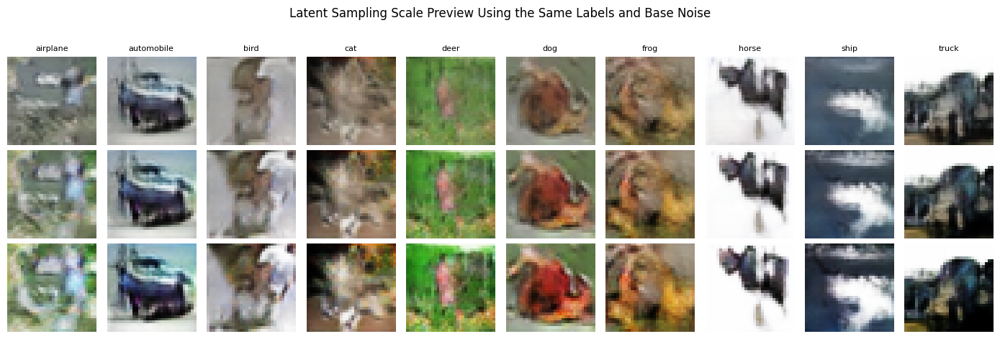

Latent scale preview saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\latent_scale_preview_comparison.png


In [39]:
# Step 9.3: Controlled latent sampling-scale visual preview
LATENT_SCALE_DIR = OUTPUT_DIR / "latent_scale_tuning"
LATENT_SCALE_DIR.mkdir(parents=True, exist_ok=True)

LATENT_SCALE_VALUES = [0.70, 1.00, 1.30]
LATENT_SCALE_VISUAL_PATH = GRID_DIR / "latent_scale_preview_comparison.png"

visual_noise = tf.random.stateless_normal(
    shape=(NUM_CLASSES, LATENT_DIM),
    seed=[SEED, 9300]
)
visual_labels = tf.constant(np.arange(NUM_CLASSES), dtype=tf.int32)

visual_rows = []
for latent_scale in LATENT_SCALE_VALUES:
    generated = final_cdcgan_generator.predict(
        [visual_noise * latent_scale, visual_labels],
        verbose=0
    )
    visual_rows.append(gan_output_to_uint8(generated))

fig, axes = plt.subplots(
    len(LATENT_SCALE_VALUES),
    NUM_CLASSES,
    figsize=(14, 4.6)
)

for row_index, latent_scale in enumerate(LATENT_SCALE_VALUES):
    for class_id, class_name in enumerate(CLASS_NAMES):
        ax = axes[row_index, class_id]
        ax.imshow(visual_rows[row_index][class_id])
        ax.axis("off")
        if row_index == 0:
            ax.set_title(class_name, fontsize=8)
        if class_id == 0:
            ax.set_ylabel(f"z scale {latent_scale:.2f}", fontsize=9)

plt.suptitle("Latent Sampling Scale Preview Using the Same Labels and Base Noise", y=1.02)
plt.tight_layout()
fig.savefig(LATENT_SCALE_VISUAL_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Latent scale preview saved as:", LATENT_SCALE_VISUAL_PATH)


### 9.3.1 Latent Scale Proxy Comparison

The visual preview shows how the same class labels change when the latent scale changes, but I also need a small quantitative check.

I reuse the same proxy idea from the candidate-selection section: edge strength, contrast, colour variation and brightness penalty. This keeps the evaluation consistent with the later workflow.

The important limitation is that this proxy measures low-level image strength, not whether the generated object is truly recognisable. So the proxy can suggest a direction, but it should not automatically replace manual scoring or FID.

In [40]:
# Step 9.3.1: Generate latent-scale samples and calculate proxy metrics
LATENT_SCALE_IMAGES_PER_CLASS = 10


def latent_scale_tag(latent_scale):
    return f"scale_{latent_scale:.2f}".replace(".", "_")


def latent_scale_quality_features(image):
    features = image_quality_features_from_array(image)
    if "colour_variation" in features and "color_variation" not in features:
        features["color_variation"] = features.pop("colour_variation")
    return features


latent_scale_feature_records = []

for latent_scale in LATENT_SCALE_VALUES:
    scale_tag = latent_scale_tag(latent_scale)
    scale_dir = LATENT_SCALE_DIR / scale_tag
    scale_dir.mkdir(parents=True, exist_ok=True)

    scale_images = []
    scale_labels = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        class_dir = scale_dir / f"{class_id:02d}_{class_name}"
        class_dir.mkdir(parents=True, exist_ok=True)

        base_noise = tf.random.stateless_normal(
            shape=(LATENT_SCALE_IMAGES_PER_CLASS, LATENT_DIM),
            seed=[SEED, 9400 + class_id]
        )
        labels = tf.fill(
            [LATENT_SCALE_IMAGES_PER_CLASS],
            tf.constant(class_id, dtype=tf.int32)
        )

        generated = final_cdcgan_generator.predict(
            [base_noise * latent_scale, labels],
            verbose=0
        )
        generated_uint8 = gan_output_to_uint8(generated)

        for image_number, image in enumerate(generated_uint8, start=1):
            image_path = class_dir / f"latent_{scale_tag}_{class_name}_{image_number:04d}.png"
            Image.fromarray(image).save(image_path)
            scale_images.append(image)
            scale_labels.append(class_name)

            latent_scale_feature_records.append({
                "latent_scale": latent_scale,
                "scale_tag": scale_tag,
                "class_id": class_id,
                "class_name": class_name,
                "image_file": image_path.name,
                **latent_scale_quality_features(image),
            })

    scale_grid_path = LATENT_SCALE_DIR / f"{scale_tag}_preview_100.png"
    save_image_grid(np.array(scale_images), scale_grid_path, columns=10)
    print(f"Saved latent scale {latent_scale:.2f} preview grid:", scale_grid_path)

latent_scale_features = pd.DataFrame(latent_scale_feature_records)

latent_scale_proxy_summary = (
    latent_scale_features
    .groupby(["latent_scale", "scale_tag"])
    .agg(
        image_count=("image_file", "count"),
        mean_contrast=("contrast", "mean"),
        mean_color_variation=("color_variation", "mean"),
        mean_edge_strength=("edge_strength", "mean"),
        mean_brightness_penalty=("brightness_penalty", "mean"),
    )
    .reset_index()
)

for metric in [
    "mean_contrast",
    "mean_color_variation",
    "mean_edge_strength",
    "mean_brightness_penalty",
]:
    value_range = latent_scale_proxy_summary[metric].max() - latent_scale_proxy_summary[metric].min()
    if value_range == 0:
        latent_scale_proxy_summary[f"{metric}_norm"] = 0.0
    else:
        latent_scale_proxy_summary[f"{metric}_norm"] = (
            latent_scale_proxy_summary[metric] - latent_scale_proxy_summary[metric].min()
        ) / value_range

latent_scale_proxy_summary["quality_proxy_score"] = (
    0.40 * latent_scale_proxy_summary["mean_edge_strength_norm"]
    + 0.30 * latent_scale_proxy_summary["mean_contrast_norm"]
    + 0.20 * latent_scale_proxy_summary["mean_color_variation_norm"]
    - 0.10 * latent_scale_proxy_summary["mean_brightness_penalty_norm"]
)

latent_scale_proxy_summary = (
    latent_scale_proxy_summary
    .sort_values("quality_proxy_score", ascending=False)
    .reset_index(drop=True)
)

latent_scale_features_path = TABLE_DIR / "latent_scale_tuning_quality_features.csv"
latent_scale_proxy_path = TABLE_DIR / "latent_scale_tuning_proxy_comparison.csv"

latent_scale_features.to_csv(latent_scale_features_path, index=False)
latent_scale_proxy_summary.to_csv(latent_scale_proxy_path, index=False)

display(latent_scale_proxy_summary)

print("Latent scale quality features saved as:", latent_scale_features_path)
print("Latent scale proxy comparison saved as:", latent_scale_proxy_path)


Saved latent scale 0.70 preview grid: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\latent_scale_tuning\scale_0_70_preview_100.png


Saved latent scale 1.00 preview grid: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\latent_scale_tuning\scale_1_00_preview_100.png


Saved latent scale 1.30 preview grid: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\latent_scale_tuning\scale_1_30_preview_100.png


,latent_scale,scale_tag,image_count,mean_contrast,mean_color_variation,mean_edge_strength,mean_brightness_penalty,mean_contrast_norm,mean_color_variation_norm,mean_edge_strength_norm,mean_brightness_penalty_norm,quality_proxy_score
0,1.3,scale_1_30,100,54.457321,57.130634,32.455536,0.229990,1.00000,1.000000,1.000000,1.000000,0.800000
1,1.0,scale_1_00,100,48.033119,49.772629,28.278698,0.198619,0.55224,0.544941,0.545895,0.526289,0.440389
2,0.7,scale_0_70,100,40.109901,40.961304,23.257580,0.163766,0.00000,0.000000,0.000000,0.000000,0.000000


Latent scale quality features saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\latent_scale_tuning_quality_features.csv
Latent scale proxy comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\latent_scale_tuning_proxy_comparison.csv


### 9.3.2 Latent Scale Experiment Decision

The proxy comparison shows that the larger latent scale produced the strongest low-level image-quality score. The default latent scale **1.00** had a proxy score of **0.440**, while scale **1.30** improved the proxy score to **0.800**.

This happened because increasing the latent scale can push the generator toward stronger variation, which can increase contrast, colour variation and edge strength. However, this is not automatically the same as better CIFAR10 recognisability.

Decision: do not replace the final images using scale **1.30** yet. It is a useful follow-up idea, but proxy metrics alone cannot prove that the generated object identity is clearer.


In [41]:
# Step 9.3.2: Decide whether the latent sampling scale should change
latent_scale_proxy_path = TABLE_DIR / "latent_scale_tuning_proxy_comparison.csv"

if not latent_scale_proxy_path.exists():
    raise FileNotFoundError(
        "Run the latent scale proxy comparison cell before creating the decision table."
    )

latent_scale_proxy_summary = pd.read_csv(latent_scale_proxy_path)
best_scale_row = latent_scale_proxy_summary.iloc[0]

default_scale_rows = latent_scale_proxy_summary[
    np.isclose(latent_scale_proxy_summary["latent_scale"], 1.00)
]
if default_scale_rows.empty:
    raise ValueError("Default latent scale 1.00 is missing from the comparison.")

default_scale_row = default_scale_rows.iloc[0]

best_scale = float(best_scale_row["latent_scale"])
default_score = float(default_scale_row["quality_proxy_score"])
best_score = float(best_scale_row["quality_proxy_score"])
proxy_score_change = best_score - default_score

if np.isclose(best_scale, 1.00):
    latent_scale_decision_text = "keep default latent scale 1.00"
    latent_scale_reason = "the unchanged latent scale has the strongest proxy score"
else:
    latent_scale_decision_text = "do not replace final images yet"
    latent_scale_reason = (
        f"latent scale {best_scale:.2f} has the strongest proxy score, "
        "but this needs manual or FID confirmation before replacing the final submission set"
    )

latent_scale_decision = pd.DataFrame([{
    "experiment": "Latent sampling scale tuning",
    "controlled_factor": "latent vector scale at generation time",
    "values_tested": ", ".join(f"{value:.2f}" for value in LATENT_SCALE_VALUES),
    "constant_conditions": "same trained final cDCGAN weights, same CIFAR10 labels, same base noise seeds",
    "default_scale": 1.00,
    "best_scale_by_proxy": best_scale,
    "default_proxy_score": default_score,
    "best_proxy_score": best_score,
    "proxy_score_change_vs_default": proxy_score_change,
    "decision": latent_scale_decision_text,
    "reason": latent_scale_reason,
    "limitation": "proxy metrics do not prove class recognisability and do not replace manual scoring",
}])

latent_scale_decision_path = TABLE_DIR / "latent_scale_tuning_decision.csv"
latent_scale_decision.to_csv(latent_scale_decision_path, index=False)

display(latent_scale_decision)

print("Latent scale decision saved as:", latent_scale_decision_path)


,experiment,controlled_factor,values_tested,constant_conditions,default_scale,best_scale_by_proxy,default_proxy_score,best_proxy_score,proxy_score_change_vs_default,decision,reason,limitation
0,Latent sampling scale tuning,latent vector scale at generation time,"0.70, 1.00, 1.30","same trained final cDCGAN weights, same CIFAR1...",1.0,1.3,0.440389,0.8,0.359611,do not replace final images yet,latent scale 1.30 has the strongest proxy scor...,proxy metrics do not prove class recognisabili...


Latent scale decision saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\latent_scale_tuning_decision.csv


### 9.3.3 Latent Scale Experiment Outcome

This experiment is useful because it closes another possible improvement idea before moving to candidate selection.

The latent-scale test is a **generation diagnostic**, not a retraining experiment. The model weights stay unchanged; only the scale of the random latent vector is adjusted when generating images.

The result suggests that sampling further from the centre of the latent space can make generated images stronger in low-level visual features. Scale **1.30** increased contrast, colour variation and edge strength compared with the default scale.

At the same time, the result is not strong enough to change the final submission folder by itself. A sharper or more textured image is not always a more recognisable CIFAR10 object. A better value on one proxy metric is therefore insufficient evidence to modify the final generation pipeline without consistent support from manual scoring or FID.

Decision: keep the default final cDCGAN output path and candidate-pool workflow as the main final route, while recording scale **1.30** as a possible future sampling improvement.


## 10. Post-Generation Quality Control: Candidate Pool

The candidate-pool step is a **post-generation quality-control workaround**, not a model-training improvement.

| Question | Explanation |
|----------|-------------|
| What problem did I see? | many generated images are marginal or nonsense, especially for organic classes |
| Why does this happen? | the generator output depends on random latent vectors, and some vectors produce clearer images than others |
| How do I plan to fix it? | generate more candidates than needed, then keep the best 100 per class |
| What does this improve? | final image selection quality, not the model weights |
| How will I know it helped? | the selected set should have fewer nonsense images than the first 100-per-class set |
| What if it still fails? | then the limitation is model capacity/training quality, not only sample selection |

The model weights are unchanged in this section. Therefore, any increase in usable rate is reported as **candidate selection / quality control**, not as proof that the trained generator itself became better.

Decision: use this section to improve the final submitted image folder, while keeping the model-improvement claims limited to the actual training and architecture changes.


### 10.1 Generate Extra Candidate Images

This step generates an extra candidate pool from the saved final cDCGAN generator.

The model still generates the images. The difference is that more than **100 images per class** are generated so weak samples can be reviewed and replaced if needed.

In [42]:
# Step 10.1: Generate extra candidate images for quality control
CANDIDATES_PER_CLASS = 200
CANDIDATE_DIR = OUTPUT_DIR / "candidate_pool_for_selection"
CANDIDATE_REVIEW_DIR = OUTPUT_DIR / "candidate_pool_review"

for folder in [CANDIDATE_DIR, CANDIDATE_REVIEW_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

candidate_records = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_candidate_dir = CANDIDATE_DIR / f"{class_id:02d}_{class_name}"
    class_candidate_dir.mkdir(parents=True, exist_ok=True)

    candidate_noise = tf.random.normal(
        shape=(CANDIDATES_PER_CLASS, LATENT_DIM),
        seed=SEED + 1000 + class_id
    )
    candidate_labels = tf.fill([CANDIDATES_PER_CLASS], class_id)

    candidate_images = final_cdcgan_generator.predict(
        [candidate_noise, candidate_labels],
        verbose=0
    )
    candidate_uint8 = gan_output_to_uint8(candidate_images)

    saved_candidate_paths = save_individual_images(
        candidate_uint8,
        class_candidate_dir,
        prefix="candidate_cdcgan",
        class_name=class_name
    )

    candidate_review_grid_path = CANDIDATE_REVIEW_DIR / f"{class_id:02d}_{class_name}_candidate_grid.png"
    save_image_grid(
        candidate_uint8[:100],
        candidate_review_grid_path,
        columns=10
    )

    candidate_records.append({
        "class_id": class_id,
        "class_name": class_name,
        "candidates_saved": len(saved_candidate_paths),
        "candidate_folder": str(class_candidate_dir),
        "review_grid": str(candidate_review_grid_path),
    })

candidate_summary = pd.DataFrame(candidate_records)
candidate_summary_path = TABLE_DIR / "candidate_pool_summary.csv"
candidate_summary.to_csv(candidate_summary_path, index=False)

display(candidate_summary)

print("Candidate images saved:", candidate_summary["candidates_saved"].sum())
print("Candidate pool folder:", CANDIDATE_DIR)
print("Candidate review folder:", CANDIDATE_REVIEW_DIR)
print("Candidate summary saved as:", candidate_summary_path)


,class_id,class_name,candidates_saved,candidate_folder,review_grid
0,0,airplane,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,1,automobile,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,2,bird,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,3,cat,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
4,4,deer,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
5,5,dog,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
6,6,frog,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
7,7,horse,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
8,8,ship,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...
9,9,truck,200,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...


Candidate images saved: 2000
Candidate pool folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\candidate_pool_for_selection
Candidate review folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\candidate_pool_review
Candidate summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\candidate_pool_summary.csv


### 10.1.1 Candidate Pool Checkpoint

The candidate pool gives more generated samples to choose from.

This helps because the cDCGAN does not produce the same quality for every random noise vector. Some generated samples have clearer object-like structure, while others are distorted. By generating extra candidates, there are more options before deciding which images should represent each class.

Decision: inspect the candidate grids before deciding whether to replace the original final set or simply report the limitation.

### 10.1.2 Candidate Pool Outcome

The candidate-pool generation ran successfully.

The output is:

| Item | Result |
|------|--------|
| candidates per class | 200 |
| CIFAR10 classes | 10 |
| total candidate images | 2000 |
| purpose | provide more options for selecting clearer final samples |

The candidate grids show that this workaround gives more options, but it does not automatically solve image quality. Classes such as **ship**, **truck** and **automobile** have more consistently usable-looking candidates. **Airplane** has some useful sky/background cues, but it is more mixed than those strongest classes. Organic classes such as **cat**, **dog**, **bird** and **frog** still contain many distorted samples.

Decision: continue with candidate selection, but treat it as a quality-control workaround rather than a true model improvement.


### 10.2 Candidate Selection Using a Quality Proxy

The next problem is choosing better samples from the candidate pool.

Manual selection is the most accurate method, but reviewing **2000 images** one by one is slow. As a practical workaround, I first rank candidates using simple image-quality signals.

| Signal | Why I use it |
|--------|--------------|
| edge strength | clearer objects usually have stronger boundaries |
| contrast | completely washed-out images are less useful |
| colour variation | CIFAR10 images usually contain meaningful colour differences |
| brightness penalty | very dark or very bright images are often low quality |

This proxy does not understand object class. It cannot prove that an image is a good cat, dog or ship. It only helps filter out weaker candidates before final review.


In [43]:
# Step 10.2: Rank candidates and select 100 per class using an image-quality proxy
import shutil

SELECTED_DIR = OUTPUT_DIR / "selected_1000_candidate_images"
SELECTED_REVIEW_DIR = OUTPUT_DIR / "selected_candidate_review"

for folder in [SELECTED_DIR, SELECTED_REVIEW_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


def image_quality_features(image_path):
    image = np.asarray(Image.open(image_path).convert("RGB")).astype("float32")
    gray = image.mean(axis=2)

    contrast = gray.std()
    color_variation = image.std(axis=(0, 1)).mean()

    grad_x = np.abs(np.diff(gray, axis=1)).mean()
    grad_y = np.abs(np.diff(gray, axis=0)).mean()
    edge_strength = grad_x + grad_y

    brightness = gray.mean()
    brightness_penalty = abs(brightness - 127.5) / 127.5

    return {
        "contrast": contrast,
        "color_variation": color_variation,
        "edge_strength": edge_strength,
        "brightness_penalty": brightness_penalty,
    }


def normalise_column(values):
    values = np.asarray(values, dtype="float32")
    value_range = values.max() - values.min()
    if value_range == 0:
        return np.zeros_like(values)
    return (values - values.min()) / value_range


selected_records = []
all_candidate_scores = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_candidate_dir = CANDIDATE_DIR / f"{class_id:02d}_{class_name}"
    class_selected_dir = SELECTED_DIR / f"{class_id:02d}_{class_name}"
    class_selected_dir.mkdir(parents=True, exist_ok=True)

    candidate_paths = sorted(class_candidate_dir.glob("*.png"))
    class_rows = []

    for candidate_path in candidate_paths:
        features = image_quality_features(candidate_path)
        class_rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "candidate_path": str(candidate_path),
            "candidate_file": candidate_path.name,
            **features,
        })

    class_scores = pd.DataFrame(class_rows)
    class_scores["contrast_norm"] = normalise_column(class_scores["contrast"])
    class_scores["color_norm"] = normalise_column(class_scores["color_variation"])
    class_scores["edge_norm"] = normalise_column(class_scores["edge_strength"])
    class_scores["brightness_penalty_norm"] = normalise_column(class_scores["brightness_penalty"])

    class_scores["quality_proxy_score"] = (
        0.40 * class_scores["edge_norm"]
        + 0.30 * class_scores["contrast_norm"]
        + 0.20 * class_scores["color_norm"]
        - 0.10 * class_scores["brightness_penalty_norm"]
    )

    class_scores = class_scores.sort_values("quality_proxy_score", ascending=False).reset_index(drop=True)
    class_scores["rank"] = np.arange(1, len(class_scores) + 1)
    all_candidate_scores.append(class_scores)

    selected_class_scores = class_scores.head(FINAL_IMAGES_PER_CLASS).copy()

    selected_images = []
    for selected_index, row in enumerate(selected_class_scores.itertuples(index=False), start=1):
        source_path = Path(row.candidate_path)
        destination_path = class_selected_dir / f"selected_cdcgan_{class_name}_{selected_index:04d}.png"
        shutil.copy2(source_path, destination_path)
        selected_images.append(np.asarray(Image.open(destination_path).convert("RGB")))

        selected_records.append({
            "class_id": class_id,
            "class_name": class_name,
            "selected_rank": selected_index,
            "source_candidate": source_path.name,
            "selected_file": destination_path.name,
            "quality_proxy_score": row.quality_proxy_score,
        })

    selected_review_grid_path = SELECTED_REVIEW_DIR / f"{class_id:02d}_{class_name}_selected_grid.png"
    save_image_grid(
        np.array(selected_images),
        selected_review_grid_path,
        columns=10
    )

candidate_score_table = pd.concat(all_candidate_scores, ignore_index=True)
selected_candidate_table = pd.DataFrame(selected_records)

candidate_score_path = TABLE_DIR / "candidate_quality_proxy_scores.csv"
selected_candidate_path = TABLE_DIR / "selected_candidate_images.csv"

candidate_score_table.to_csv(candidate_score_path, index=False)
selected_candidate_table.to_csv(selected_candidate_path, index=False)

selection_summary = selected_candidate_table.groupby("class_name").size().reset_index(name="selected_images")
display(selection_summary)

print("Selected images saved:", len(selected_candidate_table))
print("Selected candidate folder:", SELECTED_DIR)
print("Selected review grids:", SELECTED_REVIEW_DIR)
print("Candidate score table saved as:", candidate_score_path)
print("Selected candidate table saved as:", selected_candidate_path)


,class_name,selected_images
0,airplane,100
1,automobile,100
2,bird,100
3,cat,100
4,deer,100
5,dog,100
6,frog,100
7,horse,100
8,ship,100
9,truck,100


Selected images saved: 1000
Selected candidate folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\selected_1000_candidate_images
Selected review grids: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\selected_candidate_review
Candidate score table saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\candidate_quality_proxy_scores.csv
Selected candidate table saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_candidate_images.csv


### 10.2.1 Candidate Selection Checkpoint

The selection step creates a cleaner candidate-based image set.

This does not retrain the cDCGAN. It only uses a quality proxy to rank generated candidates and copy the top **100 images per class** into a separate selected folder.

This is a useful workaround because it targets the actual problem found after manual scoring: not every random latent vector produces a good sample. However, the proxy is still limited because it measures low-level image quality, not true class correctness.

Decision: review the selected grids next and compare them against the original final set before deciding whether candidate selection should be accepted as a quality-control workaround.


### 10.2.2 Candidate Selection Outcome

The candidate selection step ran successfully and created a selected set of **1000 images**.

The output is:

| Item | Result |
|------|--------|
| selected images per class | 100 |
| selected classes | 10 |
| total selected images | 1000 |
| selection method | image-quality proxy |
| retraining used | no |

The selected grids show that the proxy tends to choose images with stronger edges, contrast and texture. This can make some selected images look more detailed than the original generated set.

However, this improvement has an important limitation. The proxy does not understand whether an image is truly a cat, dog, frog, ship or truck. It can select visually active samples that still have unclear class identity.

Decision: compare the original final set and selected candidate set using proxy metrics, then decide whether the candidate-selection workaround should be accepted as useful but limited.


### 10.3 Original Set vs Selected Set Comparison

This comparison checks the original final set against the selected candidate set.

It does not replace manual visual judgement. It only checks whether the selected set improved on the same low-level image-quality signals used for selection.

| Comparison signal | What it can show | What it cannot prove |
|-------------------|------------------|----------------------|
| edge strength | whether selected images have stronger boundaries | whether the object class is correct |
| contrast | whether images are less washed out | whether the shape is meaningful |
| colour variation | whether images contain richer colour changes | whether the colours match the class |
| brightness penalty | whether images avoid extreme brightness | whether the image is recognisable |

This answers a careful evaluation question: did candidate selection improve the image-quality proxy, even if it does not fully solve recognisability?

In [44]:
# Step 10.3: Compare original final set and selected candidate set
ORIGINAL_SET_DIR = FINAL_IMAGE_DIR
SELECTED_DIR = OUTPUT_DIR / "selected_1000_candidate_images"

if "image_quality_features" not in globals():
    def image_quality_features(image_path):
        image = np.asarray(Image.open(image_path).convert("RGB")).astype("float32")
        gray = image.mean(axis=2)

        contrast = gray.std()
        color_variation = image.std(axis=(0, 1)).mean()

        grad_x = np.abs(np.diff(gray, axis=1)).mean()
        grad_y = np.abs(np.diff(gray, axis=0)).mean()
        edge_strength = grad_x + grad_y

        brightness = gray.mean()
        brightness_penalty = abs(brightness - 127.5) / 127.5

        return {
            "contrast": contrast,
            "color_variation": color_variation,
            "edge_strength": edge_strength,
            "brightness_penalty": brightness_penalty,
        }


def collect_quality_features(root_dir, set_name):
    records = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        class_dir = Path(root_dir) / f"{class_id:02d}_{class_name}"
        image_paths = sorted(class_dir.glob("*.png"))

        for image_path in image_paths:
            records.append({
                "image_set": set_name,
                "class_id": class_id,
                "class_name": class_name,
                "image_file": image_path.name,
                **image_quality_features(image_path),
            })

    return pd.DataFrame(records)


original_quality_features = collect_quality_features(ORIGINAL_SET_DIR, "original_final_set")
selected_quality_features = collect_quality_features(SELECTED_DIR, "selected_candidate_set")

quality_features = pd.concat(
    [original_quality_features, selected_quality_features],
    ignore_index=True
)

overall_proxy_comparison = (
    quality_features
    .groupby("image_set")
    .agg(
        image_count=("image_file", "count"),
        mean_contrast=("contrast", "mean"),
        mean_color_variation=("color_variation", "mean"),
        mean_edge_strength=("edge_strength", "mean"),
        mean_brightness_penalty=("brightness_penalty", "mean"),
    )
    .reset_index()
)

class_proxy_comparison = (
    quality_features
    .groupby(["class_name", "image_set"])
    .agg(
        image_count=("image_file", "count"),
        mean_contrast=("contrast", "mean"),
        mean_color_variation=("color_variation", "mean"),
        mean_edge_strength=("edge_strength", "mean"),
        mean_brightness_penalty=("brightness_penalty", "mean"),
    )
    .reset_index()
)

edge_pivot = class_proxy_comparison.pivot(
    index="class_name",
    columns="image_set",
    values="mean_edge_strength"
).reset_index()
edge_pivot["edge_strength_change"] = (
    edge_pivot["selected_candidate_set"] - edge_pivot["original_final_set"]
)

display(overall_proxy_comparison)
display(edge_pivot)

quality_features_path = TABLE_DIR / "original_vs_selected_quality_features.csv"
overall_proxy_path = TABLE_DIR / "original_vs_selected_overall_proxy_comparison.csv"
class_proxy_path = TABLE_DIR / "original_vs_selected_class_proxy_comparison.csv"

quality_features.to_csv(quality_features_path, index=False)
overall_proxy_comparison.to_csv(overall_proxy_path, index=False)
class_proxy_comparison.to_csv(class_proxy_path, index=False)

print("Quality feature table saved as:", quality_features_path)
print("Overall proxy comparison saved as:", overall_proxy_path)
print("Class proxy comparison saved as:", class_proxy_path)


,image_set,image_count,mean_contrast,mean_color_variation,mean_edge_strength,mean_brightness_penalty
0,original_final_set,1000,48.503532,49.916878,28.288204,0.202840
1,selected_candidate_set,1000,57.119976,58.237751,32.371384,0.177877


image_set,class_name,original_final_set,selected_candidate_set,edge_strength_change
0,airplane,25.414217,30.110563,4.696346
1,automobile,34.116669,37.030018,2.913349
2,bird,24.031937,27.416328,3.384392
3,cat,28.093504,32.048538,3.955034
4,deer,24.098347,28.446428,4.348082
5,dog,26.996521,31.867283,4.870762
6,frog,29.643055,33.106846,3.463791
7,horse,31.715063,35.636486,3.921423
8,ship,24.676348,30.239740,5.563393
9,truck,34.096394,37.811623,3.715229


Quality feature table saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\original_vs_selected_quality_features.csv
Overall proxy comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\original_vs_selected_overall_proxy_comparison.csv
Class proxy comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\original_vs_selected_class_proxy_comparison.csv


### 10.3.1 Proxy Comparison Checkpoint

The proxy comparison checks whether the selected candidate set improved low-level visual signals compared with the original final set.

If the selected set has higher average edge strength, contrast or colour variation, then the quality-control workaround improved the proxy score. However, this still does not prove that every selected image is semantically correct.

Decision: use the proxy comparison as supporting evidence only. The final judgement still needs to mention visual limitations and class ambiguity, especially for organic classes.


### 10.3.2 Proxy Comparison Outcome

The proxy comparison shows that the selected candidate set improved the low-level image-quality signals.

| Proxy metric | Original final set | Selected candidate set | Interpretation |
|--------------|--------------------|------------------------|----------------|
| mean contrast | 48.50 | 57.12 | selected images are less flat or washed out |
| mean colour variation | 49.92 | 58.24 | selected images contain richer colour changes |
| mean edge strength | 28.29 | 32.37 | selected images have stronger boundaries and texture |
| mean brightness penalty | 0.203 | 0.178 | selected images are less extremely dark or bright |

The edge-strength improvement appears in every CIFAR10 class. This means the selected set is visually stronger according to the proxy.

However, this does not fully prove that candidate selection fixed image recognisability. The proxy can reward busy or high-contrast images even when the actual object is still unclear. Therefore, this result is supporting evidence, not final proof.

Decision: candidate selection is useful as a quality-control workaround, but the final judgement still needs visual comparison and limitation discussion.


### 10.4 Visual Comparison of Original and Selected Outputs

This step creates a compact visual comparison between the original final set and the selected candidate set.

The proxy scores improved, but visual inspection is still needed to check whether the selected samples actually look more useful.

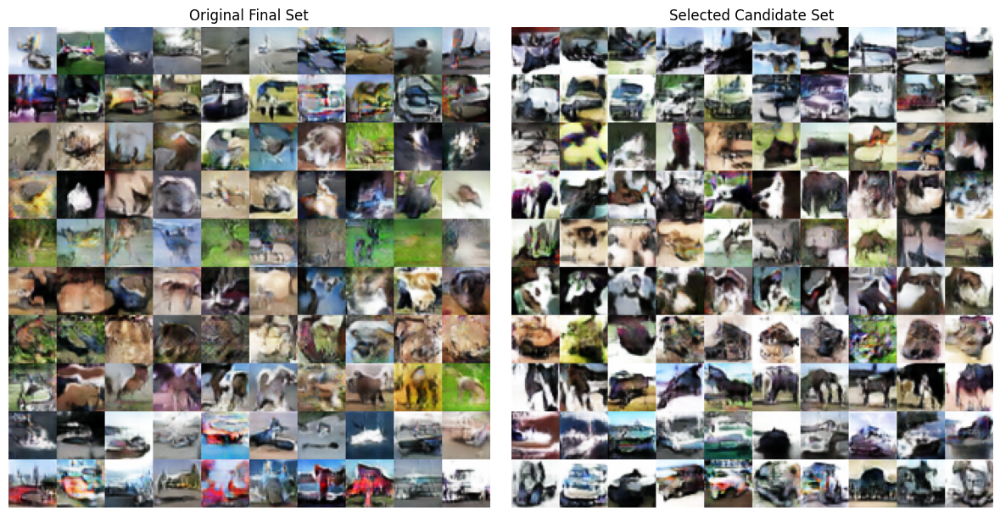

Original preview grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\original_final_preview_for_selection_comparison.png
Selected preview grid saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\selected_candidate_preview_100.png
Original vs selected comparison saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\original_vs_selected_preview_comparison.png


In [45]:
# Step 10.4: Create original vs selected visual comparison grids
SELECTED_DIR = OUTPUT_DIR / "selected_1000_candidate_images"

original_preview_images = []
selected_preview_images = []
preview_labels = []

for class_id, class_name in enumerate(CLASS_NAMES):
    original_class_dir = FINAL_IMAGE_DIR / f"{class_id:02d}_{class_name}"
    selected_class_dir = SELECTED_DIR / f"{class_id:02d}_{class_name}"

    original_paths = sorted(original_class_dir.glob("*.png"))[:10]
    selected_paths = sorted(selected_class_dir.glob("*.png"))[:10]

    for original_path, selected_path in zip(original_paths, selected_paths):
        original_preview_images.append(np.asarray(Image.open(original_path).convert("RGB")))
        selected_preview_images.append(np.asarray(Image.open(selected_path).convert("RGB")))
        preview_labels.append(class_name)

original_preview_images = np.array(original_preview_images)
selected_preview_images = np.array(selected_preview_images)

original_preview_grid_path = GRID_DIR / "original_final_preview_for_selection_comparison.png"
selected_preview_grid_path = GRID_DIR / "selected_candidate_preview_100.png"

save_image_grid(original_preview_images, original_preview_grid_path, columns=10)
save_image_grid(selected_preview_images, selected_preview_grid_path, columns=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(Image.open(original_preview_grid_path))
axes[0].set_title("Original Final Set")
axes[0].axis("off")

axes[1].imshow(Image.open(selected_preview_grid_path))
axes[1].set_title("Selected Candidate Set")
axes[1].axis("off")

plt.tight_layout()

visual_comparison_path = GRID_DIR / "original_vs_selected_preview_comparison.png"
fig.savefig(visual_comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("Original preview grid saved as:", original_preview_grid_path)
print("Selected preview grid saved as:", selected_preview_grid_path)
print("Original vs selected comparison saved as:", visual_comparison_path)


### 10.4.1 Visual Comparison Checkpoint

The visual comparison checks whether the selected candidate set looks better, not only whether its proxy scores are higher.

If the selected images look more detailed but still class-ambiguous, then the candidate-pool step should be described as a **limited workaround**. It improves sample selection quality but does not fully solve the generative model's weakness.

Decision: inspect the comparison grid before deciding whether the selected candidate folder should be used as the final generated-image set.


### 10.4.2 Visual Comparison Outcome

The visual comparison shows that candidate-pool quality control is a **partial success**.

The selected candidate set generally looks more detailed and higher contrast than the original final set. This matches the proxy results, where the selected set had stronger edge strength, contrast and colour variation.

However, the selected set does not fully solve recognisability. Some selected images are visually busy but still class-ambiguous. This happens because the quality proxy rewards low-level image signals, not true object understanding.

| Question | Answer |
|----------|--------|
| Did the selected set improve low-level visual quality? | Yes, proxy metrics and visual comparison both suggest stronger detail |
| Did it fully fix class recognisability? | No, some images are still unclear or distorted |
| Why did the problem remain? | the proxy does not know whether an image is semantically correct for the class |
| Should I claim this as a full model improvement? | No, it should be reported as a limited quality-control workaround |

Decision: keep candidate-pool quality control as supporting evidence. It improves sample selection quality, but the final conclusion must still mention that object structure and class clarity remain limited.


### 10.5 Selected Candidate Manual Quality Scoring

Since the selected candidate folder is used as the final submission image set, it also needs a manual **Clear / Marginal / Nonsense** score.

The proxy metrics showed stronger low-level quality, but proxy values are not the same as manual recognisability. This scoring step checks the actual selected review grids so the submitted image set is evaluated using the same method as the original final cDCGAN set.

In [46]:
# Step 10.5: Score selected candidate submission set using aggregate manual counts
selected_manual_quality_count_entries = pd.DataFrame([
    {"class_name": "airplane", "clear_count": 34, "marginal_count": 51, "nonsense_count": 15},
    {"class_name": "automobile", "clear_count": 43, "marginal_count": 45, "nonsense_count": 12},
    {"class_name": "bird", "clear_count": 22, "marginal_count": 54, "nonsense_count": 24},
    {"class_name": "cat", "clear_count": 21, "marginal_count": 49, "nonsense_count": 30},
    {"class_name": "deer", "clear_count": 29, "marginal_count": 52, "nonsense_count": 19},
    {"class_name": "dog", "clear_count": 25, "marginal_count": 51, "nonsense_count": 24},
    {"class_name": "frog", "clear_count": 18, "marginal_count": 53, "nonsense_count": 29},
    {"class_name": "horse", "clear_count": 43, "marginal_count": 48, "nonsense_count": 9},
    {"class_name": "ship", "clear_count": 46, "marginal_count": 45, "nonsense_count": 9},
    {"class_name": "truck", "clear_count": 42, "marginal_count": 45, "nonsense_count": 13},
])

if "summarise_manual_count_entries" not in globals() or "create_balanced_review_template" not in globals():
    raise RuntimeError(
        "Run Section 8.4.1 first so the aggregate manual scoring helpers are available."
    )

selected_manual_quality_count_summary_path = TABLE_DIR / "selected_manual_quality_count_summary.csv"
selected_manual_quality_count_entries.to_csv(
    selected_manual_quality_count_summary_path,
    index=False
)

selected_manual_quality_per_file_template_path = (
    TABLE_DIR / "selected_manual_quality_per_file_review_template.csv"
)
selected_manual_quality_per_file_template = create_balanced_review_template(
    OUTPUT_DIR / "selected_1000_candidate_images",
    selected_manual_quality_per_file_template_path,
    "selected_candidate_submission_set",
    images_per_class=20,
    seed=SEED + 8500,
)

selected_manual_quality_scores = summarise_manual_count_entries(
    selected_manual_quality_count_entries
)

selected_score_order = [
    "class_name",
    "clear_count",
    "marginal_count",
    "nonsense_count",
    "usable_count",
    "clear_rate",
    "usable_rate",
]

selected_manual_quality_scores_path = TABLE_DIR / "selected_manual_quality_scores.csv"
selected_manual_quality_scores.to_csv(selected_manual_quality_scores_path, index=False)

selected_manual_quality_summary = pd.DataFrame({
    "metric": [
        "selected images reviewed",
        "selected clear images",
        "selected marginal images",
        "selected nonsense images",
        "selected usable images",
        "selected clear rate",
        "selected usable rate",
    ],
    "value": [
        int(selected_manual_quality_scores["total_checked"].sum()),
        int(selected_manual_quality_scores["clear_count"].sum()),
        int(selected_manual_quality_scores["marginal_count"].sum()),
        int(selected_manual_quality_scores["nonsense_count"].sum()),
        int(selected_manual_quality_scores["usable_count"].sum()),
        selected_manual_quality_scores["clear_count"].sum()
        / selected_manual_quality_scores["total_checked"].sum(),
        selected_manual_quality_scores["usable_count"].sum()
        / selected_manual_quality_scores["total_checked"].sum(),
    ],
})

selected_manual_quality_summary_path = TABLE_DIR / "selected_manual_quality_summary.csv"
selected_manual_quality_summary.to_csv(selected_manual_quality_summary_path, index=False)

display(selected_manual_quality_scores[selected_score_order])
display(selected_manual_quality_summary)
display(selected_manual_quality_per_file_template.head(12))

print("Selected manual aggregate count summary saved as:", selected_manual_quality_count_summary_path)
print("Selected manual per-file review template saved as:", selected_manual_quality_per_file_template_path)
print("Selected manual quality scores saved as:", selected_manual_quality_scores_path)
print("Selected manual quality summary saved as:", selected_manual_quality_summary_path)


,class_name,clear_count,marginal_count,nonsense_count,usable_count,clear_rate,usable_rate
0,airplane,34,51,15,85,0.34,0.85
1,automobile,43,45,12,88,0.43,0.88
2,bird,22,54,24,76,0.22,0.76
3,cat,21,49,30,70,0.21,0.70
4,deer,29,52,19,81,0.29,0.81
5,dog,25,51,24,76,0.25,0.76
6,frog,18,53,29,71,0.18,0.71
7,horse,43,48,9,91,0.43,0.91
8,ship,46,45,9,91,0.46,0.91
9,truck,42,45,13,87,0.42,0.87


,metric,value
0,selected images reviewed,1000.000
1,selected clear images,323.000
2,selected marginal images,493.000
3,selected nonsense images,184.000
4,selected usable images,816.000
5,selected clear rate,0.323
6,selected usable rate,0.816


,image_set,class_id,class_name,review_number,image_file,image_path,rating_instruction,rating,rating_source,rating_criteria
0,selected_candidate_submission_set,0,airplane,1,selected_cdcgan_airplane_0004.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
1,selected_candidate_submission_set,0,airplane,2,selected_cdcgan_airplane_0008.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
2,selected_candidate_submission_set,0,airplane,3,selected_cdcgan_airplane_0022.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
3,selected_candidate_submission_set,0,airplane,4,selected_cdcgan_airplane_0028.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
4,selected_candidate_submission_set,0,airplane,5,selected_cdcgan_airplane_0034.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
5,selected_candidate_submission_set,0,airplane,6,selected_cdcgan_airplane_0035.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
6,selected_candidate_submission_set,0,airplane,7,selected_cdcgan_airplane_0036.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Nonsense,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
7,selected_candidate_submission_set,0,airplane,8,selected_cdcgan_airplane_0046.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Marginal,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
8,selected_candidate_submission_set,0,airplane,9,selected_cdcgan_airplane_0049.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Nonsense,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...
9,selected_candidate_submission_set,0,airplane,10,selected_cdcgan_airplane_0052.png,C:\Users\USER\OneDrive - Singapore Polytechnic...,"Enter Clear, Marginal or Nonsense after visual...",Clear,visual review of fixed 20-per-class contact sheet,Clear=recognisable target class; Marginal=usef...


Selected manual aggregate count summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_manual_quality_count_summary.csv
Selected manual per-file review template saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_manual_quality_per_file_review_template.csv
Selected manual quality scores saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_manual_quality_scores.csv
Selected manual quality summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_manual_quality_summary.csv


In [47]:
# Step 10.5.1a: Summarise filled selected-set per-file manual review sample
selected_per_file_review_summary, selected_per_file_review_overall = summarise_filled_per_file_review(
    selected_manual_quality_per_file_template_path,
    TABLE_DIR / "selected_manual_quality_per_file_review_summary.csv",
    TABLE_DIR / "selected_manual_quality_per_file_review_overall.csv",
)

if selected_per_file_review_summary is not None:
    display(selected_per_file_review_summary)
    display(selected_per_file_review_overall)
    print("Selected per-file manual review summary saved as:", TABLE_DIR / "selected_manual_quality_per_file_review_summary.csv")
    print("Selected per-file manual review overall saved as:", TABLE_DIR / "selected_manual_quality_per_file_review_overall.csv")


rating,image_set,class_id,class_name,clear_count,marginal_count,nonsense_count,total_checked,usable_count,clear_rate,usable_rate
0,selected_candidate_submission_set,0,airplane,8,9,3,20,17,0.40,0.85
1,selected_candidate_submission_set,1,automobile,9,9,2,20,18,0.45,0.90
2,selected_candidate_submission_set,2,bird,4,11,5,20,15,0.20,0.75
3,selected_candidate_submission_set,3,cat,5,9,6,20,14,0.25,0.70
4,selected_candidate_submission_set,4,deer,6,10,4,20,16,0.30,0.80
5,selected_candidate_submission_set,5,dog,5,10,5,20,15,0.25,0.75
6,selected_candidate_submission_set,6,frog,4,10,6,20,14,0.20,0.70
7,selected_candidate_submission_set,7,horse,10,8,2,20,18,0.50,0.90
8,selected_candidate_submission_set,8,ship,10,8,2,20,18,0.50,0.90
9,selected_candidate_submission_set,9,truck,8,9,3,20,17,0.40,0.85


,image_set,images_reviewed,clear_count,marginal_count,nonsense_count,usable_count,clear_rate,usable_rate,review_method
0,selected_candidate_submission_set,200,69,93,38,162,0.345,0.81,fixed balanced 20 images per class with filena...


Selected per-file manual review summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_manual_quality_per_file_review_summary.csv
Selected per-file manual review overall saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\selected_manual_quality_per_file_review_overall.csv


### 10.5.1a Selected Per-File Manual Audit Checkpoint

The selected candidate folder also has a filled per-file audit using the same fixed **20 images per class** structure.

The selected sample has **69 clear**, **93 marginal** and **38 nonsense** images, giving a usable rate of **81.0%**. This is close to the full selected-set aggregate usable rate of **81.6%**.

This strengthens the candidate-selection conclusion because the selected folder is better not only in the aggregate manual table, but also in a genuinely auditable filename-level sample.


### 10.5.1 Selected Candidate Manual Score Interpretation

The selected candidate set is scored using the same aggregate manual-count method as the original final set.

The selected set has **323 clear**, **493 marginal** and **184 nonsense** images, giving a usable rate of **81.6%**. Compared with the original final set, the selected folder increases the clear count from **221** to **323** and reduces the nonsense count from **319** to **184**.

This is a meaningful output-set improvement, but it is not a model-weight improvement. The generator did not become better; I selected stronger samples from a larger candidate pool. The increase from **68.1%** to **81.6%** therefore refers to post-generation QC improving the selected submission folder, not to the trained GAN weights becoming better.

The filled per-file audit also supports this. In the fixed **200-image** selected sample, there are **69 clear**, **93 marginal** and **38 nonsense** images, giving a usable rate of **81.0%**. This is close to the full selected-set aggregate usable rate, so the selected-set evaluation is more auditable.

Decision: use the selected candidate folder as the final submission image set, while clearly reporting it as post-generation quality control.


### 10.5.2 FID Evaluation Rationale

At this point, I already have visual evidence and manual **Clear / Marginal / Nonsense** scoring. Those checks are still important because the final generated images need to be recognisable to a human viewer.

However, I also want one quantitative metric that compares the generated image distribution against real CIFAR10 images. This is why I add **Fréchet Inception Distance (FID)** as a supporting evaluation metric.

| Existing evidence | What it tells me | Limitation |
|-------------------|------------------|------------|
| image grids | whether the generated samples look CIFAR10-like | visual judgement can be subjective |
| manual scoring | whether images are clear, marginal or nonsense | depends on how consistently the scoring rule is applied |
| FID | whether generated images are close to real CIFAR10 images in feature space | does not directly prove class-label correctness |

For FID, I use the official CIFAR10 test images as the real reference set. These images are not used to train the generator, so they act as a cleaner comparison point for evaluation.

Expected outcome: if the selected candidate submission set is genuinely closer to real CIFAR10 images, it should have a lower FID than the original final cDCGAN set. If the selected set has better manual scoring but not better FID, then the improvement is mainly human-recognisability filtering rather than a full distribution-level improvement.

Decision: add FID as a supporting metric after manual scoring, then interpret it together with the visual and manual evidence instead of using it alone.


In [48]:
# Step 10.5.2: FID setup and helper functions
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input as inception_preprocess_input

FID_DIR = OUTPUT_DIR / "fid_evaluation"
FID_DIR.mkdir(parents=True, exist_ok=True)

FID_IMAGE_SIZE = (299, 299)
FID_BATCH_SIZE = 64
FID_EPSILON = 1e-6


def collect_png_paths(root_dir):
    root_dir = Path(root_dir)
    return sorted(root_dir.rglob("*.png"))


def balanced_cifar10_reference(images, labels, images_per_class):
    labels = np.asarray(labels).reshape(-1)
    selected_indices = []

    for class_id in range(NUM_CLASSES):
        class_indices = np.where(labels == class_id)[0][:images_per_class]
        if len(class_indices) < images_per_class:
            raise ValueError(
                f"Not enough CIFAR10 reference images for class {CLASS_NAMES[class_id]}."
            )
        selected_indices.extend(class_indices.tolist())

    return images[selected_indices]


def extract_inception_features_from_arrays(images, feature_model, batch_size=FID_BATCH_SIZE):
    feature_batches = []

    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size].astype("float32")
        batch = tf.image.resize(batch, FID_IMAGE_SIZE, method="bilinear").numpy()
        batch = inception_preprocess_input(batch)
        features = feature_model.predict(batch, verbose=0)
        feature_batches.append(features)

    return np.vstack(feature_batches)


def extract_inception_features_from_paths(image_paths, feature_model, batch_size=FID_BATCH_SIZE):
    feature_batches = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]
        batch_images = [
            np.asarray(Image.open(path).convert("RGB"), dtype="float32")
            for path in batch_paths
        ]

        batch = np.stack(batch_images, axis=0)
        batch = tf.image.resize(batch, FID_IMAGE_SIZE, method="bilinear").numpy()
        batch = inception_preprocess_input(batch)
        features = feature_model.predict(batch, verbose=0)
        feature_batches.append(features)

    return np.vstack(feature_batches)


def cache_path(cache_name):
    safe_name = cache_name.replace(" ", "_").replace("/", "_").lower()
    return FID_DIR / f"{safe_name}.npy"


def load_or_create_real_features(cache_name, images_per_class, feature_model):
    path = cache_path(cache_name)

    if path.exists():
        print("Loading cached real CIFAR10 features:", path.name)
        return np.load(path)

    reference_images = balanced_cifar10_reference(
        X_test_raw,
        y_test,
        images_per_class=images_per_class
    )
    features = extract_inception_features_from_arrays(reference_images, feature_model)
    np.save(path, features)
    return features


def load_or_create_generated_features(cache_name, image_paths, feature_model):
    path = cache_path(cache_name)

    if path.exists():
        print("Loading cached generated features:", path.name)
        return np.load(path)

    features = extract_inception_features_from_paths(image_paths, feature_model)
    np.save(path, features)
    return features


def matrix_sqrt(matrix):
    try:
        from scipy.linalg import sqrtm
        result = sqrtm(matrix)
    except Exception:
        result = tf.linalg.sqrtm(tf.cast(matrix, tf.float64)).numpy()

    if np.iscomplexobj(result):
        result = result.real

    return result


def calculate_fid(real_features, generated_features):
    real_features = real_features.astype("float64")
    generated_features = generated_features.astype("float64")

    real_mean = real_features.mean(axis=0)
    generated_mean = generated_features.mean(axis=0)

    real_cov = np.cov(real_features, rowvar=False)
    generated_cov = np.cov(generated_features, rowvar=False)

    real_cov += np.eye(real_cov.shape[0]) * FID_EPSILON
    generated_cov += np.eye(generated_cov.shape[0]) * FID_EPSILON

    mean_difference = real_mean - generated_mean
    covmean = matrix_sqrt(real_cov @ generated_cov)

    fid_value = (
        mean_difference @ mean_difference
        + np.trace(real_cov)
        + np.trace(generated_cov)
        - 2 * np.trace(covmean)
    )

    return float(max(fid_value, 0.0))


try:
    fid_feature_model = InceptionV3(
        include_top=False,
        weights="imagenet",
        pooling="avg",
        input_shape=(FID_IMAGE_SIZE[0], FID_IMAGE_SIZE[1], 3),
    )
except Exception as error:
    raise RuntimeError(
        "FID needs the pretrained InceptionV3 ImageNet weights. "
        "If this is the first run, allow Keras to download the weights once, then rerun this cell."
    ) from error

print("FID feature extractor ready:", fid_feature_model.name)
print("FID feature dimension:", fid_feature_model.output_shape[-1])
print("FID cache folder:", FID_DIR)


FID feature extractor ready: inception_v3
FID feature dimension: 2048
FID cache folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\fid_evaluation


In [49]:
# Step 10.5.3: Check generated image sources for FID
fid_image_sets = [
    {
        "image_set": "baseline_vae_100_samples",
        "folder": MANUAL_EVAL_DIR / "baseline_vae_100",
        "comparison_group": "100-image baseline check",
    },
    {
        "image_set": "baseline_dcgan_100_samples",
        "folder": MANUAL_EVAL_DIR / "baseline_dcgan_100",
        "comparison_group": "100-image baseline check",
    },
    {
        "image_set": "original_final_cdcgan_1000",
        "folder": FINAL_IMAGE_DIR,
        "comparison_group": "1000-image final-set check",
    },
    {
        "image_set": "selected_candidate_submission_1000",
        "folder": OUTPUT_DIR / "selected_1000_candidate_images",
        "comparison_group": "1000-image final-set check",
    },
]

fid_source_records = []

for image_set in fid_image_sets:
    image_paths = collect_png_paths(image_set["folder"])
    images_per_class = len(image_paths) // NUM_CLASSES

    fid_source_records.append({
        "image_set": image_set["image_set"],
        "comparison_group": image_set["comparison_group"],
        "generated_images_found": len(image_paths),
        "real_reference_images": images_per_class * NUM_CLASSES,
        "real_images_per_class": images_per_class,
        "folder_exists": Path(image_set["folder"]).exists(),
        "folder": str(image_set["folder"]),
    })

fid_source_check = pd.DataFrame(fid_source_records)
display(fid_source_check)

if not fid_source_check["folder_exists"].all():
    missing = fid_source_check.loc[~fid_source_check["folder_exists"], "folder"].tolist()
    raise FileNotFoundError(f"Missing FID image folders: {missing}")

if (fid_source_check["generated_images_found"] == 0).any():
    empty = fid_source_check.loc[
        fid_source_check["generated_images_found"] == 0,
        "image_set"
    ].tolist()
    raise ValueError(f"No PNG images found for FID sets: {empty}")

fid_source_check_path = TABLE_DIR / "fid_source_check.csv"
fid_source_check.to_csv(fid_source_check_path, index=False)

print("FID source check saved as:", fid_source_check_path)


,image_set,comparison_group,generated_images_found,real_reference_images,real_images_per_class,folder_exists,folder
0,baseline_vae_100_samples,100-image baseline check,100,100,10,True,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,baseline_dcgan_100_samples,100-image baseline check,100,100,10,True,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,original_final_cdcgan_1000,1000-image final-set check,1000,1000,100,True,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,selected_candidate_submission_1000,1000-image final-set check,1000,1000,100,True,C:\Users\USER\OneDrive - Singapore Polytechnic...


FID source check saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\fid_source_check.csv


In [50]:
# Step 10.5.4: Calculate FID scores against real CIFAR10 test images
fid_results = []

for image_set in fid_image_sets:
    image_paths = collect_png_paths(image_set["folder"])
    images_per_class = len(image_paths) // NUM_CLASSES
    real_image_count = images_per_class * NUM_CLASSES

    if real_image_count == 0:
        raise ValueError(f"Cannot calculate FID for {image_set['image_set']} because no images were found.")

    if len(image_paths) != real_image_count:
        image_paths = image_paths[:real_image_count]

    real_cache_name = f"real_cifar10_test_balanced_{real_image_count}"
    generated_cache_name = f"generated_{image_set['image_set']}_{len(image_paths)}"

    real_features = load_or_create_real_features(
        real_cache_name,
        images_per_class=images_per_class,
        feature_model=fid_feature_model
    )
    generated_features = load_or_create_generated_features(
        generated_cache_name,
        image_paths=image_paths,
        feature_model=fid_feature_model
    )

    fid_score = calculate_fid(real_features, generated_features)

    fid_results.append({
        "image_set": image_set["image_set"],
        "comparison_group": image_set["comparison_group"],
        "generated_images": len(image_paths),
        "real_reference_images": real_image_count,
        "fid_score": fid_score,
    })

fid_results_df = (
    pd.DataFrame(fid_results)
    .sort_values(["comparison_group", "fid_score"])
    .reset_index(drop=True)
)

fid_results_path = TABLE_DIR / "fid_results.csv"
fid_results_df.to_csv(fid_results_path, index=False)

display(fid_results_df)

print("FID results saved as:", fid_results_path)
print("Lower FID means the generated image distribution is closer to real CIFAR10 in Inception feature space.")


Loading cached real CIFAR10 features: real_cifar10_test_balanced_100.npy
Loading cached generated features: generated_baseline_vae_100_samples_100.npy


Loading cached real CIFAR10 features: real_cifar10_test_balanced_100.npy
Loading cached generated features: generated_baseline_dcgan_100_samples_100.npy


Loading cached real CIFAR10 features: real_cifar10_test_balanced_1000.npy
Loading cached generated features: generated_original_final_cdcgan_1000_1000.npy


Loading cached real CIFAR10 features: real_cifar10_test_balanced_1000.npy
Loading cached generated features: generated_selected_candidate_submission_1000_1000.npy


,image_set,comparison_group,generated_images,real_reference_images,fid_score
0,baseline_dcgan_100_samples,100-image baseline check,100,100,201.202254
1,baseline_vae_100_samples,100-image baseline check,100,100,272.166546
2,original_final_cdcgan_1000,1000-image final-set check,1000,1000,81.796607
3,selected_candidate_submission_1000,1000-image final-set check,1000,1000,83.010930


FID results saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\fid_results.csv
Lower FID means the generated image distribution is closer to real CIFAR10 in Inception feature space.


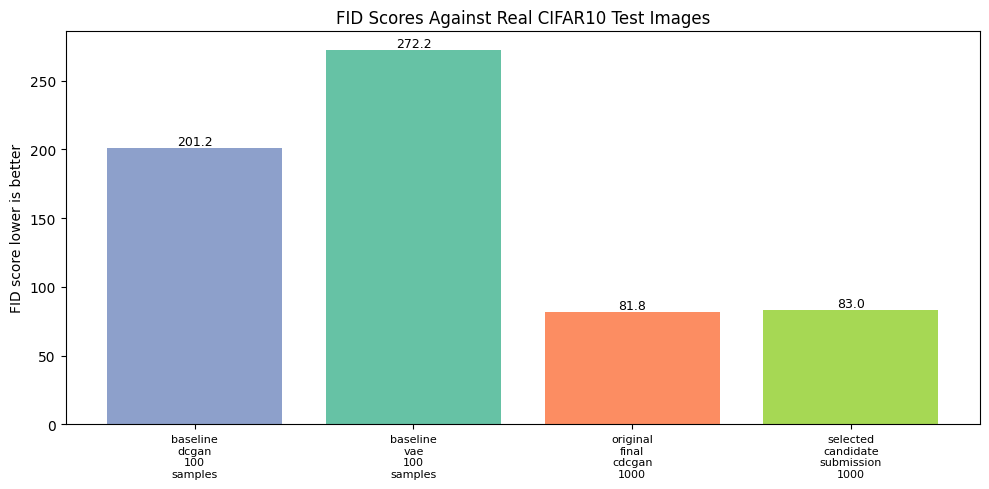

FID comparison plot saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\image_grids\fid_score_comparison.png


In [51]:
# Step 10.5.5: Visualise FID comparison
fid_plot_df = fid_results_df.copy()
fid_plot_df["plot_label"] = fid_plot_df["image_set"].str.replace("_", "\n")

plt.figure(figsize=(10, 5))
bars = plt.bar(
    fid_plot_df["plot_label"],
    fid_plot_df["fid_score"],
    color=["#8da0cb", "#66c2a5", "#fc8d62", "#a6d854"][:len(fid_plot_df)]
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.title("FID Scores Against Real CIFAR10 Test Images")
plt.ylabel("FID score lower is better")
plt.xticks(rotation=0, fontsize=8)
plt.tight_layout()

fid_plot_path = GRID_DIR / "fid_score_comparison.png"
plt.savefig(fid_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("FID comparison plot saved as:", fid_plot_path)


### 10.5.6 FID Results Interpretation

The FID table gives a useful second view of the generated images because it checks distribution similarity instead of only human recognisability.

The current executed FID values are:

| Image set | FID |
|-----------|----:|
| baseline DCGAN 100 samples | 201.20 |
| baseline VAE 100 samples | 272.17 |
| original final cDCGAN 1000 images | 81.80 |
| selected candidate submission 1000 images | 83.01 |

This supports the earlier baseline decision. The baseline DCGAN has a lower FID than the baseline VAE, which matches the visual interpretation that the DCGAN produced sharper and more CIFAR10-like outputs than the smoother VAE samples.

However, the VAE/DCGAN baseline FID values use only **100 generated images each**, so I treat them as a noisy supporting signal rather than a precise benchmark. They are useful for checking direction, but the stronger FID evidence comes from the 1000-image final-set comparison.

The more important result is the 1000-image comparison. Before calculating FID, I expected the selected candidate set to be better overall because its manual usable rate increased from **68.1%** to **81.6%**. The FID result makes this more nuanced: the selected set is better by manual recognisability, but the original final cDCGAN set has the lower FID score (**81.80** compared with **83.01**).

This disagreement is not a mistake. Manual selection and FID evaluate different properties. Post-generation QC removes many visually weak samples, but it can also shift the selected folder away from the broader generated distribution that FID compares against real CIFAR10 features. That is why the selected folder can have a higher manual usable rate while the unfiltered final cDCGAN set keeps a slightly better FID.

Decision: keep the selected candidate folder for submission because it has the higher manual usable rate, but report FID honestly as a limitation. The final claim is that candidate selection improved human-recognisable output quality, while the original cDCGAN distribution remained slightly closer to real CIFAR10 under FID.


### 10.6 Final Improvement and Quality-Control Decision Summary

This step collects the full improvement evidence into one decision log.

I separate the workflow into different types of evidence because they do not mean the same thing. A baseline comparison chooses a modelling direction, a cDCGAN architecture change adds class control, learning-rate tuning tests training stability, latent-scale tuning tests generation-time sampling, candidate selection improves the submitted image folder, and FID checks distribution similarity.

The final experimental journey is:

| Stage | Observation | Decision | Why |
|-------|-------------|----------|-----|
| VAE baseline | stable but blurry, with weak recognisable structure | compare against DCGAN | VAE is useful as a baseline but not strong enough for final CIFAR10 images |
| DCGAN baseline | sharper and more CIFAR10-like than VAE | continue the GAN direction | adversarial training gave stronger visual samples |
| DCGAN to cDCGAN | baseline DCGAN cannot request a specific class | add label conditioning | the final task needs class-specific CIFAR10 generation |
| final cDCGAN | generated 100 images per class, but quality was uneven | keep as final trained model | it solves class control, but still needs careful evaluation |
| controlled LR continuation | lower LR slightly helped manual review, but proxy evidence favoured standard LR | do not replace final weights | the evidence was mixed, so one favourable metric is not enough |
| latent-scale diagnostic | scale 1.30 improved the proxy score | keep default scale | proxy strength alone does not prove clearer class identity |
| candidate-pool QC | selected set increased usable rate from 68.1% to 81.6% | use selected folder for submission | this improves output selection, not model weights |
| FID check | original cDCGAN FID 81.80 is slightly better than selected-set FID 83.01 | report both metrics | manual quality and distribution similarity do not fully agree |

This is important for the final conclusion. I should not describe every step as a successful model improvement. Some steps were accepted, some were rejected, and some were useful only as supporting evidence.


In [52]:
# Step 10.6: Save final systematic improvement and quality-control decision summary
def read_table_if_exists(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    return None


def format_rate(value):
    return f"{float(value):.1%}"


def format_float(value, digits=2):
    if value is None or pd.isna(value):
        return "pending"
    return f"{float(value):.{digits}f}"


def table_value(table, key_column, key, value_column):
    if table is None or key_column not in table.columns or value_column not in table.columns:
        return None
    matches = table.loc[table[key_column] == key, value_column]
    if matches.empty:
        return None
    return matches.iloc[0]


baseline_manual_table = read_table_if_exists(TABLE_DIR / "baseline_manual_score_comparison.csv")
overall_manual_table = read_table_if_exists(TABLE_DIR / "overall_manual_score_comparison.csv")
manual_summary_table = read_table_if_exists(TABLE_DIR / "manual_quality_summary.csv")
selected_summary_table = read_table_if_exists(TABLE_DIR / "selected_manual_quality_summary.csv")
low_lr_proxy_table = read_table_if_exists(TABLE_DIR / "low_lr_training_improvement_proxy_comparison.csv")
low_lr_decision_table = read_table_if_exists(TABLE_DIR / "low_lr_training_improvement_decision.csv")
latent_scale_decision_table = read_table_if_exists(TABLE_DIR / "latent_scale_tuning_decision.csv")
fid_results_table = read_table_if_exists(TABLE_DIR / "fid_results.csv")
lr_manual_rating_overall_table = read_table_if_exists(TABLE_DIR / "lr_branch_manual_rating_overall.csv")
lr_pair_overall_table = read_table_if_exists(TABLE_DIR / "lr_branch_manual_pair_overall.csv")
manual_per_file_overall_table = read_table_if_exists(TABLE_DIR / "manual_quality_per_file_review_overall.csv")
selected_per_file_overall_table = read_table_if_exists(TABLE_DIR / "selected_manual_quality_per_file_review_overall.csv")


if baseline_manual_table is not None:
    vae_row = baseline_manual_table.loc[baseline_manual_table["model"] == "Baseline VAE"].iloc[0]
    dcgan_row = baseline_manual_table.loc[baseline_manual_table["model"] == "Baseline DCGAN"].iloc[0]
    baseline_evidence = (
        f"VAE usable rate {format_rate(vae_row['usable_rate'])}, "
        f"DCGAN usable rate {format_rate(dcgan_row['usable_rate'])}"
    )
else:
    baseline_evidence = "pending until baseline manual comparison is run"


if manual_summary_table is not None:
    manual_lookup = dict(zip(manual_summary_table["metric"], manual_summary_table["value"]))
    final_cdcgan_evidence = (
        f"{int(float(manual_lookup['total clear images']))} clear, "
        f"{int(float(manual_lookup['total marginal images']))} marginal, "
        f"{int(float(manual_lookup['total nonsense images']))} nonsense, "
        f"{format_rate(manual_lookup['overall usable rate'])} usable"
    )
else:
    final_cdcgan_evidence = "pending until final cDCGAN manual scoring is run"


if low_lr_proxy_table is not None:
    epoch80_reference_score = table_value(
        low_lr_proxy_table,
        "image_set",
        "epoch80_final_cdcgan_reference",
        "proxy_score",
    )
    standard_lr_score = table_value(
        low_lr_proxy_table,
        "image_set",
        "standard_lr_continued_cdcgan",
        "proxy_score",
    )
    low_lr_score = table_value(
        low_lr_proxy_table,
        "image_set",
        "low_lr_continued_cdcgan",
        "proxy_score",
    )
    low_lr_evidence = (
        f"epoch-80 reference proxy {format_float(epoch80_reference_score)}, "
        f"standard-LR branch proxy {format_float(standard_lr_score)}, "
        f"lower-LR branch proxy {format_float(low_lr_score)}"
    )
else:
    low_lr_evidence = "pending until controlled LR proxy comparison is run"

if low_lr_decision_table is not None:
    low_lr_decision_value = low_lr_decision_table.loc[0, "proxy_decision"]
else:
    low_lr_decision_value = "pending"

low_lr_final_decision_value = low_lr_decision_value

if low_lr_decision_value == "lower LR accepted for visual review":
    low_lr_limitation = (
        "the lower-LR branch beat the standard-LR continuation by proxy, "
        "but visual/manual confirmation is still needed before replacing the final weights"
    )
elif low_lr_decision_value == "standard LR continuation remains stronger by proxy":
    low_lr_limitation = (
        "the lower-LR branch did not beat the standard-LR continuation, "
        "so it is not accepted as a weight improvement"
    )
elif low_lr_decision_value == "pending":
    low_lr_limitation = "the controlled LR comparison has not been run yet"
else:
    low_lr_limitation = "proxy metrics do not replace visual/manual evaluation"

if lr_manual_rating_overall_table is not None and lr_pair_overall_table is not None:
    standard_manual_row = lr_manual_rating_overall_table.loc[
        lr_manual_rating_overall_table["branch_key"] == "standard_lr_continued_cdcgan"
    ].iloc[0]
    lower_manual_row = lr_manual_rating_overall_table.loc[
        lr_manual_rating_overall_table["branch_key"] == "low_lr_continued_cdcgan"
    ].iloc[0]
    lr_pair_row = lr_pair_overall_table.iloc[0]
    low_lr_evidence = (
        low_lr_evidence
        + f"; manual fixed-sample lower-LR {int(lower_manual_row['clear_count'])} clear, "
        + f"{format_rate(lower_manual_row['usable_rate'])} usable; "
        + f"standard-LR {int(standard_manual_row['clear_count'])} clear, "
        + f"{format_rate(standard_manual_row['usable_rate'])} usable; "
        + f"pair preference lower-LR {int(lr_pair_row['lower_lr_preferred_count'])}, "
        + f"standard-LR {int(lr_pair_row['standard_lr_preferred_count'])}, "
        + f"ties {int(lr_pair_row['tie_count'])}"
    )
    low_lr_final_decision_value = "do not replace final weights; report mixed LR evidence"
    low_lr_limitation = (
        "manual review slightly favours lower-LR by pair preference, "
        "but the proxy favours standard-LR and most pairs are ties, so the final weights are not replaced"
    )

if latent_scale_decision_table is not None:
    latent_row = latent_scale_decision_table.iloc[0]
    latent_scale_evidence = (
        f"default scale proxy {format_float(latent_row['default_proxy_score'], 3)}, "
        f"best scale {float(latent_row['best_scale_by_proxy']):.2f} proxy "
        f"{format_float(latent_row['best_proxy_score'], 3)}"
    )
    latent_scale_decision_value = latent_row["decision"]
    latent_scale_limitation = latent_row["limitation"]
else:
    latent_scale_evidence = "pending until latent scale tuning cells are run"
    latent_scale_decision_value = "pending"
    latent_scale_limitation = "latent sampling scale has not been evaluated yet"


if selected_summary_table is not None:
    selected_summary_lookup = dict(zip(selected_summary_table["metric"], selected_summary_table["value"]))
    selected_evidence = (
        f"{int(float(selected_summary_lookup['selected clear images']))} clear, "
        f"{int(float(selected_summary_lookup['selected marginal images']))} marginal, "
        f"{int(float(selected_summary_lookup['selected nonsense images']))} nonsense, "
        f"{format_rate(selected_summary_lookup['selected usable rate'])} usable"
    )
    if manual_per_file_overall_table is not None and selected_per_file_overall_table is not None:
        original_audit_row = manual_per_file_overall_table.iloc[0]
        selected_audit_row = selected_per_file_overall_table.iloc[0]
        selected_evidence = (
            selected_evidence
            + f"; filled per-file audit original {format_rate(original_audit_row['usable_rate'])} usable, "
            + f"selected {format_rate(selected_audit_row['usable_rate'])} usable"
        )
else:
    selected_evidence = "pending until selected candidate manual scoring is run"


if fid_results_table is not None:
    fid_lookup = dict(zip(fid_results_table["image_set"], fid_results_table["fid_score"]))
    fid_evidence = (
        f"baseline VAE {format_float(fid_lookup.get('baseline_vae_100_samples'))}, "
        f"baseline DCGAN {format_float(fid_lookup.get('baseline_dcgan_100_samples'))}, "
        f"original final cDCGAN {format_float(fid_lookup.get('original_final_cdcgan_1000'))}, "
        f"selected candidate set {format_float(fid_lookup.get('selected_candidate_submission_1000'))}"
    )
else:
    fid_evidence = "pending until FID cells are run"


improvement_decisions = pd.DataFrame([
    {
        "item": "Baseline comparison: VAE vs DCGAN",
        "type": "baseline model comparison",
        "problem_targeted": "choose the stronger starting generative direction",
        "controlled_change": "compare reconstruction-based VAE against adversarial DCGAN on the same CIFAR10 data",
        "evidence_used": baseline_evidence,
        "decision": "use DCGAN direction for the final class-controlled model",
        "remaining_limitation": "baseline samples are small and only used to decide the direction, not as final output",
    },
    {
        "item": "Improvement 1: Conditional DCGAN",
        "type": "model architecture improvement",
        "problem_targeted": "baseline DCGAN had no direct class control",
        "controlled_change": "add class labels to the generator and discriminator",
        "evidence_used": final_cdcgan_evidence,
        "decision": "accepted",
        "remaining_limitation": "class labels control the target class but do not guarantee every image is recognisable",
    },
    {
        "item": "Improvement 2: Controlled LR continuation",
        "type": "training hyperparameter experiment",
        "problem_targeted": "some class-controlled samples were distorted or unstable",
        "controlled_change": "branch from the same epoch-80 cDCGAN checkpoint for 20 extra epochs at 0.0002 vs 0.0001",
        "evidence_used": low_lr_evidence,
        "decision": low_lr_final_decision_value,
        "remaining_limitation": low_lr_limitation,
    },
    {
        "item": "Improvement 3: Latent sampling scale tuning",
        "type": "generation-time hyperparameter experiment",
        "problem_targeted": "generated images may be too conservative or too noisy depending on the latent noise scale",
        "controlled_change": "test latent vector scales 0.70, 1.00 and 1.30 using the same generator weights",
        "evidence_used": latent_scale_evidence,
        "decision": latent_scale_decision_value,
        "remaining_limitation": latent_scale_limitation,
    },
    {
        "item": "Candidate pool selection",
        "type": "post-generation quality-control experiment",
        "problem_targeted": "many generated samples were marginal or nonsense",
        "controlled_change": "generate 200 candidates per class and select 100 using image-quality proxy metrics",
        "evidence_used": selected_evidence,
        "decision": "accepted as final output-set quality control",
        "remaining_limitation": "selection improves the submitted image set, but it does not mean the generator weights improved",
    },
    {
        "item": "FID evaluation",
        "type": "quantitative distribution-level evaluation",
        "problem_targeted": "manual scoring is useful but subjective",
        "controlled_change": "compare generated image features against balanced real CIFAR10 reference images",
        "evidence_used": fid_evidence,
        "decision": "use FID as a supporting metric alongside manual scoring",
        "remaining_limitation": "100-image baseline FID is noisy and FID may not match human class recognisability",
    },
])

improvement_decisions_path = TABLE_DIR / "final_improvement_decisions.csv"
systematic_log_path = TABLE_DIR / "systematic_improvement_evidence_log.csv"

improvement_decisions.to_csv(improvement_decisions_path, index=False)
improvement_decisions.to_csv(systematic_log_path, index=False)

display(improvement_decisions)

print("Final improvement and quality-control decision summary saved as:", improvement_decisions_path)
print("Systematic improvement evidence log saved as:", systematic_log_path)


,item,type,problem_targeted,controlled_change,evidence_used,decision,remaining_limitation
0,Baseline comparison: VAE vs DCGAN,baseline model comparison,choose the stronger starting generative direction,compare reconstruction-based VAE against adver...,"VAE usable rate 28.0%, DCGAN usable rate 68.0%",use DCGAN direction for the final class-contro...,baseline samples are small and only used to de...
1,Improvement 1: Conditional DCGAN,model architecture improvement,baseline DCGAN had no direct class control,add class labels to the generator and discrimi...,"221 clear, 460 marginal, 319 nonsense, 68.1% u...",accepted,class labels control the target class but do n...
2,Improvement 2: Controlled LR continuation,training hyperparameter experiment,some class-controlled samples were distorted o...,branch from the same epoch-80 cDCGAN checkpoin...,"epoch-80 reference proxy 36.77, standard-LR br...",do not replace final weights; report mixed LR ...,manual review slightly favours lower-LR by pai...
3,Improvement 3: Latent sampling scale tuning,generation-time hyperparameter experiment,generated images may be too conservative or to...,"test latent vector scales 0.70, 1.00 and 1.30 ...","default scale proxy 0.440, best scale 1.30 pro...",do not replace final images yet,proxy metrics do not prove class recognisabili...
4,Candidate pool selection,post-generation quality-control experiment,many generated samples were marginal or nonsense,generate 200 candidates per class and select 1...,"323 clear, 493 marginal, 184 nonsense, 81.6% u...",accepted as final output-set quality control,"selection improves the submitted image set, bu..."
5,FID evaluation,quantitative distribution-level evaluation,manual scoring is useful but subjective,compare generated image features against balan...,"baseline VAE 272.17, baseline DCGAN 201.20, or...",use FID as a supporting metric alongside manua...,100-image baseline FID is noisy and FID may no...


Final improvement and quality-control decision summary saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\final_improvement_decisions.csv
Systematic improvement evidence log saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\systematic_improvement_evidence_log.csv


### 10.6.1 Improvement Decision Checkpoint

The final evidence log now gives a clearer improvement chain.

The baseline comparison supports choosing the GAN direction because the baseline DCGAN had a higher usable rate than the VAE (**68.0%** compared with **28.0%**). This early baseline comparison is aggregate evidence only, so I use it to justify the modelling direction rather than as the main final-generator audit.

The cDCGAN architecture is accepted because it fixes the class-control problem and generates the required **1000 images**. The original final cDCGAN set has **221 clear**, **460 marginal**, **319 nonsense** and **68.1% usable** images across the full 1000-image set.

The learning-rate experiment is now a controlled branch comparison. Both branches start from the same epoch-80 cDCGAN checkpoint and train for the same number of extra epochs, with the same RNG seed and same fixed data order. The proxy metric favours the standard-LR branch (**37.47**) over the lower-LR branch (**36.70**) and the epoch-80 reference (**36.77**).

The manual LR review gives a slightly different view. Lower-LR is preferred in **21** same-noise pairs, standard-LR is preferred in **10**, and **69** are ties. The category ratings also slightly favour lower-LR: lower-LR has **31 clear** and **92.0% usable**, while standard-LR has **29 clear** and **90.0% usable**.

Because the proxy and manual evidence do not point perfectly in the same direction, I do not replace the final model weights. Instead, I report lower-LR as a promising but limited experiment and keep the original cDCGAN weights as the final trained model.

The latent-scale experiment is useful but not adopted as the final output route. Scale **1.30** has the strongest proxy score (**0.800**) compared with the default scale **1.00** (**0.440**), but proxy metrics alone cannot prove class recognisability.

The candidate-pool step is the strongest final output-set improvement. It raises the aggregate usable rate from **68.1%** to **81.6%**, and the filled per-file audit shows a similar increase from **69.0%** to **81.0%**. This does not mean the trained generator improved; it means the selected submission folder contains fewer weak samples.

FID keeps the conclusion balanced because the original final cDCGAN set still has the lower FID (**81.80**) compared with the selected candidate set (**83.01**). This means candidate selection improved manual recognisability, while the original unfiltered final set remained slightly closer to real CIFAR10 under FID.

Decision: keep the original cDCGAN weights as the final model, use the selected candidate folder as the final submitted image set, and report the LR, latent-scale and FID limitations honestly.


## 11. Submission Check

The final checks confirm that the required generated images and weights are available for submission.

These checks are placed after the model and quality-control sections because they confirm the final output rather than changing the modelling workflow.

### 11.1 Verify Final Generated Image Folders

This step verifies the final generated image folder before submission.

The selected candidate folder is checked first because it contains the quality-controlled final image set. If that folder is not available, the original final cDCGAN folder is used as the fallback.

In [53]:
# Step 11.1: Verify final generated image folders
SUBMISSION_IMAGE_DIR = OUTPUT_DIR / "selected_1000_candidate_images"

if not SUBMISSION_IMAGE_DIR.exists():
    SUBMISSION_IMAGE_DIR = FINAL_IMAGE_DIR

verification_records = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_dir = SUBMISSION_IMAGE_DIR / f"{class_id:02d}_{class_name}"
    image_count = len(list(class_dir.glob("*.png"))) if class_dir.exists() else 0

    verification_records.append({
        "class_id": class_id,
        "class_name": class_name,
        "folder": str(class_dir),
        "image_count": image_count,
        "expected_count": FINAL_IMAGES_PER_CLASS,
        "status": "OK" if image_count == FINAL_IMAGES_PER_CLASS else "CHECK",
    })

submission_image_check = pd.DataFrame(verification_records)
total_submission_images = int(submission_image_check["image_count"].sum())

submission_image_check_path = TABLE_DIR / "submission_image_folder_check.csv"
submission_image_check.to_csv(submission_image_check_path, index=False)

display(submission_image_check)

print("Submission image directory:", SUBMISSION_IMAGE_DIR)
print("Total generated images:", total_submission_images)
print("Expected total images:", FINAL_TOTAL_IMAGES)
print("Submission image check saved as:", submission_image_check_path)


,class_id,class_name,folder,image_count,expected_count,status
0,0,airplane,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
1,1,automobile,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
2,2,bird,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
3,3,cat,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
4,4,deer,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
5,5,dog,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
6,6,frog,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
7,7,horse,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
8,8,ship,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK
9,9,truck,C:\Users\USER\OneDrive - Singapore Polytechnic...,100,100,OK


Submission image directory: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\selected_1000_candidate_images
Total generated images: 1000
Expected total images: 1000
Submission image check saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\submission_image_folder_check.csv


### 11.1.1 Image Folder Verification Checkpoint

The verification cell shows the final submission image folder clearly:

> 10 CIFAR10 classes x 100 images per class = 1000 selected images

Each class folder should show **100 / 100** with status `OK`: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck.

The current output verifies that the selected candidate submission folder contains exactly **1000 images**. The images are saved in class-specific folders using the naming structure from the notebook output directory, so the final submission can be checked class by class instead of as one mixed folder.

If any class shows `CHECK`, that class folder needs to be regenerated or corrected before submission.


### 11.2 Save Final Submission Weights

This step saves the final model weights into a clear submission folder.

If the model objects are still available in memory, the weights are saved from the loaded models. If the notebook was resumed after a kernel restart, the saved model files are copied into the submission folder instead.

In [54]:
# Step 11.2: Save final submission weights clearly
import shutil
FINAL_SUBMISSION_WEIGHTS_DIR = OUTPUT_DIR / "submission_weights"
FINAL_SUBMISSION_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

submission_generator_weights_path = (
    FINAL_SUBMISSION_WEIGHTS_DIR / "partA_final_cdcgan_generator.weights.h5"
)
submission_discriminator_weights_path = (
    FINAL_SUBMISSION_WEIGHTS_DIR / "partA_final_cdcgan_discriminator.weights.h5"
)

source_generator_weights_path = MODEL_DIR / "final_cdcgan_generator.weights.h5"
source_discriminator_weights_path = MODEL_DIR / "final_cdcgan_discriminator.weights.h5"

if "final_cdcgan_generator" in globals():
    final_cdcgan_generator.save_weights(submission_generator_weights_path)
else:
    shutil.copy2(source_generator_weights_path, submission_generator_weights_path)

if "final_cdcgan_discriminator" in globals():
    final_cdcgan_discriminator.save_weights(submission_discriminator_weights_path)
else:
    shutil.copy2(source_discriminator_weights_path, submission_discriminator_weights_path)

submission_weight_records = pd.DataFrame([
    {
        "weights_file": submission_generator_weights_path.name,
        "path": str(submission_generator_weights_path),
        "exists": submission_generator_weights_path.exists(),
    },
    {
        "weights_file": submission_discriminator_weights_path.name,
        "path": str(submission_discriminator_weights_path),
        "exists": submission_discriminator_weights_path.exists(),
    },
])

submission_weights_check_path = TABLE_DIR / "submission_weights_check.csv"
submission_weight_records.to_csv(submission_weights_check_path, index=False)

display(submission_weight_records)

print("Final submission weights folder:", FINAL_SUBMISSION_WEIGHTS_DIR)
print("Submission weights check saved as:", submission_weights_check_path)


,weights_file,path,exists
0,partA_final_cdcgan_generator.weights.h5,C:\Users\USER\OneDrive - Singapore Polytechnic...,True
1,partA_final_cdcgan_discriminator.weights.h5,C:\Users\USER\OneDrive - Singapore Polytechnic...,True


Final submission weights folder: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\submission_weights
Submission weights check saved as: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\tables\submission_weights_check.csv


### 11.2.1 Submission Weights Checkpoint

The final generator and discriminator weights are saved in `submission_weights`.

This makes the best model weights easy to find during submission and improves reproducibility because the trained model can be reloaded without retraining from the start.

### 11.3 Black-and-White vs Coloured Image Generation

If the task changed to black-and-white generation, it may be easier in one way because the model only needs to generate **one channel** instead of three RGB channels. This reduces the pixel-generation complexity.

However, CIFAR10 classes often rely on colour and background cues. For example, frogs may use green texture cues, ships may use blue water-like backgrounds, and airplanes may use sky-like backgrounds.

Therefore, black-and-white generation may simplify the image-generation task, but it may also remove useful colour information that helps distinguish CIFAR10 classes.


## 12. Final Conclusion

This project compared VAE and GAN-based approaches for CIFAR10 image generation.

The first decision was the model direction. The early EDA combined visual inspection with engineered real-image features, which gave an evidence-based reason to expect class difficulty to differ. Those engineered features were used as EDA diagnostics, not as GAN inputs, because the VAE and GAN learn directly from image pixels. The VAE was useful as a stable reconstruction-based baseline, but its outputs were smoother, noisier and less recognisable. The DCGAN produced sharper CIFAR10-like textures, and the baseline FID scores support this direction because DCGAN scored **201.20**, compared with **272.17** for VAE.

The second decision was why the final model needed to become a Conditional DCGAN. The baseline DCGAN could generate CIFAR10-like images, but it could not explicitly generate a requested class. Conditioning solved that problem by giving the generator a class label together with latent noise. The ship demonstration confirms this class-control workflow because the requested label is passed into the model before generation.

The final cDCGAN generated **100 images per class**, giving **1000 generated images** in total. The original final cDCGAN set had **221 clear**, **460 marginal** and **319 nonsense** images. Since this project defines **usable** as **Clear + Marginal**, that gives **681 usable images out of 1000**, or **68.1%**. The fixed **200-image** filename-level audit sample supports the same conclusion with **69.0%** usable, so the manual scoring is not only an aggregate claim.

The systematic improvement section tested ideas instead of assuming every change helped. The controlled learning-rate experiment started both branches from the same epoch-80 cDCGAN checkpoint and trained them for the same additional **20 epochs**, using the same RNG seed and fixed data order. The proxy score favoured standard-LR, while the manual same-noise review slightly favoured lower-LR with **21** lower-LR preferences, **10** standard-LR preferences and **69** ties. Because the evidence was mixed, I rejected the claim that lower-LR produced a clearly superior final generator and retained the original cDCGAN weights.

The latent-scale experiment was also treated carefully. Scale **1.30** improved the proxy score from **0.440** to **0.800**, but proxy strength does not guarantee clearer class identity. I therefore kept it as a diagnostic result rather than changing the final generation pipeline.

The selected candidate folder is the final submission image set, but it is not a new trained model. Candidate-pool QC increased the aggregate usable rate from **68.1%** to **81.6%** by selecting stronger images from a larger pool. The selected per-file audit sample supports this with **81.0%** usable. This is a post-generation output-set improvement, not proof that the generator weights improved.

The FID evaluation keeps the final judgement balanced. The selected candidate folder has better manual recognisability, but the original final cDCGAN set has the slightly lower FID (**81.80** compared with **83.01**). This shows that manual quality and distribution similarity measure different parts of image generation. I therefore use the selected folder for submission while reporting that it does not improve every metric.

The class-level results mostly supported my earlier hypothesis that organic classes would be harder to generate. **Cat**, **dog** and **bird** were weaker, while **deer** performed better than expected and was classified as moderate. The strongest generated classes were **automobile**, **truck** and **ship**, while **airplane** was more accurately treated as moderate/mixed.

Overall, the final workflow meets the class-controlled generation requirement and verifies the final **1000 selected images**. The main limitation is that the model still learns broad colour and texture cues better than detailed object structure. The strongest claim is not that every experiment succeeded, but that the notebook follows a clear evidence chain: EDA forms the hypothesis, baselines choose the GAN direction, conditioning adds class control, controlled experiments test possible improvements, manual audits check recognisability, FID checks distribution similarity, and the final folder is verified before submission.
